# Apply saved energy-loss corrections to a simulation

Use the `clas12-eloss-ml` environment and run from the project directory. Run `XBDT_train_all_events.ipynb` once through its final save cell to create `models_all_events/*.ubj` and `models_all_events/manifest.json`. Train all four models again; the old electron-triggered models are not suitable for this revised selection.
This notebook then runs independently in a fresh kernel.

Set the ROOT input in the configuration cell below. The uncorrected Parquet cache and corrected output names are derived from that input; both paths can also be edited there.
Run the cells in order to convert the ROOT file, inspect the same diagnostics, apply the four saved models, and write/verify the corrected Parquet file.
No event is excluded based on the identity of its trigger particle. The writer retains all rows and the original columns, updating `p_rec`, `px_rec`, `py_rec`, `pz_rec`, and `delta_p` for eligible reconstructed FD particles. It also adds `was_corrected` (uint8): `1` for rows where a valid correction was actually applied, `0` otherwise. Corrected output filenames end with `_energy_loss_corrected_all_events.parquet`, preserving prior outputs; existing output files are not overwritten.


In [1]:
from pathlib import Path
import sys

import awkward as ak
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.parquet as pq
import sklearn
import uproot

print(f"Python {sys.version.split()[0]}")
print(f"uproot {uproot.__version__}, awkward {ak.__version__}, pandas {pd.__version__}, pyarrow {pa.__version__}, duckdb {duckdb.__version__}")
import hashlib
import json
import warnings
import xgboost
from xgboost import XGBRegressor
from IPython.display import display
from scipy.optimize import curve_fit
from scipy.stats import norm
from matplotlib.colors import LogNorm


Python 3.11.15
uproot 5.7.5, awkward 2.13.0, pandas 3.0.5, pyarrow 25.0.0, duckdb 1.5.5


In [2]:
# Change the input ROOT file here for each new simulation.
INFERENCE_ROOT_PATH = Path("hepgen_uni_z_ALL.root").resolve()
INFERENCE_TREE_NAME = "particles"
MODEL_DIR = Path("models_all_events").resolve()

# These defaults give each input its own cache and corrected output.
INFERENCE_PARQUET_DIR = Path("parquet") / INFERENCE_ROOT_PATH.stem
ENERGY_LOSS_CORRECTED_PARQUET_PATH = Path("parquet") / (
    f"{INFERENCE_ROOT_PATH.stem}_energy_loss_corrected_all_events.parquet"
)
print(f"Input ROOT: {INFERENCE_ROOT_PATH}")
print(f"Models: {MODEL_DIR}")
print(f"Uncorrected Parquet cache: {INFERENCE_PARQUET_DIR}")
print(f"Corrected output: {ENERGY_LOSS_CORRECTED_PARQUET_PATH}")


Input ROOT: /Users/aleksandr.bulgakov/Desktop/work/BNL_ELoss_regression/hepgen_uni_z_ALL.root
Models: /Users/aleksandr.bulgakov/Desktop/work/BNL_ELoss_regression/models_all_events
Uncorrected Parquet cache: parquet/hepgen_uni_z_ALL
Corrected output: parquet/hepgen_uni_z_ALL_energy_loss_corrected_all_events.parquet


In [3]:
# Load saved models and their training schema; no training data are needed.
manifest_path = MODEL_DIR / "manifest.json"
if not manifest_path.is_file():
    raise FileNotFoundError(
        f"Missing {manifest_path}. Run the final model-saving cell in XBDT_train_all_events.ipynb first."
    )
model_manifest = json.loads(manifest_path.read_text())
expected_event_selection = "No event-level trigger requirement (all events)"
if model_manifest.get("training_selection", {}).get("event") != expected_event_selection:
    raise ValueError(
        "Loaded model set was not trained with the all-events selection. "
        "Run XBDT_train_all_events.ipynb through its model-saving cell "
        "and use the resulting models_all_events/ directory."
    )
if model_manifest["format_version"] != 1:
    raise ValueError("Unsupported model manifest version")
MODEL_FEATURES = ["p_rec", "theta_rec", "phi_rec"]
if model_manifest["features"] != MODEL_FEATURES:
    raise ValueError("Saved model feature order differs from this inference workflow")
if model_manifest["target"] != "delta_p = p_gen - p_rec":
    raise ValueError("Saved model has an incompatible regression target")
if model_manifest["versions"]["xgboost"] != xgboost.__version__:
    warnings.warn(
        f"Models were saved with XGBoost {model_manifest['versions']['xgboost']}; "
        f"this kernel uses {xgboost.__version__}."
    )

branch_types = model_manifest["root_branch_types"]
EXPECTED_BRANCHES = list(branch_types)
loaded_models = {}
for species, expected_pid in {
    "electron": 11, "proton": 2212, "pi_plus": 211, "pi_minus": -211
}.items():
    info = model_manifest["models"][species]
    if info["pid_gen"] != expected_pid:
        raise ValueError(f"Wrong PID mapping for {species}")
    model_path = MODEL_DIR / info["file"]
    if not model_path.is_file():
        raise FileNotFoundError(f"Missing saved model: {model_path}")
    if hashlib.sha256(model_path.read_bytes()).hexdigest() != info["sha256"]:
        raise ValueError(f"Model file does not match manifest: {model_path}")
    model = XGBRegressor()
    model.load_model(model_path)
    if model.get_booster().feature_names != MODEL_FEATURES:
        raise ValueError(f"Unexpected input features in {model_path}")
    loaded_models[species] = model
    print(f"Loaded {species} (pid_gen={expected_pid}): {model_path}")

xgb_electron = loaded_models["electron"]
xgb_proton = loaded_models["proton"]
xgb_pi_plus = loaded_models["pi_plus"]
xgb_pi_minus = loaded_models["pi_minus"]


Loaded electron (pid_gen=11): /Users/aleksandr.bulgakov/Desktop/work/BNL_ELoss_regression/models_all_events/electron.ubj
Loaded proton (pid_gen=2212): /Users/aleksandr.bulgakov/Desktop/work/BNL_ELoss_regression/models_all_events/proton.ubj
Loaded pi_plus (pid_gen=211): /Users/aleksandr.bulgakov/Desktop/work/BNL_ELoss_regression/models_all_events/pi_plus.ubj
Loaded pi_minus (pid_gen=-211): /Users/aleksandr.bulgakov/Desktop/work/BNL_ELoss_regression/models_all_events/pi_minus.ubj


In [4]:
# Gaussian fitting helpers copied from the training diagnostics.

RESIDUAL_LIMITS = (-0.15, 0.15)

RESIDUAL_HIST_BINS = 160

GAUSSIAN_PEAK_NSIGMA = 1.0

def gaussian_no_rejection(x, amplitude, mean, sigma):
    return amplitude * np.exp(
        -0.5 * ((x - mean) / sigma) ** 2
    )

def fit_gaussian_peak_one_sigma(values, rebin_factor=2):
    """
    Fit only the central peak of every populated momentum bin.

    The peak window is defined from the histogram entries as
    preliminary mean +/- one preliminary standard deviation.
    Only histogram bins inside that window enter the Gaussian fit.
    rebin_factor=2 merges every two adjacent residual bins
    before the fit, matching ROOT's Rebin(2) behavior.
    """

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if values.size == 0:
        return None

    # Build the displayed histogram in the standard residual range.
    histogram_values = values[
        (values >= RESIDUAL_LIMITS[0])
        & (values <= RESIDUAL_LIMITS[1])
    ]

    # Pathological fallback when fewer than three entries are inside
    # the standard residual range. No populated momentum bin is dropped.
    if histogram_values.size < 3:
        histogram_values = values
        histogram_low = float(values.min())
        histogram_high = float(values.max())

        if histogram_high <= histogram_low:
            histogram_low -= 0.001
            histogram_high += 0.001
    else:
        histogram_low = RESIDUAL_LIMITS[0]
        histogram_high = RESIDUAL_LIMITS[1]

    counts, edges = np.histogram(
        histogram_values,
        bins=RESIDUAL_HIST_BINS,
        range=(histogram_low, histogram_high),
    )

    rebin_factor = int(rebin_factor)

    if rebin_factor < 1:
        raise ValueError("rebin_factor must be at least 1")

    if counts.size % rebin_factor != 0:
        raise ValueError(
            "RESIDUAL_HIST_BINS must be divisible by rebin_factor"
        )

    if rebin_factor > 1:
        counts = counts.reshape(-1, rebin_factor).sum(axis=1)
        edges = edges[::rebin_factor]

    centers = 0.5 * (edges[:-1] + edges[1:])
    histogram_bin_width = edges[1] - edges[0]

    preliminary_mean = float(np.mean(histogram_values))
    preliminary_sigma = float(np.std(histogram_values, ddof=1))

    if not np.isfinite(preliminary_sigma) or preliminary_sigma <= 0:
        preliminary_sigma = histogram_bin_width

    fit_low = max(
        histogram_low,
        preliminary_mean
        - GAUSSIAN_PEAK_NSIGMA * preliminary_sigma,
    )

    fit_high = min(
        histogram_high,
        preliminary_mean
        + GAUSSIAN_PEAK_NSIGMA * preliminary_sigma,
    )

    peak_values = histogram_values[
        (histogram_values >= fit_low)
        & (histogram_values <= fit_high)
    ]

    fit_mask = (
        (centers >= fit_low)
        & (centers <= fit_high)
    )

    fit_method = "binned Gaussian fit in mean +/- 1 sigma"

    try:
        if np.count_nonzero(fit_mask) < 4 or peak_values.size < 3:
            raise RuntimeError("Too few points in the one-sigma peak window")

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            parameters, covariance = curve_fit(
                gaussian_no_rejection,
                centers[fit_mask],
                counts[fit_mask],
                p0=(
                    counts.max(),
                    preliminary_mean,
                    preliminary_sigma,
                ),
                sigma=np.sqrt(
                    np.maximum(counts[fit_mask], 1.0)
                ),
                absolute_sigma=True,
                bounds=(
                    (
                        0.0,
                        histogram_low,
                        0.1 * histogram_bin_width,
                    ),
                    (
                        np.inf,
                        histogram_high,
                        histogram_high - histogram_low,
                    ),
                ),
                maxfev=50_000,
            )

        parameter_errors = np.sqrt(
            np.diag(covariance)
        )

        amplitude, mean, sigma = parameters
        _, mean_error, sigma_error = parameter_errors

        if not np.all(
            np.isfinite(
                [
                    amplitude,
                    mean,
                    sigma,
                    mean_error,
                    sigma_error,
                ]
            )
        ):
            raise RuntimeError(
                "Non-finite binned-fit result"
            )

    except Exception:
        # Preserve populated bins if the binned optimizer cannot fit the
        # peak. This fallback still uses only entries in the one-sigma window.
        fallback_values = peak_values if peak_values.size >= 2 else histogram_values
        mean, sigma = norm.fit(fallback_values)

        sigma = max(
            float(sigma),
            histogram_bin_width,
        )

        amplitude = (
            len(fallback_values)
            * histogram_bin_width
            / (np.sqrt(2.0 * np.pi) * sigma)
        )

        mean_error = sigma / np.sqrt(
            len(fallback_values)
        )

        sigma_error = sigma / np.sqrt(
            max(2 * (len(fallback_values) - 1), 1)
        )

        parameters = np.array(
            [amplitude, mean, sigma]
        )

        fit_method = "unbinned Gaussian MLE in mean +/- 1 sigma"

    observed = counts[fit_mask]

    fitted = gaussian_no_rejection(
        centers[fit_mask],
        *parameters,
    )

    residual_sum_squares = np.sum(
        (observed - fitted) ** 2
    )

    total_sum_squares = np.sum(
        (observed - observed.mean()) ** 2
    )

    fit_r2 = (
        1.0
        - residual_sum_squares / total_sum_squares
        if total_sum_squares > 0
        else np.nan
    )

    return {
        "counts": counts,
        "edges": edges,
        "parameters": parameters,
        "mean": mean,
        "mean_error": mean_error,
        "sigma": sigma,
        "sigma_error": sigma_error,
        "r2": fit_r2,
        "fit_low": fit_low,
        "fit_high": fit_high,
        "entries": len(values),
        "entries_in_fit_range": len(peak_values),
        "preliminary_mean": preliminary_mean,
        "preliminary_sigma": preliminary_sigma,
        "rebin_factor": rebin_factor,
        "method": fit_method,
    }


## Inspect the input simulation and apply the saved corrections


In [5]:
# Open the simulation configured above.
if not INFERENCE_ROOT_PATH.is_file():
    raise FileNotFoundError(f"ROOT file not found: {INFERENCE_ROOT_PATH}")

inference_root_file = uproot.open(INFERENCE_ROOT_PATH)
print(f"Inference ROOT file: {INFERENCE_ROOT_PATH}")
print(f"File size: {INFERENCE_ROOT_PATH.stat().st_size / 1024**3:.3f} GiB")
print("Keys (including ROOT cycles):", inference_root_file.keys(cycle=True))
print("Object classes:", inference_root_file.classnames(cycle=True))

inference_logical_names = {
    key.split(";")[0] for key in inference_root_file.keys(cycle=True)
}
assert inference_logical_names == {INFERENCE_TREE_NAME}, (
    f"Unexpected logical ROOT keys: {inference_logical_names}"
)
assert INFERENCE_TREE_NAME in inference_root_file, (
    f"Missing TTree: {INFERENCE_TREE_NAME}"
)

# A cycle-free lookup selects the latest particles cycle.
inference_tree = inference_root_file[INFERENCE_TREE_NAME]
assert inference_tree.classname == "TTree", (
    f"{INFERENCE_TREE_NAME} is {inference_tree.classname}, not a TTree"
)
print(f"Selected: {inference_tree.object_path} ({inference_tree.classname})")
print(f"Entries: {inference_tree.num_entries:,}")


Inference ROOT file: /Users/aleksandr.bulgakov/Desktop/work/BNL_ELoss_regression/hepgen_uni_z_ALL.root
File size: 5.024 GiB
Keys (including ROOT cycles): ['particles;179', 'particles;178']
Object classes: {'particles;179': 'TTree', 'particles;178': 'TTree'}
Selected: /particles;179 (TTree)
Entries: 79,680,000


In [6]:
# Verify that the inference ROOT tree has the same branches and types as the training tree.
inference_branch_types = inference_tree.typenames()
inference_missing = sorted(
    set(EXPECTED_BRANCHES) - set(inference_branch_types)
)
inference_unexpected = sorted(
    set(inference_branch_types) - set(EXPECTED_BRANCHES)
)
inference_type_mismatches = {
    name: (branch_types[name], inference_branch_types[name])
    for name in EXPECTED_BRANCHES
    if (
        name in branch_types
        and name in inference_branch_types
        and branch_types[name] != inference_branch_types[name]
    )
}

assert not inference_missing, (
    f"Missing expected branches: {inference_missing}"
)
assert not inference_unexpected, (
    f"Unexpected branches: {inference_unexpected}"
)
assert not inference_type_mismatches, (
    f"Branch type mismatches: {inference_type_mismatches}"
)

print(f"Branches: {len(inference_branch_types)}")
print(
    f"Compressed tree bytes: "
    f"{inference_tree.compressed_bytes / 1024**3:.3f} GiB"
)
print(
    f"Uncompressed tree bytes: "
    f"{inference_tree.uncompressed_bytes / 1024**3:.3f} GiB"
)
print("Inference schema matches the training schema.")
display(pd.Series(inference_branch_types, name="ROOT type").to_frame())


Branches: 40
Compressed tree bytes: 5.023 GiB
Uncompressed tree bytes: 12.171 GiB
Inference schema matches the training schema.


,ROOT type
event,int64_t
file_id,int32_t
triggered,int32_t
trigger_recrow,int32_t
trigger_pid_rec,int32_t
is_trigger_particle,int32_t
mcrow,int32_t
recrow,int32_t
reconstructed,int32_t
pid_gen,int32_t


In [7]:
# Convert the inference ROOT tree to the configured chunked Parquet dataset.
INFERENCE_PARQUET_DIR.mkdir(parents=True, exist_ok=True)

INFERENCE_PARQUET_COLUMNS = list(inference_branch_types)
INFERENCE_PARQUET_STEP_SIZE = "256 MB"

inference_existing_parts = sorted(
    INFERENCE_PARQUET_DIR.glob("part-*.parquet")
)
if inference_existing_parts:
    print(
        f"Found {len(inference_existing_parts):,} existing Parquet parts "
        f"in {INFERENCE_PARQUET_DIR}."
    )
    print(
        "Delete that directory before rerunning if the ROOT source "
        "or column list changes."
    )
else:
    inference_rows_written = 0
    for inference_part_number, inference_chunk in enumerate(
        inference_tree.iterate(
            expressions=INFERENCE_PARQUET_COLUMNS,
            step_size=INFERENCE_PARQUET_STEP_SIZE,
            library="pd",
        )
    ):
        inference_part_path = (
            INFERENCE_PARQUET_DIR
            / f"part-{inference_part_number:05d}.parquet"
        )
        inference_table = pa.Table.from_pandas(
            inference_chunk,
            preserve_index=False,
        )
        pq.write_table(
            inference_table,
            inference_part_path,
            compression="zstd",
        )
        inference_rows_written += len(inference_chunk)
        print(
            f"Wrote {inference_part_path.name}: "
            f"{len(inference_chunk):,} rows"
        )

    assert inference_rows_written == inference_tree.num_entries, (
        f"Wrote {inference_rows_written:,} rows, "
        f"expected {inference_tree.num_entries:,}"
    )
    print(
        f"Finished writing {inference_rows_written:,} rows "
        f"to {INFERENCE_PARQUET_DIR}"
    )


Wrote part-00000.parquet: 1,560,885 rows
Wrote part-00001.parquet: 1,560,885 rows
Wrote part-00002.parquet: 1,560,885 rows
Wrote part-00003.parquet: 1,560,885 rows
Wrote part-00004.parquet: 1,560,885 rows
Wrote part-00005.parquet: 1,560,885 rows
Wrote part-00006.parquet: 1,560,885 rows
Wrote part-00007.parquet: 1,560,885 rows
Wrote part-00008.parquet: 1,560,885 rows
Wrote part-00009.parquet: 1,560,885 rows
Wrote part-00010.parquet: 1,560,885 rows
Wrote part-00011.parquet: 1,560,885 rows
Wrote part-00012.parquet: 1,560,885 rows
Wrote part-00013.parquet: 1,560,885 rows
Wrote part-00014.parquet: 1,560,885 rows
Wrote part-00015.parquet: 1,560,885 rows
Wrote part-00016.parquet: 1,560,885 rows
Wrote part-00017.parquet: 1,560,885 rows
Wrote part-00018.parquet: 1,560,885 rows
Wrote part-00019.parquet: 1,560,885 rows
Wrote part-00020.parquet: 1,560,885 rows
Wrote part-00021.parquet: 1,560,885 rows
Wrote part-00022.parquet: 1,560,885 rows
Wrote part-00023.parquet: 1,560,885 rows
Wrote part-00024

In [8]:
# Verify the inference Parquet dataset without loading all rows into memory.
inference_parquet_dataset = ds.dataset(
    INFERENCE_PARQUET_DIR,
    format="parquet",
)
inference_parquet_schema = inference_parquet_dataset.schema
inference_parquet_columns = inference_parquet_schema.names

assert set(INFERENCE_PARQUET_COLUMNS).issubset(
    inference_parquet_columns
)
inference_parquet_rows = inference_parquet_dataset.count_rows()
assert inference_parquet_rows == inference_tree.num_entries, (
    f"Parquet contains {inference_parquet_rows:,} rows, "
    f"expected {inference_tree.num_entries:,}"
)

inference_preview_df = inference_parquet_dataset.to_table(
    columns=INFERENCE_PARQUET_COLUMNS,
    filter=ds.field("event") < 5,
).to_pandas()

print(f"Inference Parquet dataset: {INFERENCE_PARQUET_DIR}")
print(
    f"Parquet parts: "
    f"{len(list(INFERENCE_PARQUET_DIR.glob('part-*.parquet'))):,}"
)
print(f"Rows: {inference_parquet_rows:,}")
print(f"Columns: {len(inference_parquet_columns)}")
display(inference_preview_df)


Inference Parquet dataset: parquet/hepgen_uni_z_ALL
Parquet parts: 52
Rows: 79,680,000
Columns: 40


,event,file_id,triggered,trigger_recrow,trigger_pid_rec,is_trigger_particle,mcrow,recrow,reconstructed,pid_gen,...,vy_gen,vz_gen,vx_rec,vy_rec,vz_rec,beta_rec,chi2pid_rec,delta_p,delta_theta,delta_phi
0,0,0,1,0,11,1,0,0,1,11,...,0.0,-2.349456,0.420055,0.123773,-3.321914,1.000000,-0.868778,0.001250,0.089509,-0.272392
1,0,0,1,0,11,0,1,3,1,211,...,0.0,-2.349456,0.420055,0.123773,-3.321914,0.897586,9999.000000,-1.290864,-2.174662,-88.150551
2,0,0,1,0,11,0,2,1,1,-211,...,0.0,-2.349456,-0.445851,-0.080338,-3.096088,1.000175,-0.194642,0.008282,0.088085,-0.234497
3,0,0,1,0,11,0,3,2,1,2212,...,0.0,-2.349456,0.152192,0.058865,-3.072690,0.797939,1.442141,0.006777,-0.056725,0.255287
4,1,0,0,-1,0,0,0,0,1,11,...,0.0,-2.507312,-0.001414,0.001470,-2.387287,0.000000,9999.000000,0.007814,-0.268513,0.134830
5,1,0,0,-1,0,0,1,2,1,211,...,0.0,-2.507312,-0.007744,0.002606,-2.527754,0.000000,9999.000000,1.562272,-23.838596,32.449104
6,1,0,0,-1,0,0,2,3,1,-211,...,0.0,-2.507312,-0.007744,0.002606,-2.527754,0.000000,9999.000000,6.843272,-13.706744,54.693333
7,1,0,0,-1,0,0,3,1,1,2212,...,0.0,-2.507312,-0.007744,0.002606,-2.527754,0.000000,9999.000000,-0.015123,-0.148201,-0.108658
8,2,0,0,-1,0,0,0,-1,0,11,...,0.0,-3.438797,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2,0,0,-1,0,0,1,-1,0,211,...,0.0,-3.438797,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Count total events.
# Use (file_id, event) as the event key because each event has multiple particle rows.
inference_event_key = "struct_pack(file_id := file_id, event := event)"
inference_parquet_glob = (INFERENCE_PARQUET_DIR / "*.parquet").as_posix()

inference_total_events, inference_triggered_events, inference_electron_trigger_events = duckdb.sql(
    f"""
    SELECT
        count(DISTINCT {inference_event_key}) AS inference_total_events,
        count(DISTINCT {inference_event_key}) FILTER (
            WHERE triggered = 1
        ) AS inference_triggered_events,
        count(DISTINCT {inference_event_key}) FILTER (
            WHERE is_trigger_particle = 1 AND pid_gen = 11
        ) AS inference_electron_trigger_events
    FROM read_parquet('{inference_parquet_glob}')
    """
).fetchone()

# Diagnostic only: count rows from generated-electron-trigger events (not an inference cut).
inference_electron_trigger_rows = duckdb.sql(
    f"""
    SELECT count(*)
    FROM read_parquet('{inference_parquet_glob}') AS particles
    SEMI JOIN (
        SELECT DISTINCT file_id, event
        FROM read_parquet('{inference_parquet_glob}')
        WHERE is_trigger_particle = 1 AND pid_gen = 11
    ) AS electron_trigger_inference_event_keys
    USING (file_id, event)
    """
).fetchone()[0]

# Count all triggered events, regardless of trigger-particle species.
print(f"Inference total events: {inference_total_events:,}")
print(f"Inference triggered events: {inference_triggered_events:,}")
# Count events where the trigger particle is an electron (generated PDG PID = 11).
print(f"Events with a generated electron trigger: {inference_electron_trigger_events:,}")
print(f"Rows in generated-electron-trigger events: {inference_electron_trigger_rows:,}")

# Break down triggered events by the generated and reconstructed trigger PIDs.
inference_trigger_particle_counts = duckdb.sql(
    f"""
    WITH triggered_event_particles AS (
        SELECT
            file_id,
            event,
            max(pid_gen) FILTER (WHERE is_trigger_particle = 1) AS trigger_pid_gen,
            max(trigger_pid_rec) AS trigger_pid_rec
        FROM read_parquet('{inference_parquet_glob}')
        WHERE triggered = 1
        GROUP BY file_id, event
    )
    SELECT
        CASE
            WHEN trigger_pid_gen = 11 THEN 'electron (e-)'
            WHEN trigger_pid_gen = 211 THEN 'pi+'
            WHEN trigger_pid_gen = -211 THEN 'pi-'
            WHEN trigger_pid_gen = 2212 THEN 'proton'
            WHEN trigger_pid_gen IS NULL THEN 'no gen-matched trigger'
            ELSE concat('PDG ', CAST(trigger_pid_gen AS INTEGER))
        END AS particle_by_pid_gen,
        CAST(trigger_pid_gen AS INTEGER) AS pid_gen,
        CAST(trigger_pid_rec AS INTEGER) AS pid_rec,
        count(*) AS events
    FROM triggered_event_particles
    GROUP BY trigger_pid_gen, trigger_pid_rec
    ORDER BY pid_gen NULLS LAST, events DESC
    """
).fetchdf()

print("\nInference triggered events by generated and reconstructed trigger PID:")
print(
    inference_trigger_particle_counts.to_string(
        index=False,
        formatters={"events": "{:,}".format},
        na_rep="--",
    )
)

Inference total events: 19,920,000
Inference triggered events: 14,792,973
Events with a generated electron trigger: 6,521,184
Rows in generated-electron-trigger events: 26,084,736

Inference triggered events by generated and reconstructed trigger PID:
   particle_by_pid_gen  pid_gen  pid_rec    events
                   pi-     -211     -211 1,318,695
                   pi-     -211       11   146,324
                   pi-     -211      211    20,116
                   pi-     -211      -11     1,215
         electron (e-)       11       11 6,060,838
         electron (e-)       11     -211   394,214
         electron (e-)       11      -11    52,939
         electron (e-)       11      211    13,193
                   pi+      211      211 5,520,405
                   pi+      211      -11   295,717
                   pi+      211     -211     2,813
                   pi+      211       11       152
                proton     2212      211   941,876
                proton     2212   

In [10]:
# Apply only per-particle cuts, without any event-level trigger requirement.
# Particle identity is defined by pid_gen; pid_rec is not used.
INFERENCE_VZ_REC_MIN = -5.5
INFERENCE_VZ_REC_MAX = 0.5
INFERENCE_ELECTRON_REC_P_MIN = 2.0
INFERENCE_DELTA_P_MIN = -0.15
INFERENCE_DELTA_P_MAX = 0.15

INFERENCE_RECONSTRUCTED_CUT = ds.field("reconstructed") == 1
INFERENCE_VZ_REC_CUT = (
    (ds.field("vz_rec") > INFERENCE_VZ_REC_MIN)
    & (ds.field("vz_rec") < INFERENCE_VZ_REC_MAX)
)
INFERENCE_REC_ELECTRON_MOMENTUM_CUT = (
    (ds.field("pid_gen") != 11)
    | (ds.field("p_rec") > INFERENCE_ELECTRON_REC_P_MIN)
)
INFERENCE_FORWARD_DETECTOR_CUT = ds.field("detector") == 1
INFERENCE_DELTA_P_CUT = (
    (ds.field("delta_p") > INFERENCE_DELTA_P_MIN)
    & (ds.field("delta_p") < INFERENCE_DELTA_P_MAX)
)
INFERENCE_GLOBAL_CUT = (
    INFERENCE_RECONSTRUCTED_CUT
    & INFERENCE_VZ_REC_CUT
    & INFERENCE_REC_ELECTRON_MOMENTUM_CUT
    & INFERENCE_FORWARD_DETECTOR_CUT
    & INFERENCE_DELTA_P_CUT
)

inference_selected_rows = inference_parquet_dataset.count_rows(
    filter=INFERENCE_GLOBAL_CUT
)
print(f"Rows passing the inference particle-level cuts: {inference_selected_rows:,}")
print(
    "Selection: all events; reconstructed == 1; "
    f"{INFERENCE_VZ_REC_MIN} < vz_rec < {INFERENCE_VZ_REC_MAX}; "
    f"electron p_rec > {INFERENCE_ELECTRON_REC_P_MIN} GeV; detector == 1; "
    f"{INFERENCE_DELTA_P_MIN} < delta_p < {INFERENCE_DELTA_P_MAX} GeV"
)


Rows passing the inference particle-level cuts: 21,595,225
Selection: all events; reconstructed == 1; -5.5 < vz_rec < 0.5; electron p_rec > 2.0 GeV; detector == 1; -0.15 < delta_p < 0.15 GeV


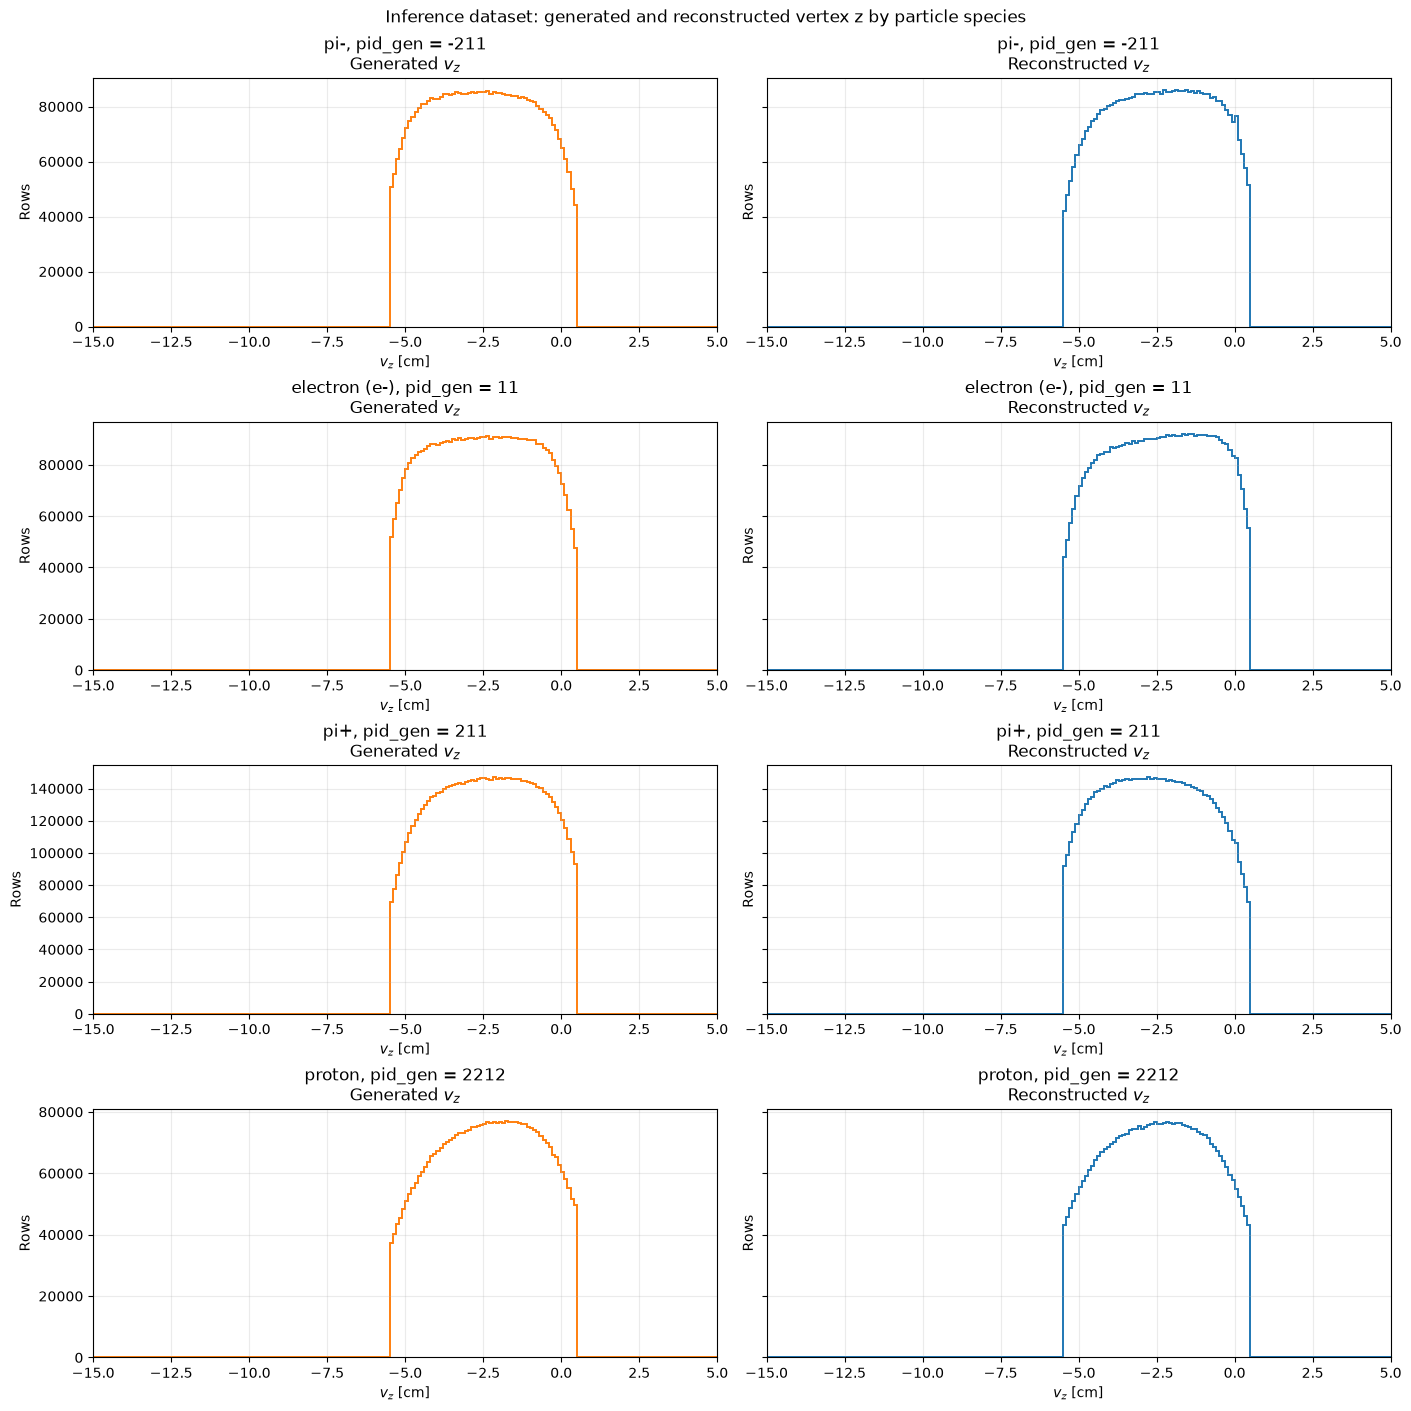

In [11]:
# Compare vz_gen and vz_rec for every generated particle species.
INFERENCE_VZ_COLUMNS = ["pid_gen", "vz_gen", "vz_rec"]
INFERENCE_VZ_BINS = np.linspace(-15.0, 5.0, 201)
INFERENCE_VZ_TICKS = np.arange(-15.0, 5.1, 2.5)
INFERENCE_VZ_GEN_COUNTS = {}
INFERENCE_VZ_REC_COUNTS = {}

for inference_batch in inference_parquet_dataset.scanner(
    columns=INFERENCE_VZ_COLUMNS,
    filter=INFERENCE_GLOBAL_CUT,
    batch_size=250_000,
    use_threads=True,
    batch_readahead=2,
    fragment_readahead=1,
).to_batches():
    inference_vz_df = inference_batch.to_pandas()
    inference_vz_df = inference_vz_df.dropna(subset=["pid_gen"])

    for pid, species_df in inference_vz_df.groupby(
        "pid_gen",
        sort=False,
    ):
        vz_gen_values = species_df["vz_gen"].to_numpy()
        vz_gen_values = vz_gen_values[np.isfinite(vz_gen_values)]
        vz_rec_values = species_df["vz_rec"].to_numpy()
        vz_rec_values = vz_rec_values[np.isfinite(vz_rec_values)]

        vz_gen_histogram, _ = np.histogram(
            vz_gen_values,
            bins=INFERENCE_VZ_BINS,
        )
        vz_rec_histogram, _ = np.histogram(
            vz_rec_values,
            bins=INFERENCE_VZ_BINS,
        )

        INFERENCE_VZ_GEN_COUNTS[pid] = (
            INFERENCE_VZ_GEN_COUNTS.get(pid, 0)
            + vz_gen_histogram
        )
        INFERENCE_VZ_REC_COUNTS[pid] = (
            INFERENCE_VZ_REC_COUNTS.get(pid, 0)
            + vz_rec_histogram
        )

INFERENCE_PARTICLE_NAMES = {
    -211: "pi-",
    11: "electron (e-)",
    211: "pi+",
    2212: "proton",
}
inference_vz_species_pids = sorted(
    set(INFERENCE_VZ_GEN_COUNTS)
    | set(INFERENCE_VZ_REC_COUNTS)
)

# Four particle-species rows x two columns:
# generated vz on the left, reconstructed vz on the right.
figure, axes = plt.subplots(
    len(inference_vz_species_pids),
    2,
    figsize=(14, 3.5 * len(inference_vz_species_pids)),
    sharex=True,
    sharey="row",
    squeeze=False,
    constrained_layout=True,
)

for row_index, pid in enumerate(inference_vz_species_pids):
    particle_name = INFERENCE_PARTICLE_NAMES.get(
        int(pid),
        f"PDG {int(pid)}",
    )
    gen_axis = axes[row_index, 0]
    rec_axis = axes[row_index, 1]

    gen_axis.stairs(
        INFERENCE_VZ_GEN_COUNTS[pid],
        INFERENCE_VZ_BINS,
        color="tab:orange",
        linewidth=1.4,
    )
    rec_axis.stairs(
        INFERENCE_VZ_REC_COUNTS[pid],
        INFERENCE_VZ_BINS,
        color="tab:blue",
        linewidth=1.4,
    )

    gen_axis.set_title(
        f"{particle_name}, pid_gen = {int(pid)}\n"
        r"Generated $v_z$"
    )
    rec_axis.set_title(
        f"{particle_name}, pid_gen = {int(pid)}\n"
        r"Reconstructed $v_z$"
    )

    for axis in (gen_axis, rec_axis):
        axis.set_xlabel(r"$v_z$ [cm]")
        axis.set_ylabel("Rows")
        axis.set_xlim(
            INFERENCE_VZ_BINS[0],
            INFERENCE_VZ_BINS[-1],
        )
        axis.set_xticks(INFERENCE_VZ_TICKS)
        axis.tick_params(axis="x", labelbottom=True)
        axis.grid(alpha=0.25)

figure.suptitle(
    "Inference dataset: generated and reconstructed vertex z "
    "by particle species"
)
plt.show()


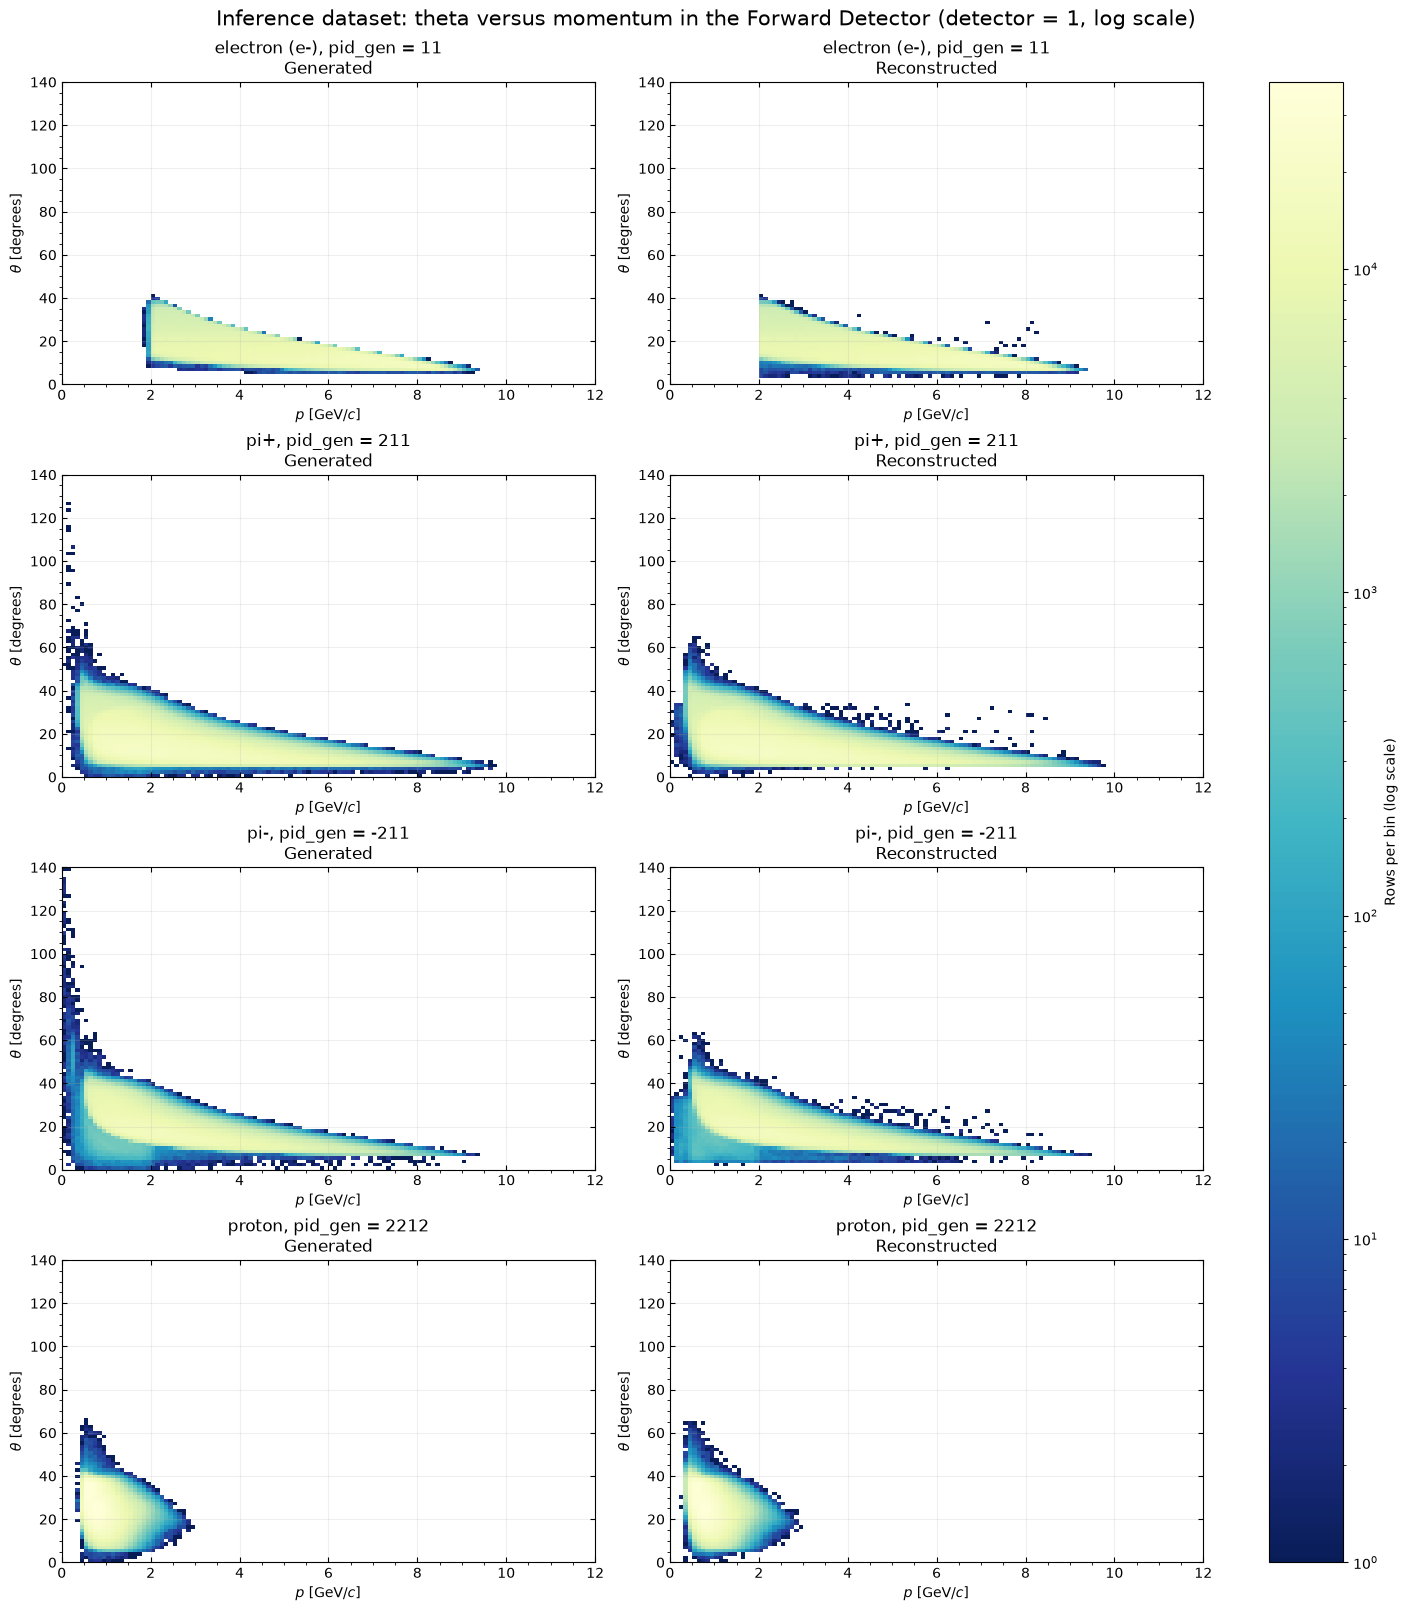

In [12]:


# Forward Detector phase space for all four generated particle species.
# Shared logarithmic color scale across all 8 panels.

INFERENCE_FD_SPECIES_PIDS = [11, 211, -211, 2212]

INFERENCE_FD_PARTICLE_NAMES = {
    11: "electron (e-)",
    211: "pi+",
    -211: "pi-",
    2212: "proton",
}

INFERENCE_FD_PHASE_SPACE_COLUMNS = [
    "pid_gen",
    "p_gen",
    "theta_gen",
    "p_rec",
    "theta_rec",
]

INFERENCE_FD_PHASE_SPACE_PAIRS = [
    ("p_gen", "theta_gen"),
    ("p_rec", "theta_rec"),
]

INFERENCE_FD_PHASE_SPACE_BINS = {
    "p_gen": np.linspace(0.0, 12.0, 121),
    "theta_gen": np.linspace(0.0, 140.0, 91),
    "p_rec": np.linspace(0.0, 12.0, 121),
    "theta_rec": np.linspace(0.0, 140.0, 91),
}

INFERENCE_FD_P_TICKS = np.arange(0.0, 12.1, 2.0)

# Use the complete training-matched inference selection.
INFERENCE_FD_PHASE_SPACE_CUT = (
    INFERENCE_GLOBAL_CUT
    & ds.field("pid_gen").isin(INFERENCE_FD_SPECIES_PIDS)
)

# Initialize histograms.
INFERENCE_FD_PHASE_SPACE_COUNTS = {
    (pid, p_name, theta_name): np.zeros(
        (
            len(INFERENCE_FD_PHASE_SPACE_BINS[theta_name]) - 1,
            len(INFERENCE_FD_PHASE_SPACE_BINS[p_name]) - 1,
        ),
        dtype=np.int64,
    )
    for pid in INFERENCE_FD_SPECIES_PIDS
    for p_name, theta_name in INFERENCE_FD_PHASE_SPACE_PAIRS
}

# Fill histograms from Parquet batches.
for inference_batch in inference_parquet_dataset.scanner(
    columns=INFERENCE_FD_PHASE_SPACE_COLUMNS,
    filter=INFERENCE_FD_PHASE_SPACE_CUT,
    batch_size=250_000,
    use_threads=True,
    batch_readahead=2,
    fragment_readahead=1,
).to_batches():

    inference_phase_space_df = inference_batch.to_pandas()

    for pid, species_df in inference_phase_space_df.groupby(
        "pid_gen",
        sort=False,
    ):
        pid = int(pid)

        for p_name, theta_name in INFERENCE_FD_PHASE_SPACE_PAIRS:
            valid = (
                np.isfinite(species_df[p_name])
                & np.isfinite(species_df[theta_name])
            )

            histogram, _, _ = np.histogram2d(
                species_df.loc[valid, theta_name],
                species_df.loc[valid, p_name],
                bins=[
                    INFERENCE_FD_PHASE_SPACE_BINS[theta_name],
                    INFERENCE_FD_PHASE_SPACE_BINS[p_name],
                ],
            )

            INFERENCE_FD_PHASE_SPACE_COUNTS[
                (pid, p_name, theta_name)
            ] += histogram.astype(np.int64)

# ---------------------------------------------------------
# Shared logarithmic color normalization across all panels
# ---------------------------------------------------------

inference_phase_space_max = max(
    counts.max()
    for counts in INFERENCE_FD_PHASE_SPACE_COUNTS.values()
)

inference_phase_space_norm = LogNorm(
    vmin=1,
    vmax=max(2, inference_phase_space_max),
)

inference_phase_space_cmap = (
    plt.colormaps["YlGnBu_r"].with_extremes(bad="white")
)

# ---------------------------------------------------------
# Plot 4 species x 2 kinematic representations
# ---------------------------------------------------------

figure, axes = plt.subplots(
    len(INFERENCE_FD_SPECIES_PIDS),
    2,
    figsize=(14, 4 * len(INFERENCE_FD_SPECIES_PIDS)),
    sharex="col",
    sharey="col",
    squeeze=False,
    constrained_layout=True,
)

for row, pid in enumerate(INFERENCE_FD_SPECIES_PIDS):
    particle_name = INFERENCE_FD_PARTICLE_NAMES[pid]

    for column, (p_name, theta_name) in enumerate(
        INFERENCE_FD_PHASE_SPACE_PAIRS
    ):
        axis = axes[row, column]

        counts = INFERENCE_FD_PHASE_SPACE_COUNTS[
            (pid, p_name, theta_name)
        ]

        image = axis.pcolormesh(
            INFERENCE_FD_PHASE_SPACE_BINS[p_name],
            INFERENCE_FD_PHASE_SPACE_BINS[theta_name],
            np.ma.masked_less(counts, 1),
            shading="auto",
            cmap=inference_phase_space_cmap,
            norm=inference_phase_space_norm,
        )

        kinematics = (
            "Generated" if column == 0 else "Reconstructed"
        )

        axis.set_title(
            f"{particle_name}, pid_gen = {pid}\n{kinematics}"
        )

        axis.set_xlabel(r"$p$ [GeV/$c$]")
        axis.set_ylabel(r"$\theta$ [degrees]")

        axis.set_xlim(0.0, 12.0)
        axis.set_xticks(INFERENCE_FD_P_TICKS)

        axis.tick_params(
            axis="both",
            direction="in",
            top=True,
            right=True,
            labelbottom=True,
        )

        axis.minorticks_on()
        axis.grid(alpha=0.2)

# Shared logarithmic colorbar.
figure.colorbar(
    image,
    ax=axes.ravel().tolist(),
    label="Rows per bin (log scale)",
)

figure.suptitle(
    "Inference dataset: theta versus momentum in the "
    "Forward Detector (detector = 1, log scale)",
    fontsize=15,
)

plt.show()

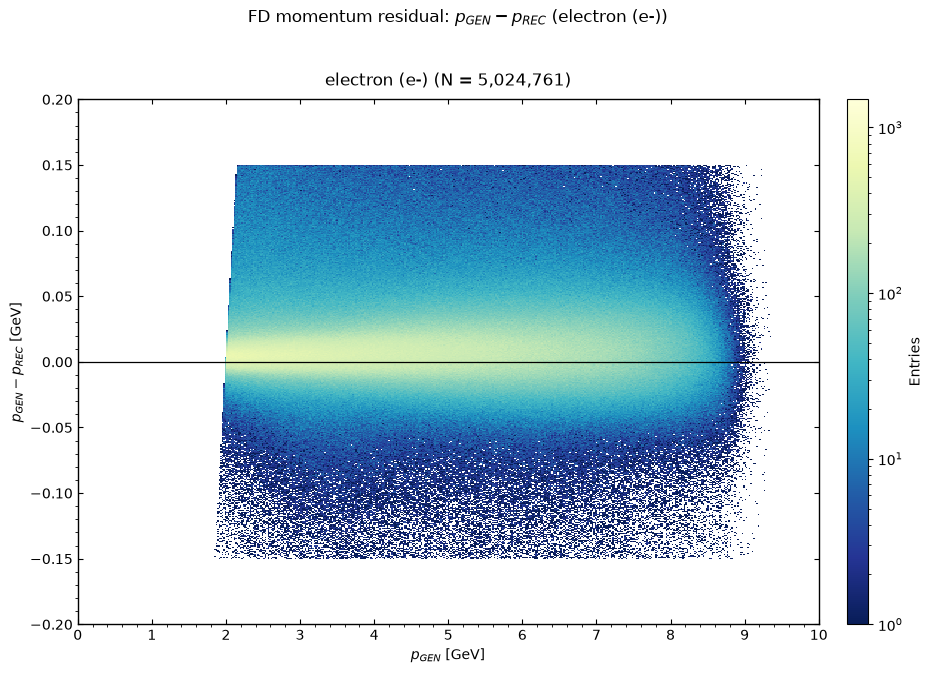

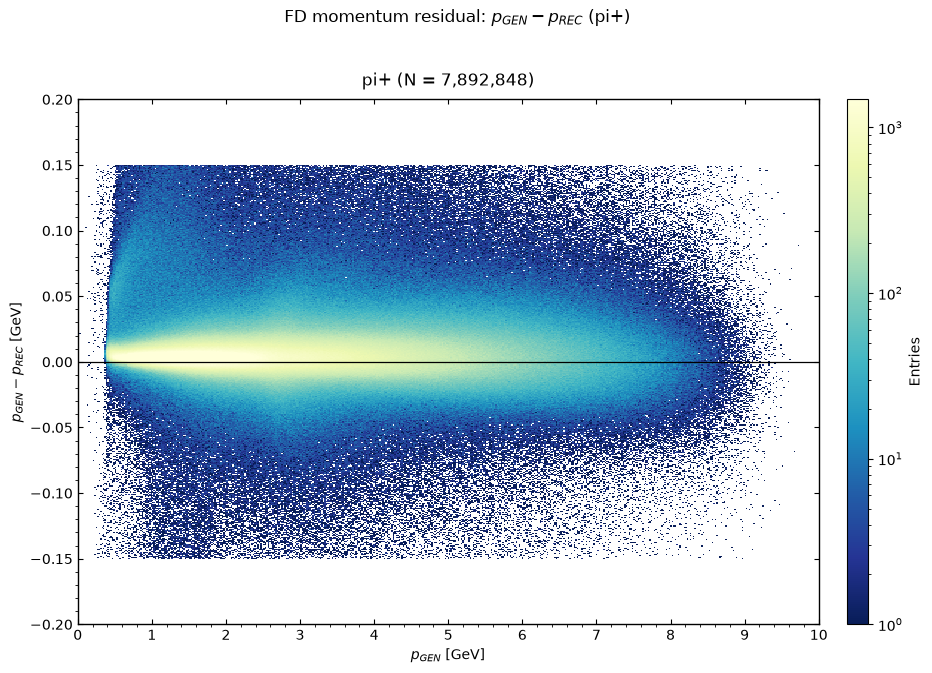

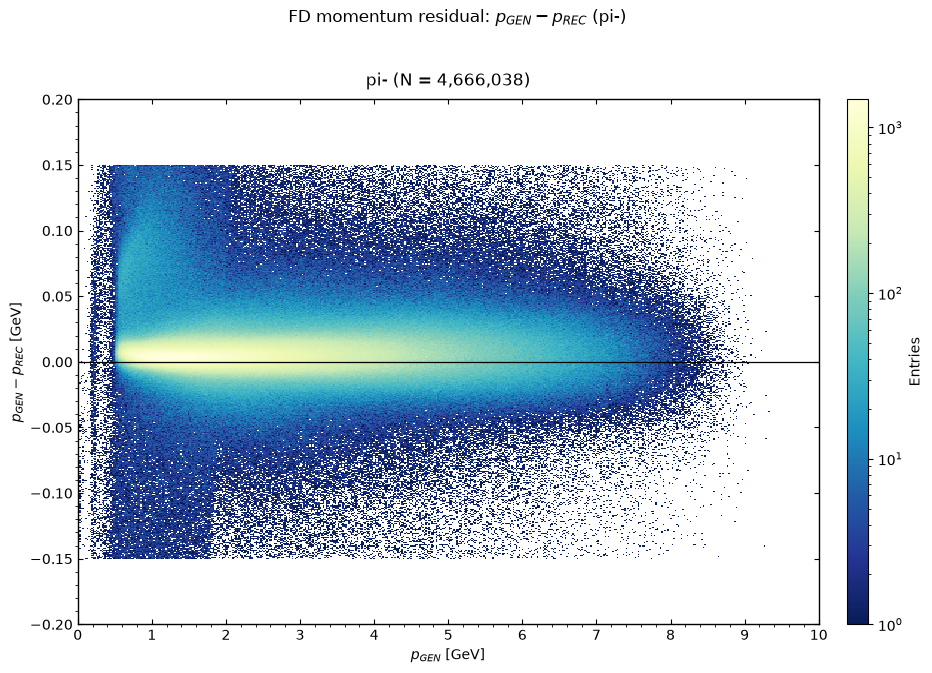

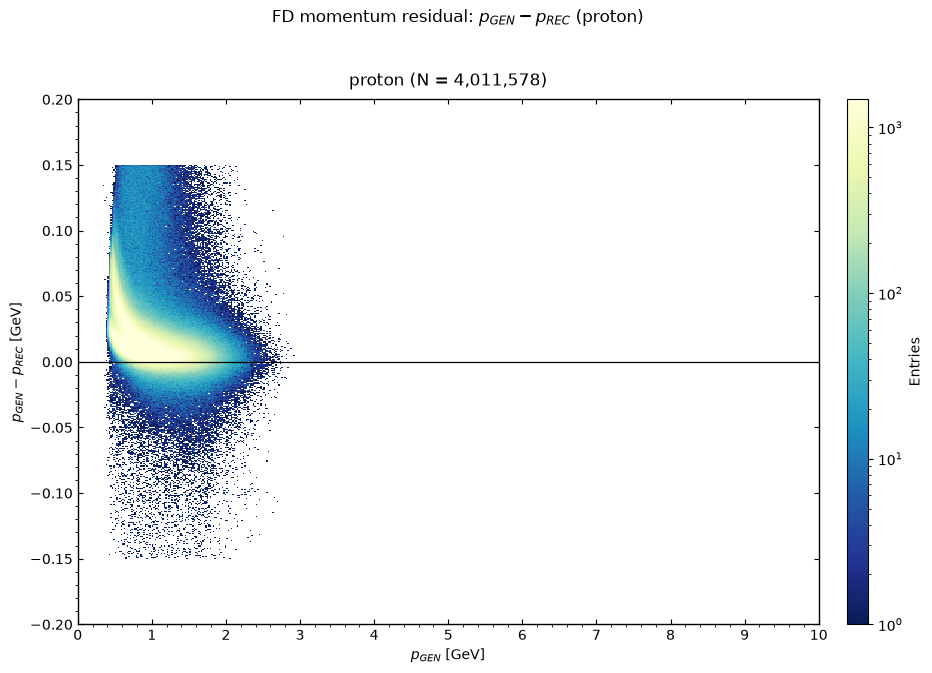

In [13]:
# Delta p versus generated momentum in the Forward Detector for all four species.
INFERENCE_FD_DELTAP_PARTICLES = {
    11: "electron (e-)",
    211: "pi+",
    -211: "pi-",
    2212: "proton",
}
INFERENCE_FD_DELTAP_COLUMNS = [
    "pid_gen",
    "p_gen",
    "delta_p",
]
INFERENCE_FD_DELTAP_X_BINS = np.linspace(0.0, 10.0, 500)
INFERENCE_FD_DELTAP_Y_LIMITS = (-0.2, 0.2)
INFERENCE_FD_DELTAP_Y_BINS = np.linspace(
    *INFERENCE_FD_DELTAP_Y_LIMITS,
    500,
)
INFERENCE_FD_DELTAP_Y_TICKS = np.arange(
    -0.2,
    0.201,
    0.05,
)
INFERENCE_FD_DELTAP_COUNTS = {
    pid: np.zeros(
        (
            len(INFERENCE_FD_DELTAP_Y_BINS) - 1,
            len(INFERENCE_FD_DELTAP_X_BINS) - 1,
        ),
        dtype=np.int64,
    )
    for pid in INFERENCE_FD_DELTAP_PARTICLES
}
INFERENCE_FD_DELTAP_ROW_COUNTS = {
    pid: 0 for pid in INFERENCE_FD_DELTAP_PARTICLES
}

# Use the complete training-matched inference selection.
INFERENCE_FD_DELTAP_CUT = (
    INFERENCE_GLOBAL_CUT
    & ds.field("pid_gen").isin(
        list(INFERENCE_FD_DELTAP_PARTICLES)
    )
)

for inference_batch in inference_parquet_dataset.scanner(
    columns=INFERENCE_FD_DELTAP_COLUMNS,
    filter=INFERENCE_FD_DELTAP_CUT,
    batch_size=250_000,
    use_threads=True,
    batch_readahead=2,
    fragment_readahead=1,
).to_batches():
    inference_delta_p_df = inference_batch.to_pandas()
    valid = (
        inference_delta_p_df["pid_gen"].isin(
            INFERENCE_FD_DELTAP_PARTICLES
        )
        & np.isfinite(inference_delta_p_df["p_gen"])
        & np.isfinite(inference_delta_p_df["delta_p"])
    )
    inference_delta_p_df = inference_delta_p_df.loc[valid]

    for pid in INFERENCE_FD_DELTAP_PARTICLES:
        species_df = inference_delta_p_df[
            inference_delta_p_df["pid_gen"] == pid
        ]
        INFERENCE_FD_DELTAP_ROW_COUNTS[pid] += len(species_df)

        histogram, _, _ = np.histogram2d(
            species_df["delta_p"],
            species_df["p_gen"],
            bins=[
                INFERENCE_FD_DELTAP_Y_BINS,
                INFERENCE_FD_DELTAP_X_BINS,
            ],
        )
        INFERENCE_FD_DELTAP_COUNTS[pid] += (
            histogram.astype(np.int64)
        )

inference_fd_positive_counts = np.concatenate(
    [
        counts[counts > 0]
        for counts in INFERENCE_FD_DELTAP_COUNTS.values()
    ]
)
inference_fd_colorbar_max = max(
    1,
    np.percentile(inference_fd_positive_counts, 99.5),
)
inference_fd_delta_p_cmap = (
    plt.colormaps["YlGnBu_r"].with_extremes(bad="white")
)

# Use the same linear-scale plotting style as the earlier plots.
for pid, particle_name in INFERENCE_FD_DELTAP_PARTICLES.items():
    figure, axis = plt.subplots(
        1,
        1,
        figsize=(9.5, 7.5),
        facecolor="white",
    )
    from matplotlib.colors import LogNorm

    image = axis.pcolormesh(
        INFERENCE_FD_DELTAP_X_BINS,
        INFERENCE_FD_DELTAP_Y_BINS,
        np.ma.masked_less(
            INFERENCE_FD_DELTAP_COUNTS[pid],
            1,
        ),
        shading="auto",
        cmap=inference_fd_delta_p_cmap,
        norm=LogNorm(vmin=1, vmax=max(2, inference_fd_colorbar_max)),
    )
    axis.axhline(0.0, color="black", linewidth=0.9)
    axis.set_title(
        f"{particle_name} "
        f"(N = {INFERENCE_FD_DELTAP_ROW_COUNTS[pid]:,})",
        pad=10,
    )
    axis.set_xlabel(r"$p_{GEN}$ [GeV]")
    axis.set_ylabel(r"$p_{GEN} - p_{REC}$ [GeV]")
    axis.set_xlim(0.0, 10.0)
    axis.set_ylim(*INFERENCE_FD_DELTAP_Y_LIMITS)
    axis.set_xticks(np.arange(0.0, 10.1, 1.0))
    axis.set_yticks(INFERENCE_FD_DELTAP_Y_TICKS)
    axis.tick_params(
        axis="both",
        direction="in",
        top=True,
        right=True,
        labelleft=True,
    )
    axis.minorticks_on()
    axis.grid(False)

    for spine in axis.spines.values():
        spine.set_linewidth(1.0)

    figure.subplots_adjust(
        left=0.10,
        right=0.88,
        bottom=0.14,
        top=0.84,
    )
    colorbar_axis = figure.add_axes(
        [0.91, 0.14, 0.022, 0.70]
    )
    figure.colorbar(
        image,
        cax=colorbar_axis,
        label="Entries",
    )
    figure.suptitle(
        rf"FD momentum residual: "
        rf"$p_{{GEN}} - p_{{REC}}$ ({particle_name})",
        y=0.96,
    )
    figure.patch.set_facecolor("white")
    plt.show()


In [14]:
# Apply the trained proton model to reconstructed FD protons in batches.
if "xgb_proton" not in globals():
    raise NameError("Run the model-loading cell first to define xgb_proton.")
if "fit_gaussian_peak_one_sigma" not in globals():
    raise NameError(
        "Run the inference fit-helpers cell first to define "
        "fit_gaussian_peak_one_sigma."
    )

INFERENCE_PROTON_PID = 2212
INFERENCE_PROTON_COLUMNS = [
    "p_gen",
    "p_rec",
    "theta_rec",
    "phi_rec",
]
INFERENCE_PROTON_CUT = (
    INFERENCE_GLOBAL_CUT
    & (ds.field("pid_gen") == INFERENCE_PROTON_PID)
)

# Same plotting range and p_gen fit bins used for the proton diagnostics.
INFERENCE_PROTON_DELTAP_X_BINS = np.linspace(0.0, 10.0, 500)
INFERENCE_PROTON_DELTAP_Y_LIMITS = (-0.2, 0.2)
INFERENCE_PROTON_DELTAP_Y_BINS = np.linspace(
    *INFERENCE_PROTON_DELTAP_Y_LIMITS,
    500,
)
INFERENCE_PROTON_MOMENTUM_MIN = 0.40
INFERENCE_PROTON_MOMENTUM_MAX = 2.75
INFERENCE_PROTON_MOMENTUM_BIN_WIDTH = 0.25

INFERENCE_PROTON_MOMENTUM_EDGES = np.concatenate(
    [
        np.array([
            0.40,
            0.45,
            0.50,
            0.55,
            0.60,
        ]),
        np.arange(
            0.60,
            INFERENCE_PROTON_MOMENTUM_MAX,
            0.25,
        ),
    ]
)

INFERENCE_PROTON_CORRECTED_COUNTS = np.zeros(
    (
        len(INFERENCE_PROTON_DELTAP_Y_BINS) - 1,
        len(INFERENCE_PROTON_DELTAP_X_BINS) - 1,
    ),
    dtype=np.int64,
)
INFERENCE_PROTON_BEFORE_BY_BIN = {
    bin_index: []
    for bin_index in range(
        len(INFERENCE_PROTON_MOMENTUM_EDGES) - 1
    )
}
INFERENCE_PROTON_AFTER_BY_BIN = {
    bin_index: []
    for bin_index in range(
        len(INFERENCE_PROTON_MOMENTUM_EDGES) - 1
    )
}
inference_proton_rows = 0

for inference_batch in inference_parquet_dataset.scanner(
    columns=INFERENCE_PROTON_COLUMNS,
    filter=INFERENCE_PROTON_CUT,
    batch_size=250_000,
    use_threads=True,
    batch_readahead=2,
    fragment_readahead=1,
).to_batches():
    inference_proton_df = inference_batch.to_pandas()
    valid = np.all(
        np.isfinite(
            inference_proton_df[
                ["p_gen", "p_rec", "theta_rec", "phi_rec"]
            ]
        ),
        axis=1,
    )
    inference_proton_df = inference_proton_df.loc[valid]
    if inference_proton_df.empty:
        continue

    inference_proton_features = inference_proton_df[
        ["p_rec", "theta_rec", "phi_rec"]
    ]
    inference_proton_delta_p_pred = xgb_proton.predict(
        inference_proton_features
    )
    inference_proton_delta_p_before = (
        inference_proton_df["p_gen"].to_numpy()
        - inference_proton_df["p_rec"].to_numpy()
    )
    inference_proton_delta_p_after = (
        inference_proton_delta_p_before
        - inference_proton_delta_p_pred
    )
    inference_proton_p_gen = (
        inference_proton_df["p_gen"].to_numpy()
    )
    inference_proton_p_rec = (
        inference_proton_df["p_rec"].to_numpy()
    )
    inference_proton_rows += len(inference_proton_df)

    histogram, _, _ = np.histogram2d(
        inference_proton_delta_p_after,
        inference_proton_p_gen,
        bins=[
            INFERENCE_PROTON_DELTAP_Y_BINS,
            INFERENCE_PROTON_DELTAP_X_BINS,
        ],
    )
    INFERENCE_PROTON_CORRECTED_COUNTS += (
        histogram.astype(np.int64)
    )

    inference_proton_p_gen_bin_indices = (
        np.searchsorted(
            INFERENCE_PROTON_MOMENTUM_EDGES,
            inference_proton_p_gen,
            side="right",
        )
        - 1
    )
    for bin_index in range(
        len(INFERENCE_PROTON_MOMENTUM_EDGES) - 1
    ):
        bin_mask = inference_proton_p_gen_bin_indices == bin_index
        if not np.any(bin_mask):
            continue
        INFERENCE_PROTON_BEFORE_BY_BIN[bin_index].append(
            inference_proton_delta_p_before[bin_mask].astype(
                np.float32,
                copy=True,
            )
        )
        INFERENCE_PROTON_AFTER_BY_BIN[bin_index].append(
            inference_proton_delta_p_after[bin_mask].astype(
                np.float32,
                copy=True,
            )
        )

print(
    "FD reconstructed proton rows processed: "
    f"{inference_proton_rows:,}"
)
print(
    "Features used: p_rec, theta_rec, phi_rec; "
    "model: xgb_proton"
)


FD reconstructed proton rows processed: 4,011,578
Features used: p_rec, theta_rec, phi_rec; model: xgb_proton


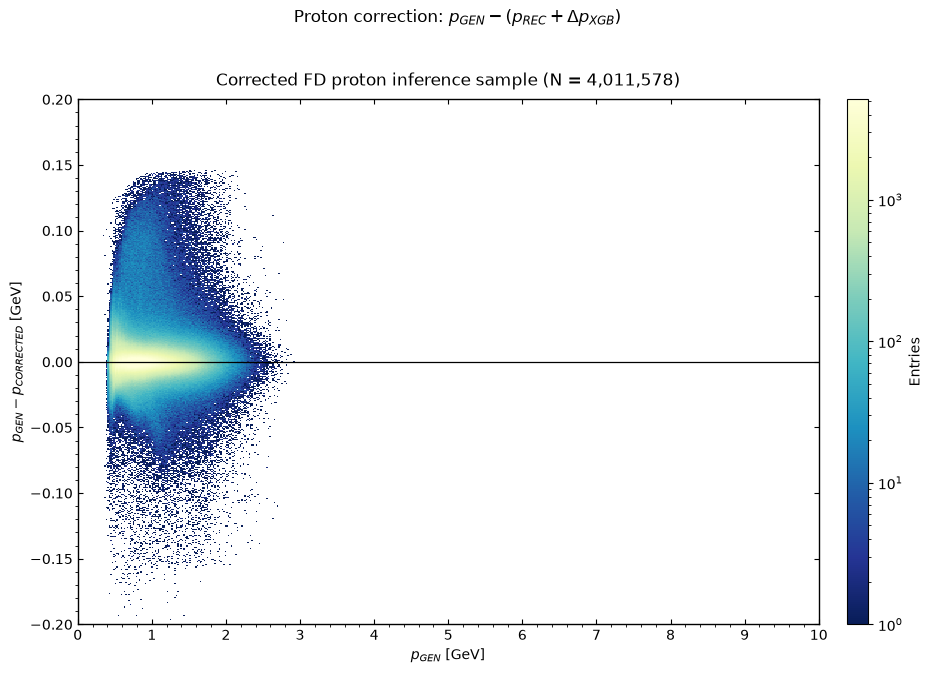

In [15]:
# Corrected delta_p versus p_gen for the inference proton sample.
inference_proton_positive_counts = (
    INFERENCE_PROTON_CORRECTED_COUNTS[
        INFERENCE_PROTON_CORRECTED_COUNTS > 0
    ]
)
inference_proton_colorbar_max = max(
    1,
    np.percentile(inference_proton_positive_counts, 99.5),
)
inference_proton_cmap = (
    plt.colormaps["YlGnBu_r"].with_extremes(bad="white")
)

figure, axis = plt.subplots(
    1,
    1,
    figsize=(9.5, 7.5),
    facecolor="white",
)
image = axis.pcolormesh(
    INFERENCE_PROTON_DELTAP_X_BINS,
    INFERENCE_PROTON_DELTAP_Y_BINS,
    np.ma.masked_less(
        INFERENCE_PROTON_CORRECTED_COUNTS,
        1,
    ),
    shading="auto",
    cmap=inference_proton_cmap,
    norm=LogNorm(vmin=1, vmax=inference_proton_colorbar_max),
)
axis.axhline(0.0, color="black", linewidth=0.9)
axis.set_title(
    "Corrected FD proton inference sample "
    f"(N = {inference_proton_rows:,})",
    pad=10,
)
axis.set_xlabel(r"$p_{GEN}$ [GeV]")
axis.set_ylabel(r"$p_{GEN} - p_{CORRECTED}$ [GeV]")
axis.set_xlim(0.0, 10.0)
axis.set_ylim(*INFERENCE_PROTON_DELTAP_Y_LIMITS)
axis.set_xticks(np.arange(0.0, 10.1, 1.0))
axis.set_yticks(np.arange(-0.2, 0.201, 0.05))
axis.tick_params(
    axis="both",
    direction="in",
    top=True,
    right=True,
    labelleft=True,
)
axis.minorticks_on()
axis.grid(False)

for spine in axis.spines.values():
    spine.set_linewidth(1.0)

figure.subplots_adjust(
    left=0.10,
    right=0.88,
    bottom=0.14,
    top=0.84,
)
colorbar_axis = figure.add_axes(
    [0.91, 0.14, 0.022, 0.70]
)
figure.colorbar(
    image,
    cax=colorbar_axis,
    label="Entries",
    
)
figure.suptitle(
    r"Proton correction: "
    r"$p_{GEN} - (p_{REC} + \Delta p_{XGB})$",
    y=0.96,
)
figure.patch.set_facecolor("white")
plt.show()


Empty inference proton momentum bin: 0.60-0.60 GeV/c


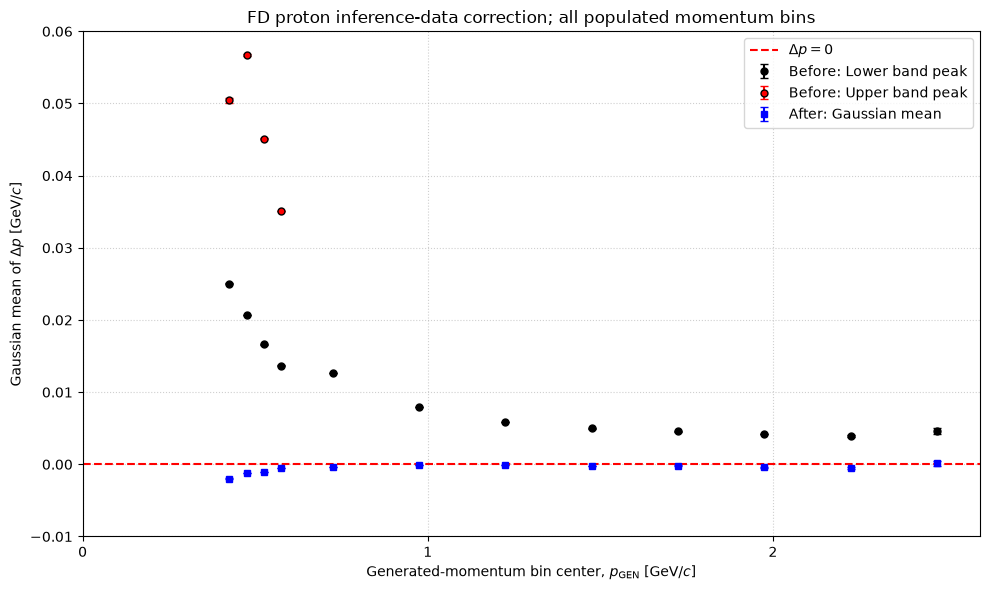

In [16]:
# Gaussian means before/after proton correction versus p_gen.
# The first four bins use two Gaussian peaks before correction.

from scipy.optimize import curve_fit


def gaussian_component(x, amplitude, mean, sigma):
    return amplitude * np.exp(
        -0.5 * ((x - mean) / sigma) ** 2
    )


def two_gaussian_components(
    x,
    main_amplitude,
    main_mean,
    main_sigma,
    secondary_amplitude,
    secondary_mean,
    secondary_sigma,
):
    return (
        gaussian_component(
            x,
            main_amplitude,
            main_mean,
            main_sigma,
        )
        + gaussian_component(
            x,
            secondary_amplitude,
            secondary_mean,
            secondary_sigma,
        )
    )


def fit_two_proton_peaks(values):
    values = np.asarray(values)
    values = values[np.isfinite(values)]

    histogram_edges = np.linspace(-0.2, 0.2, 201)
    counts, edges = np.histogram(
        values,
        bins=histogram_edges,
    )
    centers = 0.5 * (edges[:-1] + edges[1:])

    fit_mask = (
        (centers >= -0.03)
        & (centers <= 0.12)
    )
    fit_x = centers[fit_mask]
    fit_y = counts[fit_mask].astype(float)

    main_index = np.argmax(fit_y)
    main_mean_initial = fit_x[main_index]
    main_amplitude_initial = fit_y[main_index]

    secondary_mask = (
        fit_x >= main_mean_initial + 0.015
    )
    secondary_x = fit_x[secondary_mask]
    secondary_y = fit_y[secondary_mask]

    if len(secondary_x) == 0:
        return None

    secondary_index = np.argmax(secondary_y)
    secondary_mean_initial = secondary_x[secondary_index]
    secondary_amplitude_initial = max(
        secondary_y[secondary_index],
        1.0,
    )

    parameters, covariance = curve_fit(
        two_gaussian_components,
        fit_x,
        fit_y,
        p0=[
            main_amplitude_initial,
            main_mean_initial,
            0.006,
            secondary_amplitude_initial,
            secondary_mean_initial,
            0.015,
        ],
        bounds=(
            [
                0.0,
                main_mean_initial - 0.015,
                0.001,
                0.0,
                main_mean_initial + 0.010,
                0.002,
            ],
            [
                np.inf,
                main_mean_initial + 0.015,
                0.030,
                np.inf,
                0.12,
                0.050,
            ],
        ),
        sigma=np.sqrt(np.maximum(fit_y, 1.0)),
        absolute_sigma=True,
        maxfev=50_000,
    )

    parameter_errors = np.sqrt(
        np.clip(np.diag(covariance), 0.0, None)
    )

    return {
        "mean": parameters[1],
        "mean_error": parameter_errors[1],
        "sigma": parameters[2],
        "sigma_error": parameter_errors[2],
        "secondary_mean": parameters[4],
        "secondary_mean_error": parameter_errors[4],
        "secondary_sigma": parameters[5],
        "secondary_sigma_error": parameter_errors[5],
    }


inference_proton_fit_records = []

for bin_index, (p_low, p_high) in enumerate(
    zip(
        INFERENCE_PROTON_MOMENTUM_EDGES[:-1],
        INFERENCE_PROTON_MOMENTUM_EDGES[1:],
    )
):
    before_chunks = INFERENCE_PROTON_BEFORE_BY_BIN[bin_index]
    after_chunks = INFERENCE_PROTON_AFTER_BY_BIN[bin_index]

    if not before_chunks or not after_chunks:
        print(
            "Empty inference proton momentum bin: "
            f"{p_low:.2f}-{p_high:.2f} GeV/c"
        )
        continue

    delta_p_before_values = np.concatenate(before_chunks)
    delta_p_after_values = np.concatenate(after_chunks)

    # Two peaks before correction in the first four bins.
    if p_high <= 0.60 + 1e-9:
        before_fit = fit_two_proton_peaks(
            delta_p_before_values
        )
        secondary_mean = before_fit["secondary_mean"]
        secondary_mean_error = before_fit[
            "secondary_mean_error"
        ]
    else:
        before_fit = fit_gaussian_peak_one_sigma(
            delta_p_before_values
        )
        secondary_mean = np.nan
        secondary_mean_error = np.nan

    # One corrected peak in every bin.
    after_fit = fit_gaussian_peak_one_sigma(
        delta_p_after_values
    )

    if before_fit is None or after_fit is None:
        raise RuntimeError(
            "Could not fit populated inference proton bin "
            f"{p_low:.2f}-{p_high:.2f} GeV/c"
        )

    inference_proton_fit_records.append(
        {
            "p_low": p_low,
            "p_high": p_high,
            "p_center": 0.5 * (p_low + p_high),
            "entries": len(delta_p_before_values),
            "before_mean": before_fit["mean"],
            "before_mean_error": before_fit["mean_error"],
            "secondary_before_mean": secondary_mean,
            "secondary_before_mean_error": secondary_mean_error,
            "before_sigma": before_fit["sigma"],
            "before_sigma_error": before_fit["sigma_error"],
            "after_mean": after_fit["mean"],
            "after_mean_error": after_fit["mean_error"],
            "after_sigma": after_fit["sigma"],
            "after_sigma_error": after_fit["sigma_error"],
        }
    )

inference_proton_gaussian_means = pd.DataFrame(
    inference_proton_fit_records
)

secondary_peak_mask = (
    inference_proton_gaussian_means[
        "secondary_before_mean"
    ].notna()
)

# Gaussian means.
figure, axis = plt.subplots(figsize=(10, 6))

axis.errorbar(
    inference_proton_gaussian_means["p_center"],
    inference_proton_gaussian_means["before_mean"],
    yerr=inference_proton_gaussian_means[
        "before_mean_error"
    ],
    fmt="o",
    color="black",
    markersize=5,
    capsize=3,
    linestyle="none",
    label="Before: Lower band peak",
)

axis.errorbar(
    inference_proton_gaussian_means.loc[
        secondary_peak_mask,
        "p_center",
    ],
    inference_proton_gaussian_means.loc[
        secondary_peak_mask,
        "secondary_before_mean",
    ],
    yerr=inference_proton_gaussian_means.loc[
        secondary_peak_mask,
        "secondary_before_mean_error",
    ],
    fmt="o",
    color="red",
    markeredgecolor="black",
    markersize=5,
    capsize=3,
    linestyle="none",
    label="Before: Upper band peak",
)

axis.errorbar(
    inference_proton_gaussian_means["p_center"],
    inference_proton_gaussian_means["after_mean"],
    yerr=inference_proton_gaussian_means[
        "after_mean_error"
    ],
    fmt="s",
    color="blue",
    markersize=5,
    capsize=3,
    linestyle="none",
    label="After: Gaussian mean",
)

axis.axhline(
    0.0,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=r"$\Delta p=0$",
)

axis.set_xticks(np.arange(0.0, 7.0, 1.0))
axis.set_xlim(
    0.0,
    INFERENCE_PROTON_MOMENTUM_EDGES[-1],
)
axis.set_ylim(bottom=-0.01, top=0.06)
axis.set_xlabel(
    r"Generated-momentum bin center, "
    r"$p_{\rm GEN}$ [GeV/$c$]"
)
axis.set_ylabel(
    r"Gaussian mean of $\Delta p$ [GeV/$c$]"
)
axis.set_title(
    "FD proton inference-data correction; "
    "all populated momentum bins"
)
axis.grid(True, linestyle=":", alpha=0.6)
axis.legend()
figure.tight_layout()
plt.show()




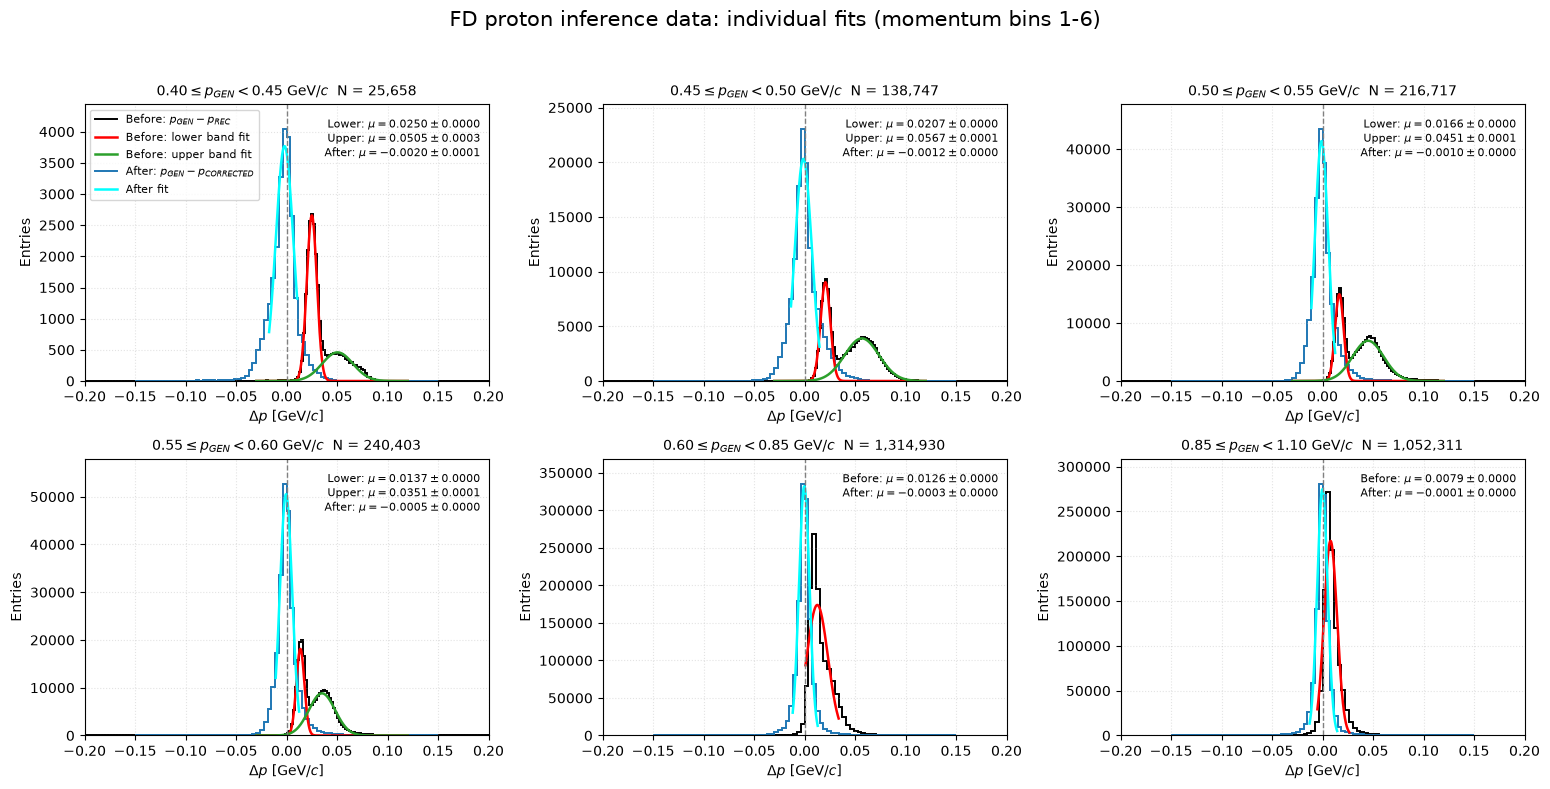

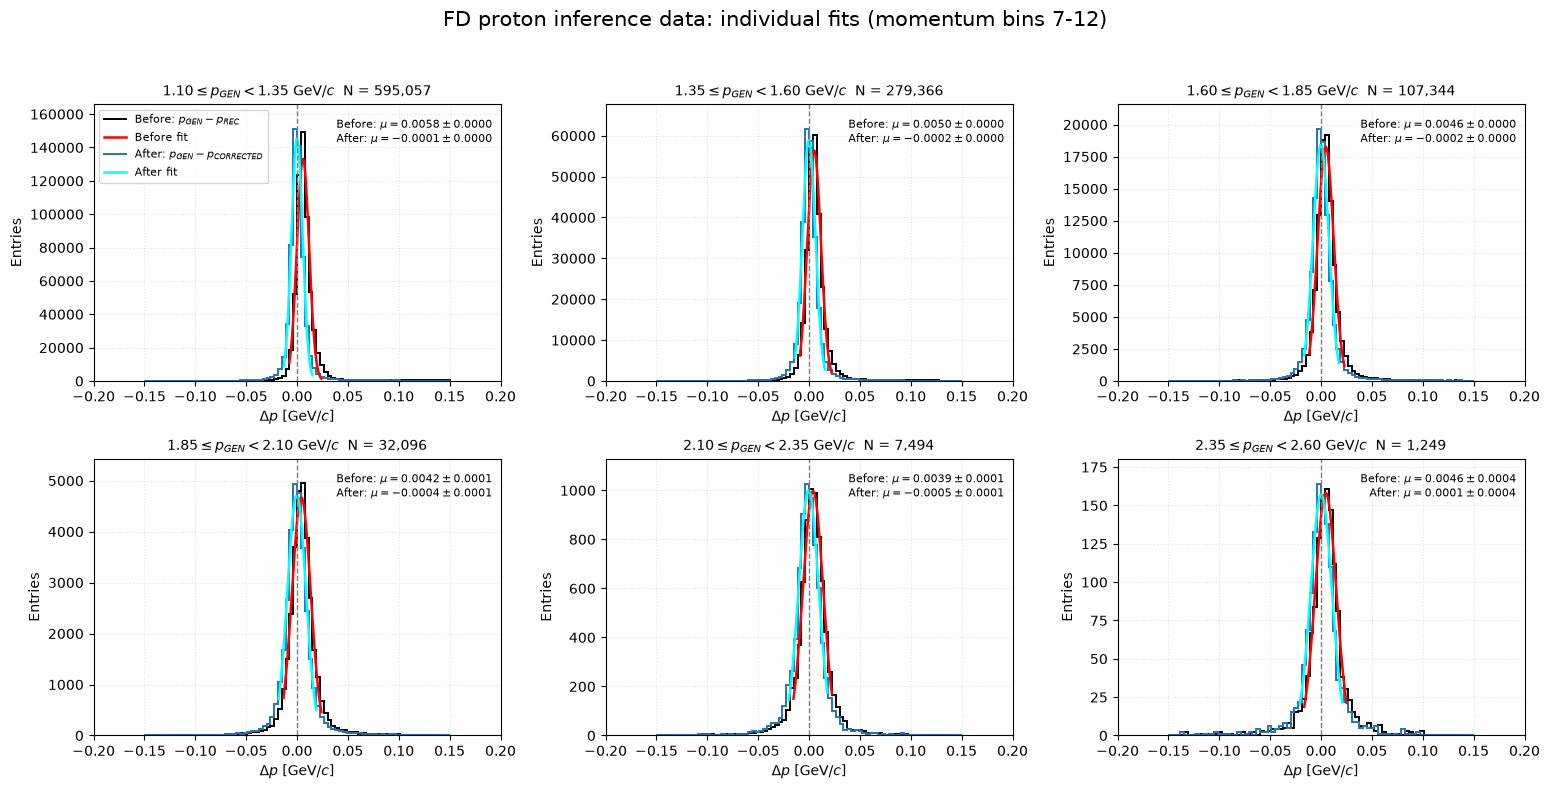

In [17]:
# Individual proton fits across the exact bins used in the Gaussian-mean plot.
# Low four bins: two uncorrected Gaussian components. All later bins: one.

def fit_proton_double_peak(values):
    edges = np.linspace(-0.2, 0.2, 201)
    counts, _ = np.histogram(values[np.isfinite(values)], bins=edges)
    centers = 0.5 * (edges[:-1] + edges[1:])
    mask = (centers >= -0.03) & (centers <= 0.12)
    x, y = centers[mask], counts[mask].astype(float)
    main_index = np.argmax(y)
    main_mean, main_height = x[main_index], y[main_index]
    secondary_mask = x >= main_mean + 0.015
    secondary_x, secondary_y = x[secondary_mask], y[secondary_mask]
    secondary_index = np.argmax(secondary_y)
    secondary_mean = secondary_x[secondary_index]
    secondary_height = max(secondary_y[secondary_index], 1.0)
    parameters, covariance = curve_fit(
        two_gaussian_components, x, y,
        p0=[main_height, main_mean, 0.006, secondary_height, secondary_mean, 0.015],
        bounds=([0, main_mean - 0.015, 0.001, 0, main_mean + 0.010, 0.002],
                [np.inf, main_mean + 0.015, 0.030, np.inf, 0.12, 0.050]),
        sigma=np.sqrt(np.maximum(y, 1.0)), absolute_sigma=True, maxfev=50_000,
    )
    errors = np.sqrt(np.clip(np.diag(covariance), 0.0, None))
    return counts, edges, parameters, errors


proton_fit_panels = []
for bin_index, (p_low, p_high) in enumerate(zip(INFERENCE_PROTON_MOMENTUM_EDGES[:-1], INFERENCE_PROTON_MOMENTUM_EDGES[1:])):
    before_chunks = INFERENCE_PROTON_BEFORE_BY_BIN[bin_index]
    after_chunks = INFERENCE_PROTON_AFTER_BY_BIN[bin_index]
    if not before_chunks or not after_chunks:
        continue
    before_values = np.concatenate(before_chunks)
    after_values = np.concatenate(after_chunks)
    double_peak = p_high <= 0.60 + 1e-9
    before = fit_proton_double_peak(before_values) if double_peak else fit_gaussian_peak_one_sigma(before_values)
    after = fit_gaussian_peak_one_sigma(after_values)
    if before is None or after is None:
        raise RuntimeError(f"Could not fit proton bin {p_low:.2f}-{p_high:.2f} GeV/c")
    proton_fit_panels.append((p_low, p_high, len(before_values), double_peak, before, after))


PROTON_FITS_PER_FIGURE = 6
for page_start in range(0, len(proton_fit_panels), PROTON_FITS_PER_FIGURE):
    page_panels = proton_fit_panels[page_start:page_start + PROTON_FITS_PER_FIGURE]
    figure, axes = plt.subplots(2, 3, figsize=(15.6, 8.0), squeeze=False)
    for axis, (p_low, p_high, entries, double_peak, before, after) in zip(axes.ravel(), page_panels):
        if double_peak:
            before_counts, before_edges, before_parameters, before_errors = before
            axis.stairs(before_counts, before_edges, color="black", linewidth=1.4, label=r"Before: $p_{GEN}-p_{REC}$")
            fit_x = np.linspace(-0.03, 0.12, 400)
            axis.plot(fit_x, gaussian_component(fit_x, *before_parameters[:3]), color="red", linewidth=1.8, label="Before: lower band fit")
            axis.plot(fit_x, gaussian_component(fit_x, *before_parameters[3:]), color="tab:green", linewidth=1.8, label="Before: upper band fit")
            before_text = (rf"Lower: $\mu={before_parameters[1]:.4f}\pm{before_errors[1]:.4f}$" + "\n" + rf"Upper: $\mu={before_parameters[4]:.4f}\pm{before_errors[4]:.4f}$")
        else:
            axis.stairs(before["counts"], before["edges"], color="black", linewidth=1.4, label=r"Before: $p_{GEN}-p_{REC}$")
            fit_x = np.linspace(before["fit_low"], before["fit_high"], 400)
            axis.plot(fit_x, gaussian_no_rejection(fit_x, *before["parameters"]), color="red", linewidth=1.8, label="Before fit")
            before_text = rf"Before: $\mu={before['mean']:.4f}\pm{before['mean_error']:.4f}$"
        axis.stairs(after["counts"], after["edges"], color="tab:blue", linewidth=1.4, label=r"After: $p_{GEN}-p_{CORRECTED}$")
        after_x = np.linspace(after["fit_low"], after["fit_high"], 400)
        axis.plot(after_x, gaussian_no_rejection(after_x, *after["parameters"]), color="cyan", linewidth=1.8, label="After fit")
        axis.axvline(0.0, color="gray", linestyle="--", linewidth=1.0)
        axis.set_xlim(-0.2, 0.2)
        axis.set_ylim(0.0, max(1.0, 1.10 * after["counts"].max()))
        axis.set_title(rf"${p_low:.2f} \leq p_{{GEN}} < {p_high:.2f}$ GeV/$c$  N = {entries:,}", fontsize=10)
        axis.set_xlabel(r"$\Delta p$ [GeV/$c$]")
        axis.set_ylabel("Entries")
        axis.grid(True, linestyle=":", alpha=0.35)
        axis.text(0.98, 0.95, before_text + "\n" + rf"After: $\mu={after['mean']:.4f}\pm{after['mean_error']:.4f}$", transform=axis.transAxes, ha="right", va="top", fontsize=8)
    for axis in axes.ravel()[len(page_panels):]:
        axis.set_visible(False)
    axes.flat[0].legend(loc="upper left", fontsize=8)
    page_end = page_start + len(page_panels)
    figure.suptitle(f"FD proton inference data: individual fits (momentum bins {page_start + 1}-{page_end})", fontsize=15)
    figure.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()
    plt.close(figure)

In [18]:
# Apply the trained pi-plus model to reconstructed FD pi-plus rows in batches.
if "xgb_pi_plus" not in globals():
    raise NameError("Run the model-loading cell first to define xgb_pi_plus.")
if "fit_gaussian_peak_one_sigma" not in globals():
    raise NameError(
        "Run the inference fit-helpers cell first to define "
        "fit_gaussian_peak_one_sigma."
    )

INFERENCE_PI_PLUS_PID = 211
INFERENCE_PI_PLUS_COLUMNS = [
    "p_gen",
    "p_rec",
    "theta_rec",
    "phi_rec",
]
INFERENCE_PI_PLUS_CUT = (
    INFERENCE_GLOBAL_CUT
    & (ds.field("pid_gen") == INFERENCE_PI_PLUS_PID)
)

# Same plotting range and p_gen fit bins used for the pi-plus diagnostics.
INFERENCE_PI_PLUS_DELTAP_X_BINS = np.linspace(0.0, 10.0, 500)
INFERENCE_PI_PLUS_DELTAP_Y_LIMITS = (-0.2, 0.2)
INFERENCE_PI_PLUS_DELTAP_Y_BINS = np.linspace(
    *INFERENCE_PI_PLUS_DELTAP_Y_LIMITS,
    500,
)
INFERENCE_PI_PLUS_MOMENTUM_BIN_WIDTH = 0.25
INFERENCE_PI_PLUS_MOMENTUM_MIN = 0.5
INFERENCE_PI_PLUS_MOMENTUM_MAX = 6.5
INFERENCE_PI_PLUS_MOMENTUM_EDGES = np.arange(
    INFERENCE_PI_PLUS_MOMENTUM_MIN,
    (
        INFERENCE_PI_PLUS_MOMENTUM_MAX
        + 0.5 * INFERENCE_PI_PLUS_MOMENTUM_BIN_WIDTH
    ),
    INFERENCE_PI_PLUS_MOMENTUM_BIN_WIDTH,
)

INFERENCE_PI_PLUS_CORRECTED_COUNTS = np.zeros(
    (
        len(INFERENCE_PI_PLUS_DELTAP_Y_BINS) - 1,
        len(INFERENCE_PI_PLUS_DELTAP_X_BINS) - 1,
    ),
    dtype=np.int64,
)
INFERENCE_PI_PLUS_BEFORE_BY_BIN = {
    bin_index: []
    for bin_index in range(
        len(INFERENCE_PI_PLUS_MOMENTUM_EDGES) - 1
    )
}
INFERENCE_PI_PLUS_AFTER_BY_BIN = {
    bin_index: []
    for bin_index in range(
        len(INFERENCE_PI_PLUS_MOMENTUM_EDGES) - 1
    )
}
inference_pi_plus_rows = 0

for inference_batch in inference_parquet_dataset.scanner(
    columns=INFERENCE_PI_PLUS_COLUMNS,
    filter=INFERENCE_PI_PLUS_CUT,
    batch_size=250_000,
    use_threads=True,
    batch_readahead=2,
    fragment_readahead=1,
).to_batches():
    inference_pi_plus_df = inference_batch.to_pandas()
    valid = np.all(
        np.isfinite(
            inference_pi_plus_df[
                ["p_gen", "p_rec", "theta_rec", "phi_rec"]
            ]
        ),
        axis=1,
    )
    inference_pi_plus_df = inference_pi_plus_df.loc[valid]
    if inference_pi_plus_df.empty:
        continue

    inference_pi_plus_features = inference_pi_plus_df[
        ["p_rec", "theta_rec", "phi_rec"]
    ]
    inference_pi_plus_delta_p_pred = xgb_pi_plus.predict(
        inference_pi_plus_features
    )
    inference_pi_plus_delta_p_before = (
        inference_pi_plus_df["p_gen"].to_numpy()
        - inference_pi_plus_df["p_rec"].to_numpy()
    )
    inference_pi_plus_delta_p_after = (
        inference_pi_plus_delta_p_before
        - inference_pi_plus_delta_p_pred
    )
    inference_pi_plus_p_gen = (
        inference_pi_plus_df["p_gen"].to_numpy()
    )
    inference_pi_plus_p_rec = (
        inference_pi_plus_df["p_rec"].to_numpy()
    )
    inference_pi_plus_rows += len(inference_pi_plus_df)

    histogram, _, _ = np.histogram2d(
        inference_pi_plus_delta_p_after,
        inference_pi_plus_p_gen,
        bins=[
            INFERENCE_PI_PLUS_DELTAP_Y_BINS,
            INFERENCE_PI_PLUS_DELTAP_X_BINS,
        ],
    )
    INFERENCE_PI_PLUS_CORRECTED_COUNTS += (
        histogram.astype(np.int64)
    )

    inference_pi_plus_p_gen_bin_indices = (
        np.searchsorted(
            INFERENCE_PI_PLUS_MOMENTUM_EDGES,
            inference_pi_plus_p_gen,
            side="right",
        )
        - 1
    )
    for bin_index in range(
        len(INFERENCE_PI_PLUS_MOMENTUM_EDGES) - 1
    ):
        bin_mask = inference_pi_plus_p_gen_bin_indices == bin_index
        if not np.any(bin_mask):
            continue
        INFERENCE_PI_PLUS_BEFORE_BY_BIN[bin_index].append(
            inference_pi_plus_delta_p_before[bin_mask].astype(
                np.float32,
                copy=True,
            )
        )
        INFERENCE_PI_PLUS_AFTER_BY_BIN[bin_index].append(
            inference_pi_plus_delta_p_after[bin_mask].astype(
                np.float32,
                copy=True,
            )
        )

print(
    "FD reconstructed pi-plus rows processed: "
    f"{inference_pi_plus_rows:,}"
)
print(
    "Features used: p_rec, theta_rec, phi_rec; "
    "model: xgb_pi_plus"
)


FD reconstructed pi-plus rows processed: 7,892,848
Features used: p_rec, theta_rec, phi_rec; model: xgb_pi_plus


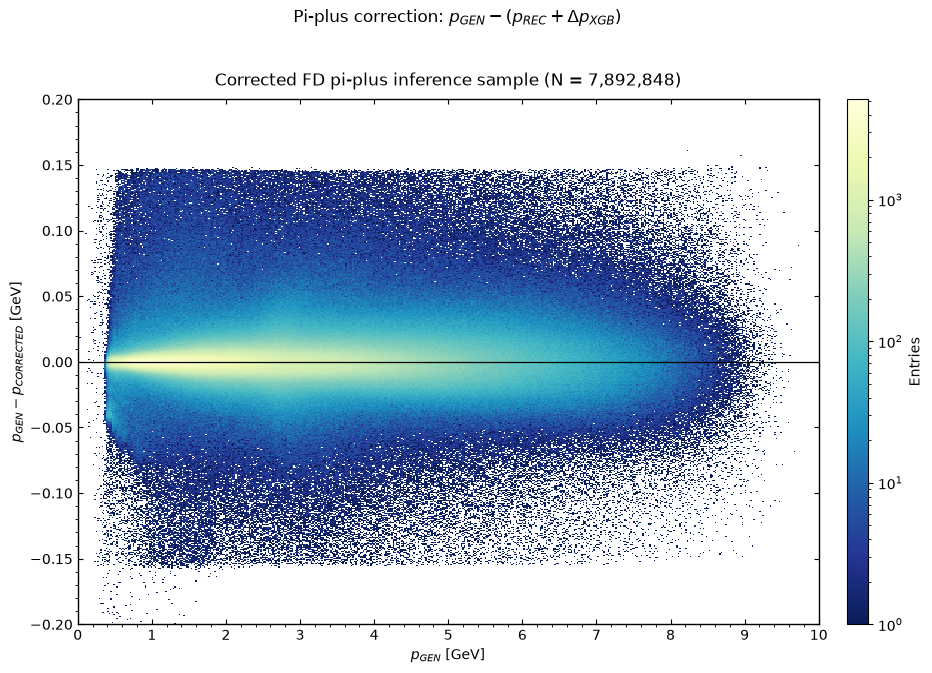

In [19]:
# Corrected delta_p versus p_gen for the inference pi-plus sample.
inference_pi_plus_positive_counts = (
    INFERENCE_PI_PLUS_CORRECTED_COUNTS[
        INFERENCE_PI_PLUS_CORRECTED_COUNTS > 0
    ]
)
inference_pi_plus_colorbar_max = max(
    1,
    np.percentile(inference_pi_plus_positive_counts, 99.5),
)
inference_pi_plus_cmap = (
    plt.colormaps["YlGnBu_r"].with_extremes(bad="white")
)

figure, axis = plt.subplots(
    1,
    1,
    figsize=(9.5, 7.5),
    facecolor="white",
)
image = axis.pcolormesh(
    INFERENCE_PI_PLUS_DELTAP_X_BINS,
    INFERENCE_PI_PLUS_DELTAP_Y_BINS,
    np.ma.masked_less(
        INFERENCE_PI_PLUS_CORRECTED_COUNTS,
        1,
    ),
    shading="auto",
    cmap=inference_pi_plus_cmap,
    norm=LogNorm(vmin=1, vmax=inference_proton_colorbar_max),
)
axis.axhline(0.0, color="black", linewidth=0.9)
axis.set_title(
    "Corrected FD pi-plus inference sample "
    f"(N = {inference_pi_plus_rows:,})",
    pad=10,
)
axis.set_xlabel(r"$p_{GEN}$ [GeV]")
axis.set_ylabel(r"$p_{GEN} - p_{CORRECTED}$ [GeV]")
axis.set_xlim(0.0, 10.0)
axis.set_ylim(*INFERENCE_PI_PLUS_DELTAP_Y_LIMITS)
axis.set_xticks(np.arange(0.0, 10.1, 1.0))
axis.set_yticks(np.arange(-0.2, 0.201, 0.05))
axis.tick_params(
    axis="both",
    direction="in",
    top=True,
    right=True,
    labelleft=True,
)
axis.minorticks_on()
axis.grid(False)

for spine in axis.spines.values():
    spine.set_linewidth(1.0)

figure.subplots_adjust(
    left=0.10,
    right=0.88,
    bottom=0.14,
    top=0.84,
)
colorbar_axis = figure.add_axes(
    [0.91, 0.14, 0.022, 0.70]
)
figure.colorbar(
    image,
    cax=colorbar_axis,
    label="Entries",
)
figure.suptitle(
    r"Pi-plus correction: "
    r"$p_{GEN} - (p_{REC} + \Delta p_{XGB})$",
    y=0.96,
)
figure.patch.set_facecolor("white")
plt.show()


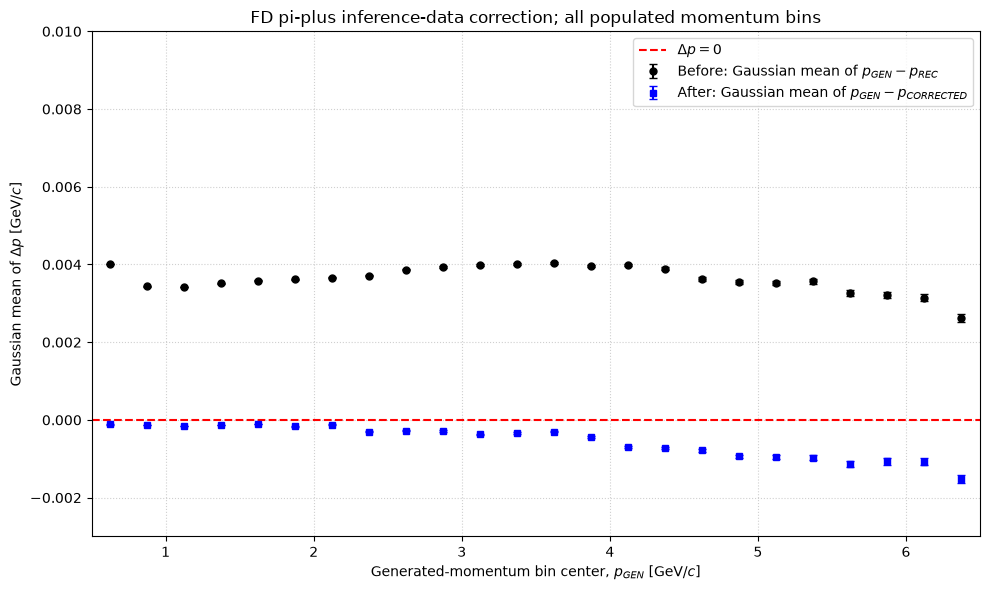

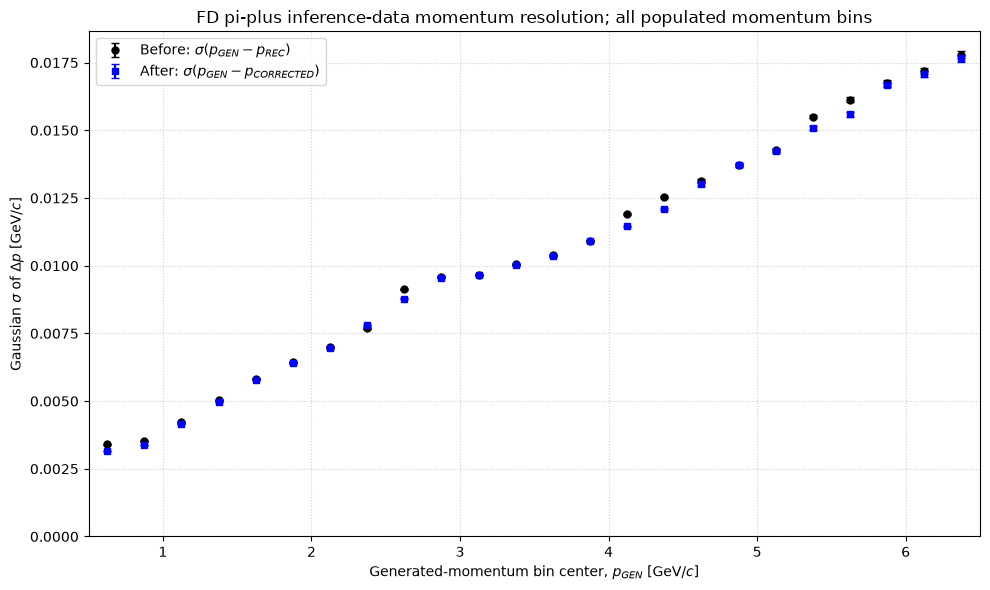

In [20]:
# Gaussian mean before/after pi-plus correction versus p_gen.
inference_pi_plus_fit_records = []

for bin_index, (p_low, p_high) in enumerate(
    zip(
        INFERENCE_PI_PLUS_MOMENTUM_EDGES[:-1],
        INFERENCE_PI_PLUS_MOMENTUM_EDGES[1:],
    )
):
    before_chunks = INFERENCE_PI_PLUS_BEFORE_BY_BIN[bin_index]
    after_chunks = INFERENCE_PI_PLUS_AFTER_BY_BIN[bin_index]
    if not before_chunks or not after_chunks:
        print(
            "Empty inference pi-plus momentum bin: "
            f"{p_low:.2f}-{p_high:.2f} GeV/c"
        )
        continue

    delta_p_before_values = np.concatenate(before_chunks)
    delta_p_after_values = np.concatenate(after_chunks)
    before_fit = fit_gaussian_peak_one_sigma(
        delta_p_before_values
    )
    after_fit = fit_gaussian_peak_one_sigma(
        delta_p_after_values
    )
    if before_fit is None or after_fit is None:
        raise RuntimeError(
            "Could not fit populated inference pi-plus bin "
            f"{p_low:.2f}-{p_high:.2f} GeV/c"
        )

    inference_pi_plus_fit_records.append(
        {
            "p_low": p_low,
            "p_high": p_high,
            "p_center": 0.5 * (p_low + p_high),
            "entries": len(delta_p_before_values),
            "before_mean": before_fit["mean"],
            "before_mean_error": before_fit["mean_error"],
            "before_sigma": before_fit["sigma"],
            "before_sigma_error": before_fit["sigma_error"],
            "after_mean": after_fit["mean"],
            "after_mean_error": after_fit["mean_error"],
            "after_sigma": after_fit["sigma"],
            "after_sigma_error": after_fit["sigma_error"],
        }
    )

inference_pi_plus_gaussian_means = pd.DataFrame(
    inference_pi_plus_fit_records
)

figure, axis = plt.subplots(figsize=(10, 6))
axis.errorbar(
    inference_pi_plus_gaussian_means["p_center"],
    inference_pi_plus_gaussian_means["before_mean"],
    yerr=inference_pi_plus_gaussian_means[
        "before_mean_error"
    ],
    fmt="o",
    color="black",
    markersize=5,
    capsize=3,
    linestyle="none",
    label=(
        r"Before: Gaussian mean of "
        r"$p_{GEN}-p_{REC}$"
    ),
)
axis.errorbar(
    inference_pi_plus_gaussian_means["p_center"],
    inference_pi_plus_gaussian_means["after_mean"],
    yerr=inference_pi_plus_gaussian_means[
        "after_mean_error"
    ],
    fmt="s",
    color="blue",
    markersize=5,
    capsize=3,
    linestyle="none",
    label=(
        r"After: Gaussian mean of "
        r"$p_{GEN}-p_{CORRECTED}$"
    ),
)
axis.axhline(
    0.0,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=r"$\Delta p=0$",
)
axis.set_xlim(
    INFERENCE_PI_PLUS_MOMENTUM_EDGES[0],
    INFERENCE_PI_PLUS_MOMENTUM_EDGES[-1],
)
axis.set_ylim(bottom=-0.003, top=0.01)
axis.set_xlabel(
    r"Generated-momentum bin center, "
    r"$p_{GEN}$ [GeV/$c$]"
)
axis.set_ylabel(
    r"Gaussian mean of $\Delta p$ [GeV/$c$]"
)
axis.set_title(
    "FD pi-plus inference-data correction; "
    "all populated momentum bins"
)
axis.grid(True, linestyle=":", alpha=0.6)
axis.legend()
figure.tight_layout()
plt.show()

# Summary of fitted Gaussian widths.
fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(
    inference_pi_plus_gaussian_means["p_center"],
    inference_pi_plus_gaussian_means["before_sigma"],
    yerr=inference_pi_plus_gaussian_means["before_sigma_error"],
    fmt="o",
    color="black",
    markersize=5,
    capsize=3,
    linestyle="none",
    label=(
        r"Before: $\sigma(p_{GEN}-p_{REC})$"
    ),
)
ax.errorbar(
    inference_pi_plus_gaussian_means["p_center"],
    inference_pi_plus_gaussian_means["after_sigma"],
    yerr=inference_pi_plus_gaussian_means["after_sigma_error"],
    fmt="s",
    color="blue",
    markersize=5,
    capsize=3,
    linestyle="none",
    label=(
        r"After: $\sigma(p_{GEN}-p_{CORRECTED})$"
    ),
)
ax.set_xlim(
    INFERENCE_PI_PLUS_MOMENTUM_EDGES[0],
    INFERENCE_PI_PLUS_MOMENTUM_EDGES[-1],
)
ax.set_ylim(bottom=0.0)
ax.set_xlabel(
    r"Generated-momentum bin center, "
    r"$p_{GEN}$ [GeV/$c$]"
)
ax.set_ylabel(
    r"Gaussian $\sigma$ of $\Delta p$ [GeV/$c$]"
)
ax.set_title(
    "FD pi-plus inference-data momentum resolution; all populated momentum bins"
)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)


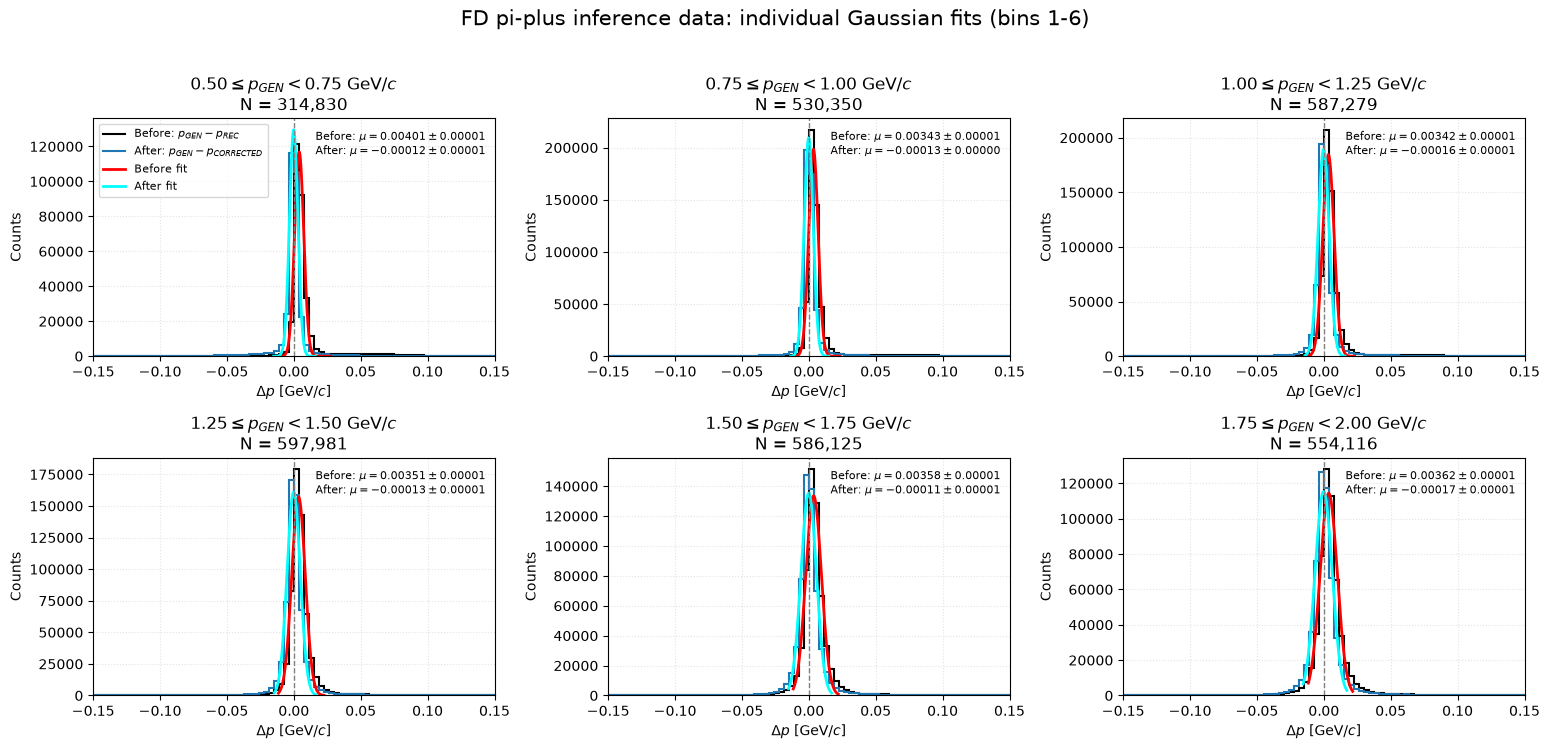

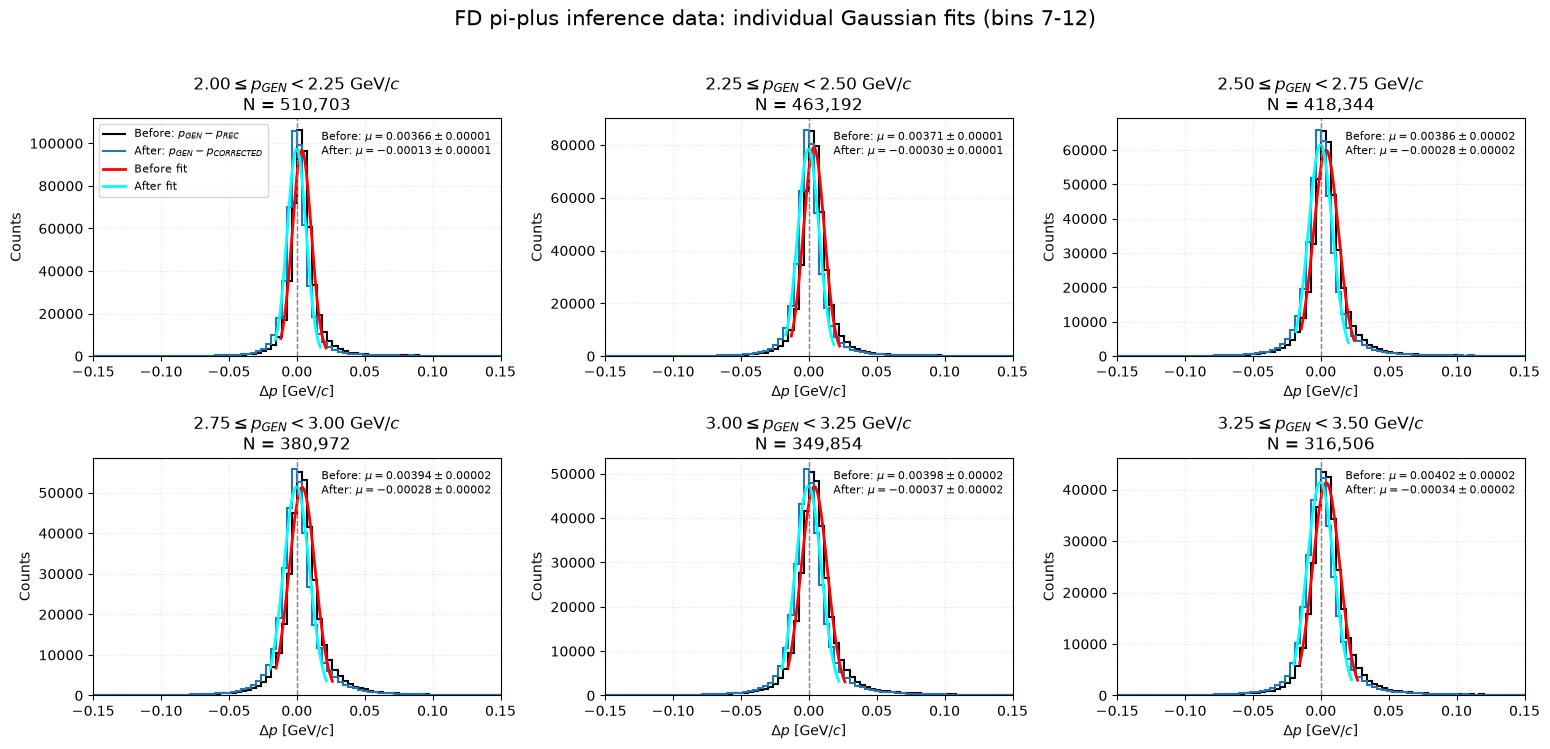

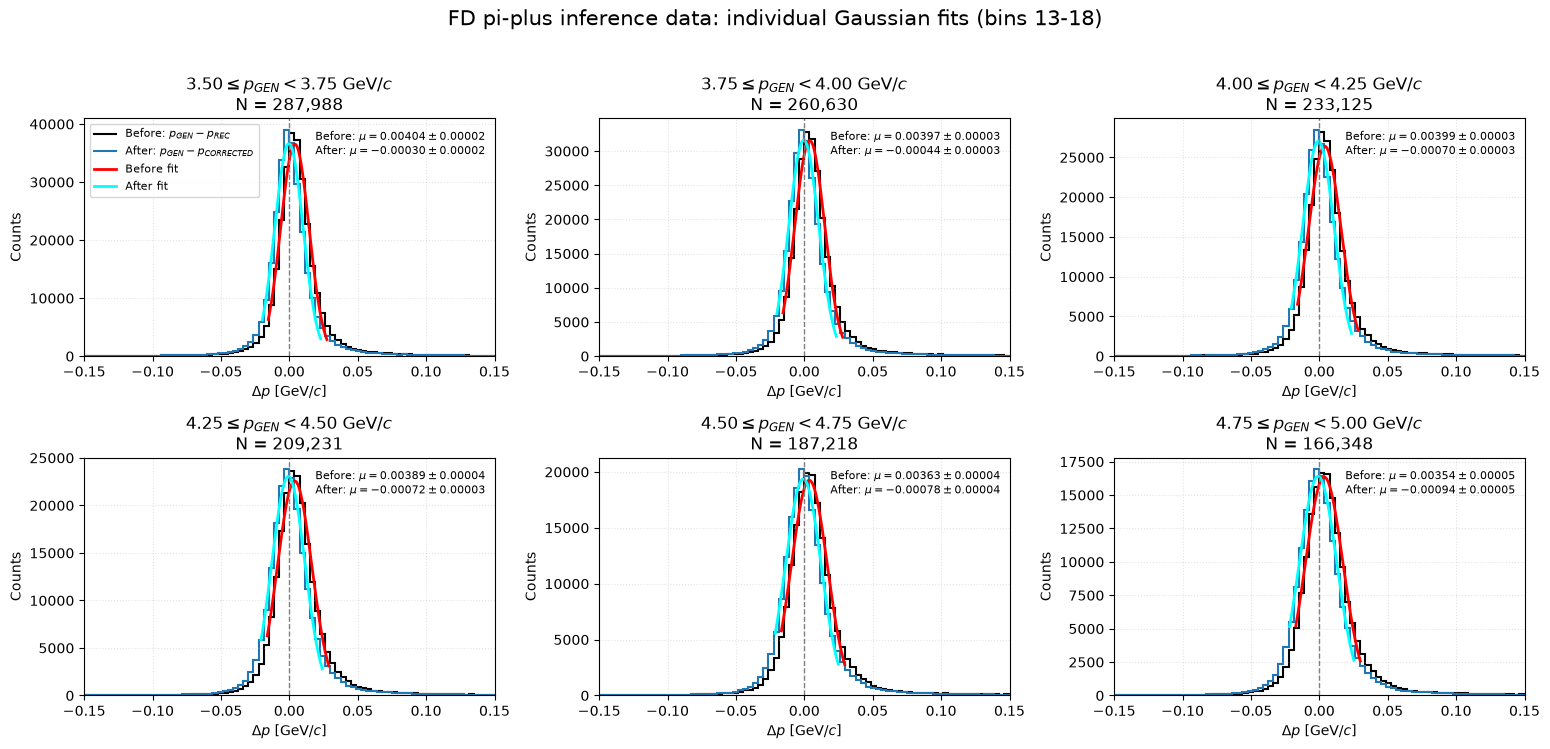

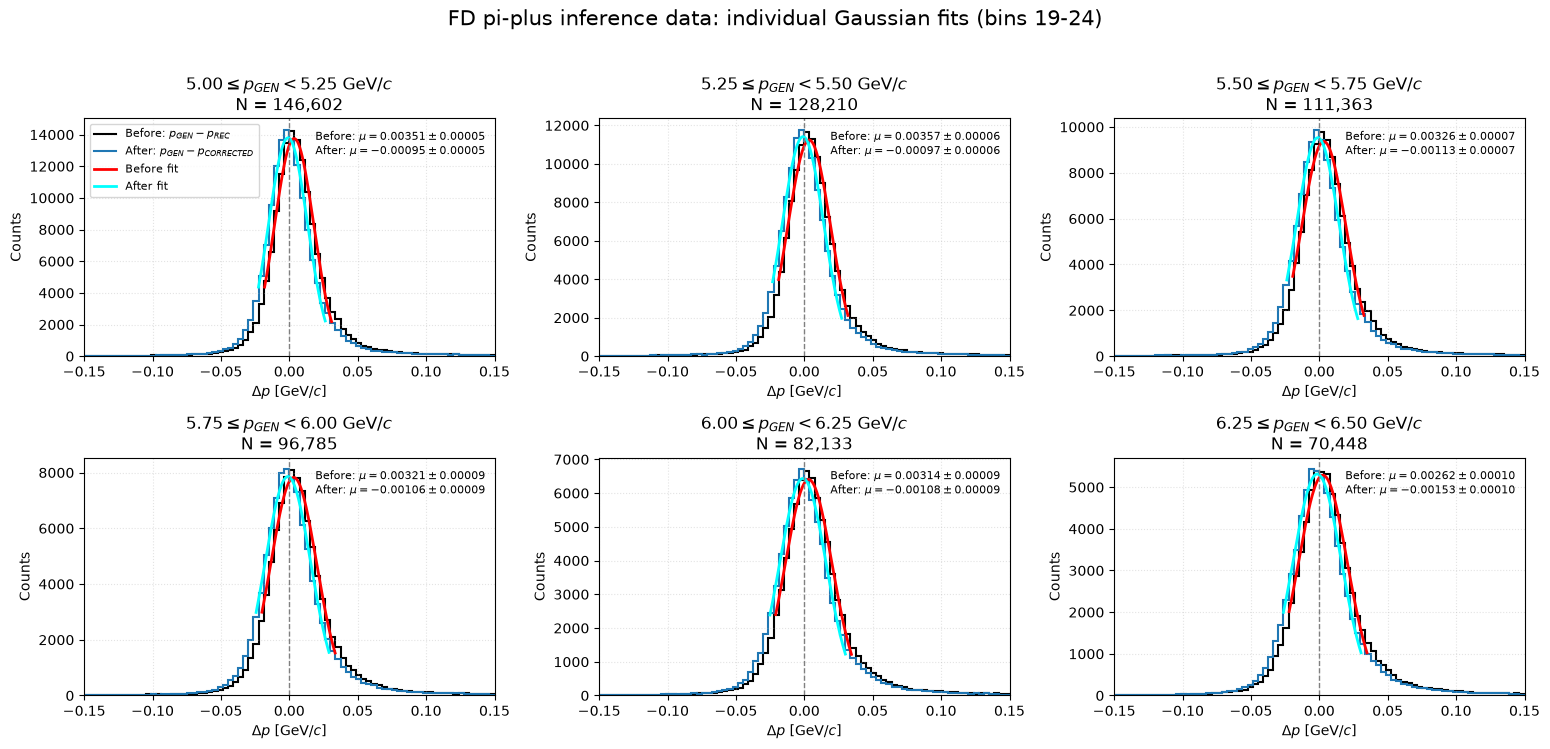

In [21]:
# Inspect every individual Gaussian fit for the inference pi-plus sample.
inference_pi_plus_individual_fit_details = []

for bin_index, (p_low, p_high) in enumerate(
    zip(
        INFERENCE_PI_PLUS_MOMENTUM_EDGES[:-1],
        INFERENCE_PI_PLUS_MOMENTUM_EDGES[1:],
    )
):
    before_chunks = INFERENCE_PI_PLUS_BEFORE_BY_BIN[bin_index]
    after_chunks = INFERENCE_PI_PLUS_AFTER_BY_BIN[bin_index]
    if not before_chunks or not after_chunks:
        continue

    delta_p_before_values = np.concatenate(before_chunks)
    delta_p_after_values = np.concatenate(after_chunks)
    before_fit = fit_gaussian_peak_one_sigma(
        delta_p_before_values
    )
    after_fit = fit_gaussian_peak_one_sigma(
        delta_p_after_values
    )
    if before_fit is None or after_fit is None:
        raise RuntimeError(
            "Could not fit populated inference pi-plus bin "
            f"{p_low:.2f}-{p_high:.2f} GeV/c"
        )

    inference_pi_plus_individual_fit_details.append(
        {
            "p_low": p_low,
            "p_high": p_high,
            "entries": len(delta_p_before_values),
            "before": before_fit,
            "after": after_fit,
        }
    )

INFERENCE_PI_PLUS_FITS_PER_FIGURE = 6

for page_start in range(
    0,
    len(inference_pi_plus_individual_fit_details),
    INFERENCE_PI_PLUS_FITS_PER_FIGURE,
):
    page_details = inference_pi_plus_individual_fit_details[
        page_start:
        page_start + INFERENCE_PI_PLUS_FITS_PER_FIGURE
    ]
    panel_columns = 3
    panel_rows = int(
        np.ceil(len(page_details) / panel_columns)
    )
    figure, axes = plt.subplots(
        panel_rows,
        panel_columns,
        figsize=(
            5.2 * panel_columns,
            3.8 * panel_rows,
        ),
        squeeze=False,
    )
    axes = axes.ravel()

    for panel_index, fit_data in enumerate(page_details):
        axis = axes[panel_index]
        before_fit = fit_data["before"]
        after_fit = fit_data["after"]

        axis.stairs(
            before_fit["counts"],
            before_fit["edges"],
            color="black",
            linewidth=1.5,
            label=r"Before: $p_{GEN}-p_{REC}$",
        )
        axis.stairs(
            after_fit["counts"],
            after_fit["edges"],
            color="tab:blue",
            linewidth=1.5,
            label=r"After: $p_{GEN}-p_{CORRECTED}$",
        )

        before_x = np.linspace(
            before_fit["fit_low"],
            before_fit["fit_high"],
            400,
        )
        after_x = np.linspace(
            after_fit["fit_low"],
            after_fit["fit_high"],
            400,
        )
        axis.plot(
            before_x,
            gaussian_no_rejection(
                before_x,
                *before_fit["parameters"],
            ),
            color="red",
            linewidth=2.0,
            label="Before fit",
        )
        axis.plot(
            after_x,
            gaussian_no_rejection(
                after_x,
                *after_fit["parameters"],
            ),
            color="cyan",
            linewidth=2.0,
            label="After fit",
        )

        axis.axvline(
            0.0,
            color="gray",
            linestyle="--",
            linewidth=1.0,
        )
        axis.set_xlim(RESIDUAL_LIMITS)
        axis.set_xlabel(r"$\Delta p$ [GeV/$c$]")
        axis.set_ylabel("Counts")
        axis.set_title(
            rf"${fit_data['p_low']:.2f} "
            rf"\leq p_{{GEN}} < "
            rf"{fit_data['p_high']:.2f}$ GeV/$c$"
            f"\nN = {fit_data['entries']:,}"
        )
        axis.grid(True, linestyle=":", alpha=0.35)

        fit_text = (
            rf"Before: $\mu={before_fit['mean']:.5f} "
            rf"\pm {before_fit['mean_error']:.5f}$"
            "\n"
            rf"After: $\mu={after_fit['mean']:.5f} "
            rf"\pm {after_fit['mean_error']:.5f}$"
        )
        axis.text(
            0.98,
            0.95,
            fit_text,
            transform=axis.transAxes,
            ha="right",
            va="top",
            fontsize=8,
        )

        if panel_index == 0:
            axis.legend(
                loc="upper left",
                fontsize=8,
            )

    for unused_axis in axes[len(page_details):]:
        unused_axis.set_visible(False)

    page_end = page_start + len(page_details)
    figure.suptitle(
        "FD pi-plus inference data: individual Gaussian fits "
        f"(bins {page_start + 1}-{page_end})",
        fontsize=15,
    )
    figure.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()
    plt.close(figure)


In [22]:
# Apply the trained pi-minus model to reconstructed FD pi-minus rows in batches.
if "xgb_pi_minus" not in globals():
    raise NameError("Run the model-loading cell first to define xgb_pi_minus.")
if "fit_gaussian_peak_one_sigma" not in globals():
    raise NameError(
        "Run the inference fit-helpers cell first to define "
        "fit_gaussian_peak_one_sigma."
    )

INFERENCE_PI_MINUS_PID = -211
INFERENCE_PI_MINUS_COLUMNS = [
    "p_gen",
    "p_rec",
    "theta_rec",
    "phi_rec",
]
INFERENCE_PI_MINUS_CUT = (
    INFERENCE_GLOBAL_CUT
    & (ds.field("pid_gen") == INFERENCE_PI_MINUS_PID)
)

# Same plotting range and p_gen fit bins used for the pi-minus diagnostics.
INFERENCE_PI_MINUS_DELTAP_X_BINS = np.linspace(0.0, 10.0, 500)
INFERENCE_PI_MINUS_DELTAP_Y_LIMITS = (-0.2, 0.2)
INFERENCE_PI_MINUS_DELTAP_Y_BINS = np.linspace(
    *INFERENCE_PI_MINUS_DELTAP_Y_LIMITS,
    500,
)
INFERENCE_PI_MINUS_MOMENTUM_BIN_WIDTH = 0.25
INFERENCE_PI_MINUS_MOMENTUM_MIN = 0.5
INFERENCE_PI_MINUS_MOMENTUM_MAX = 6.5
INFERENCE_PI_MINUS_MOMENTUM_EDGES = np.arange(
    INFERENCE_PI_MINUS_MOMENTUM_MIN,
    (
        INFERENCE_PI_MINUS_MOMENTUM_MAX
        + 0.5 * INFERENCE_PI_MINUS_MOMENTUM_BIN_WIDTH
    ),
    INFERENCE_PI_MINUS_MOMENTUM_BIN_WIDTH,
)

INFERENCE_PI_MINUS_CORRECTED_COUNTS = np.zeros(
    (
        len(INFERENCE_PI_MINUS_DELTAP_Y_BINS) - 1,
        len(INFERENCE_PI_MINUS_DELTAP_X_BINS) - 1,
    ),
    dtype=np.int64,
)
INFERENCE_PI_MINUS_BEFORE_BY_BIN = {
    bin_index: []
    for bin_index in range(
        len(INFERENCE_PI_MINUS_MOMENTUM_EDGES) - 1
    )
}
INFERENCE_PI_MINUS_AFTER_BY_BIN = {
    bin_index: []
    for bin_index in range(
        len(INFERENCE_PI_MINUS_MOMENTUM_EDGES) - 1
    )
}
inference_pi_minus_rows = 0

for inference_batch in inference_parquet_dataset.scanner(
    columns=INFERENCE_PI_MINUS_COLUMNS,
    filter=INFERENCE_PI_MINUS_CUT,
    batch_size=250_000,
    use_threads=True,
    batch_readahead=2,
    fragment_readahead=1,
).to_batches():
    inference_pi_minus_df = inference_batch.to_pandas()
    valid = np.all(
        np.isfinite(
            inference_pi_minus_df[
                ["p_gen", "p_rec", "theta_rec", "phi_rec"]
            ]
        ),
        axis=1,
    )
    inference_pi_minus_df = inference_pi_minus_df.loc[valid]
    if inference_pi_minus_df.empty:
        continue

    inference_pi_minus_features = inference_pi_minus_df[
        ["p_rec", "theta_rec", "phi_rec"]
    ]
    inference_pi_minus_delta_p_pred = xgb_pi_minus.predict(
        inference_pi_minus_features
    )
    inference_pi_minus_delta_p_before = (
        inference_pi_minus_df["p_gen"].to_numpy()
        - inference_pi_minus_df["p_rec"].to_numpy()
    )
    inference_pi_minus_delta_p_after = (
        inference_pi_minus_delta_p_before
        - inference_pi_minus_delta_p_pred
    )
    inference_pi_minus_p_gen = (
        inference_pi_minus_df["p_gen"].to_numpy()
    )
    inference_pi_minus_p_rec = (
        inference_pi_minus_df["p_rec"].to_numpy()
    )
    inference_pi_minus_rows += len(inference_pi_minus_df)

    histogram, _, _ = np.histogram2d(
        inference_pi_minus_delta_p_after,
        inference_pi_minus_p_gen,
        bins=[
            INFERENCE_PI_MINUS_DELTAP_Y_BINS,
            INFERENCE_PI_MINUS_DELTAP_X_BINS,
        ],
    )
    INFERENCE_PI_MINUS_CORRECTED_COUNTS += (
        histogram.astype(np.int64)
    )

    inference_pi_minus_p_gen_bin_indices = (
        np.searchsorted(
            INFERENCE_PI_MINUS_MOMENTUM_EDGES,
            inference_pi_minus_p_gen,
            side="right",
        )
        - 1
    )
    for bin_index in range(
        len(INFERENCE_PI_MINUS_MOMENTUM_EDGES) - 1
    ):
        bin_mask = inference_pi_minus_p_gen_bin_indices == bin_index
        if not np.any(bin_mask):
            continue
        INFERENCE_PI_MINUS_BEFORE_BY_BIN[bin_index].append(
            inference_pi_minus_delta_p_before[bin_mask].astype(
                np.float32,
                copy=True,
            )
        )
        INFERENCE_PI_MINUS_AFTER_BY_BIN[bin_index].append(
            inference_pi_minus_delta_p_after[bin_mask].astype(
                np.float32,
                copy=True,
            )
        )

print(
    "FD reconstructed pi-minus rows processed: "
    f"{inference_pi_minus_rows:,}"
)
print(
    "Features used: p_rec, theta_rec, phi_rec; "
    "model: xgb_pi_minus"
)


FD reconstructed pi-minus rows processed: 4,666,038
Features used: p_rec, theta_rec, phi_rec; model: xgb_pi_minus


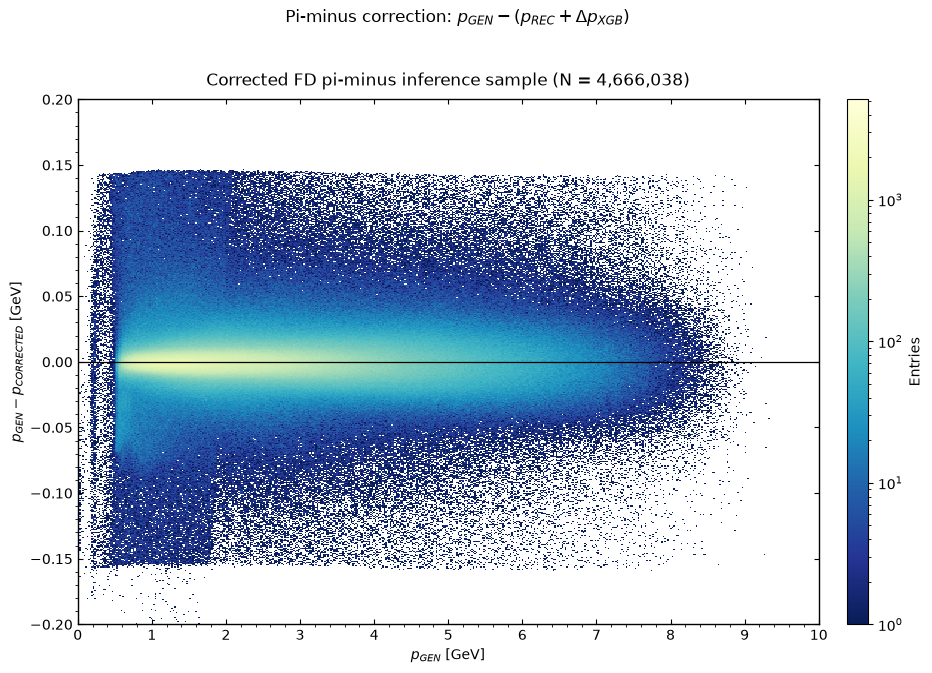

In [23]:
# Corrected delta_p versus p_gen for the inference pi-minus sample.
inference_pi_minus_positive_counts = (
    INFERENCE_PI_MINUS_CORRECTED_COUNTS[
        INFERENCE_PI_MINUS_CORRECTED_COUNTS > 0
    ]
)
inference_pi_minus_colorbar_max = max(
    1,
    np.percentile(inference_pi_minus_positive_counts, 99.5),
)
inference_pi_minus_cmap = (
    plt.colormaps["YlGnBu_r"].with_extremes(bad="white")
)

figure, axis = plt.subplots(
    1,
    1,
    figsize=(9.5, 7.5),
    facecolor="white",
)
image = axis.pcolormesh(
    INFERENCE_PI_MINUS_DELTAP_X_BINS,
    INFERENCE_PI_MINUS_DELTAP_Y_BINS,
    np.ma.masked_less(
        INFERENCE_PI_MINUS_CORRECTED_COUNTS,
        1,
    ),
    shading="auto",
    cmap=inference_pi_minus_cmap,
    norm=LogNorm(vmin=1, vmax=inference_proton_colorbar_max)
)
axis.axhline(0.0, color="black", linewidth=0.9)
axis.set_title(
    "Corrected FD pi-minus inference sample "
    f"(N = {inference_pi_minus_rows:,})",
    pad=10,
)
axis.set_xlabel(r"$p_{GEN}$ [GeV]")
axis.set_ylabel(r"$p_{GEN} - p_{CORRECTED}$ [GeV]")
axis.set_xlim(0.0, 10.0)
axis.set_ylim(*INFERENCE_PI_MINUS_DELTAP_Y_LIMITS)
axis.set_xticks(np.arange(0.0, 10.1, 1.0))
axis.set_yticks(np.arange(-0.2, 0.201, 0.05))
axis.tick_params(
    axis="both",
    direction="in",
    top=True,
    right=True,
    labelleft=True,
)
axis.minorticks_on()
axis.grid(False)

for spine in axis.spines.values():
    spine.set_linewidth(1.0)

figure.subplots_adjust(
    left=0.10,
    right=0.88,
    bottom=0.14,
    top=0.84,
)
colorbar_axis = figure.add_axes(
    [0.91, 0.14, 0.022, 0.70]
)
figure.colorbar(
    image,
    cax=colorbar_axis,
    label="Entries",
)
figure.suptitle(
    r"Pi-minus correction: "
    r"$p_{GEN} - (p_{REC} + \Delta p_{XGB})$",
    y=0.96,
)
figure.patch.set_facecolor("white")
plt.show()


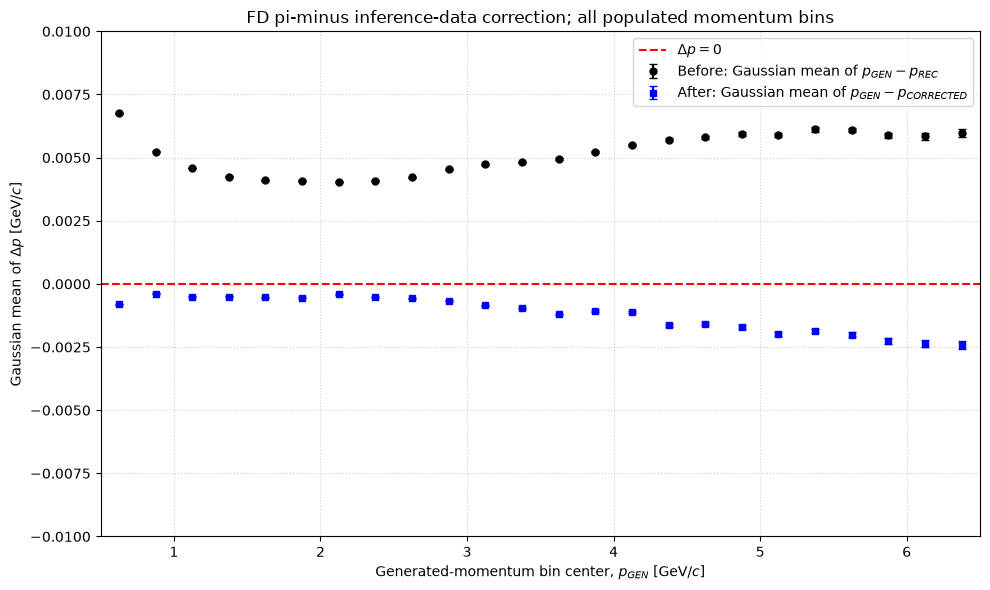

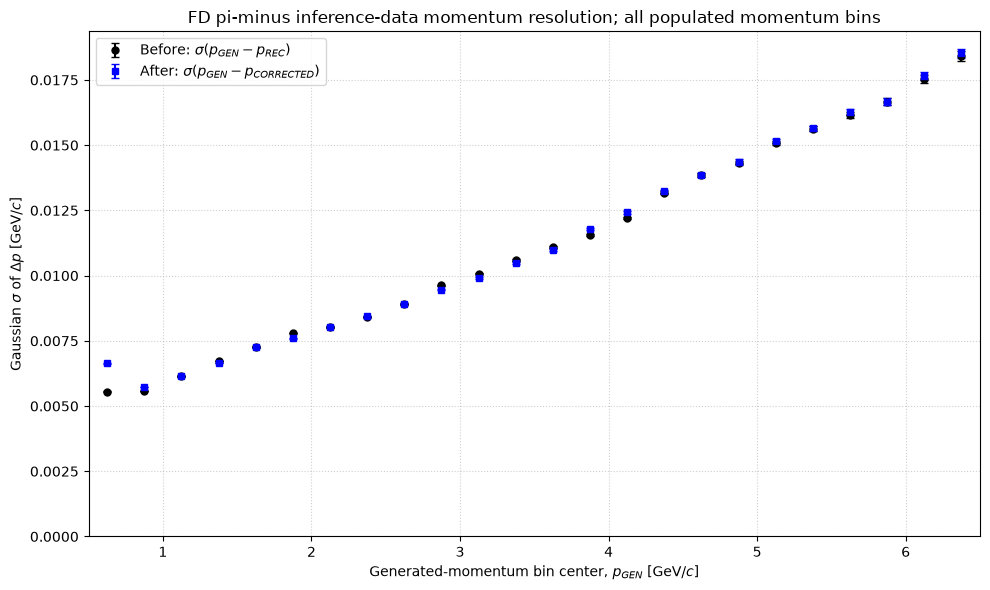

In [24]:
# Gaussian mean before/after pi-minus correction versus p_gen.
inference_pi_minus_fit_records = []

for bin_index, (p_low, p_high) in enumerate(
    zip(
        INFERENCE_PI_MINUS_MOMENTUM_EDGES[:-1],
        INFERENCE_PI_MINUS_MOMENTUM_EDGES[1:],
    )
):
    before_chunks = INFERENCE_PI_MINUS_BEFORE_BY_BIN[bin_index]
    after_chunks = INFERENCE_PI_MINUS_AFTER_BY_BIN[bin_index]
    if not before_chunks or not after_chunks:
        print(
            "Empty inference pi-minus momentum bin: "
            f"{p_low:.2f}-{p_high:.2f} GeV/c"
        )
        continue

    delta_p_before_values = np.concatenate(before_chunks)
    delta_p_after_values = np.concatenate(after_chunks)
    before_fit = fit_gaussian_peak_one_sigma(
        delta_p_before_values
    )
    after_fit = fit_gaussian_peak_one_sigma(
        delta_p_after_values
    )
    if before_fit is None or after_fit is None:
        raise RuntimeError(
            "Could not fit populated inference pi-minus bin "
            f"{p_low:.2f}-{p_high:.2f} GeV/c"
        )

    inference_pi_minus_fit_records.append(
        {
            "p_low": p_low,
            "p_high": p_high,
            "p_center": 0.5 * (p_low + p_high),
            "entries": len(delta_p_before_values),
            "before_mean": before_fit["mean"],
            "before_mean_error": before_fit["mean_error"],
            "before_sigma": before_fit["sigma"],
            "before_sigma_error": before_fit["sigma_error"],
            "after_mean": after_fit["mean"],
            "after_mean_error": after_fit["mean_error"],
            "after_sigma": after_fit["sigma"],
            "after_sigma_error": after_fit["sigma_error"],
        }
    )

inference_pi_minus_gaussian_means = pd.DataFrame(
    inference_pi_minus_fit_records
)

figure, axis = plt.subplots(figsize=(10, 6))
axis.errorbar(
    inference_pi_minus_gaussian_means["p_center"],
    inference_pi_minus_gaussian_means["before_mean"],
    yerr=inference_pi_minus_gaussian_means[
        "before_mean_error"
    ],
    fmt="o",
    color="black",
    markersize=5,
    capsize=3,
    linestyle="none",
    label=(
        r"Before: Gaussian mean of "
        r"$p_{GEN}-p_{REC}$"
    ),
)
axis.errorbar(
    inference_pi_minus_gaussian_means["p_center"],
    inference_pi_minus_gaussian_means["after_mean"],
    yerr=inference_pi_minus_gaussian_means[
        "after_mean_error"
    ],
    fmt="s",
    color="blue",
    markersize=5,
    capsize=3,
    linestyle="none",
    label=(
        r"After: Gaussian mean of "
        r"$p_{GEN}-p_{CORRECTED}$"
    ),
)
axis.axhline(
    0.0,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=r"$\Delta p=0$",
)
axis.set_xlim(
    INFERENCE_PI_MINUS_MOMENTUM_EDGES[0],
    INFERENCE_PI_MINUS_MOMENTUM_EDGES[-1],
)
axis.set_xlabel(
    r"Generated-momentum bin center, "
    r"$p_{GEN}$ [GeV/$c$]"
)
axis.set_ylabel(
    r"Gaussian mean of $\Delta p$ [GeV/$c$]"
)
axis.set_ylim(bottom=-0.010, top=0.010)
axis.set_title(
    "FD pi-minus inference-data correction; "
    "all populated momentum bins"
)
axis.grid(True, linestyle=":", alpha=0.6)
axis.legend()
figure.tight_layout()
plt.show()

# Summary of fitted Gaussian widths.
fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(
    inference_pi_minus_gaussian_means["p_center"],
    inference_pi_minus_gaussian_means["before_sigma"],
    yerr=inference_pi_minus_gaussian_means["before_sigma_error"],
    fmt="o",
    color="black",
    markersize=5,
    capsize=3,
    linestyle="none",
    label=(
        r"Before: $\sigma(p_{GEN}-p_{REC})$"
    ),
)
ax.errorbar(
    inference_pi_minus_gaussian_means["p_center"],
    inference_pi_minus_gaussian_means["after_sigma"],
    yerr=inference_pi_minus_gaussian_means["after_sigma_error"],
    fmt="s",
    color="blue",
    markersize=5,
    capsize=3,
    linestyle="none",
    label=(
        r"After: $\sigma(p_{GEN}-p_{CORRECTED})$"
    ),
)
ax.set_xlim(
    INFERENCE_PI_MINUS_MOMENTUM_EDGES[0],
    INFERENCE_PI_MINUS_MOMENTUM_EDGES[-1],
)
ax.set_ylim(bottom=0.0)
ax.set_xlabel(
    r"Generated-momentum bin center, "
    r"$p_{GEN}$ [GeV/$c$]"
)
ax.set_ylabel(
    r"Gaussian $\sigma$ of $\Delta p$ [GeV/$c$]"
)
ax.set_title(
    "FD pi-minus inference-data momentum resolution; all populated momentum bins"
)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)


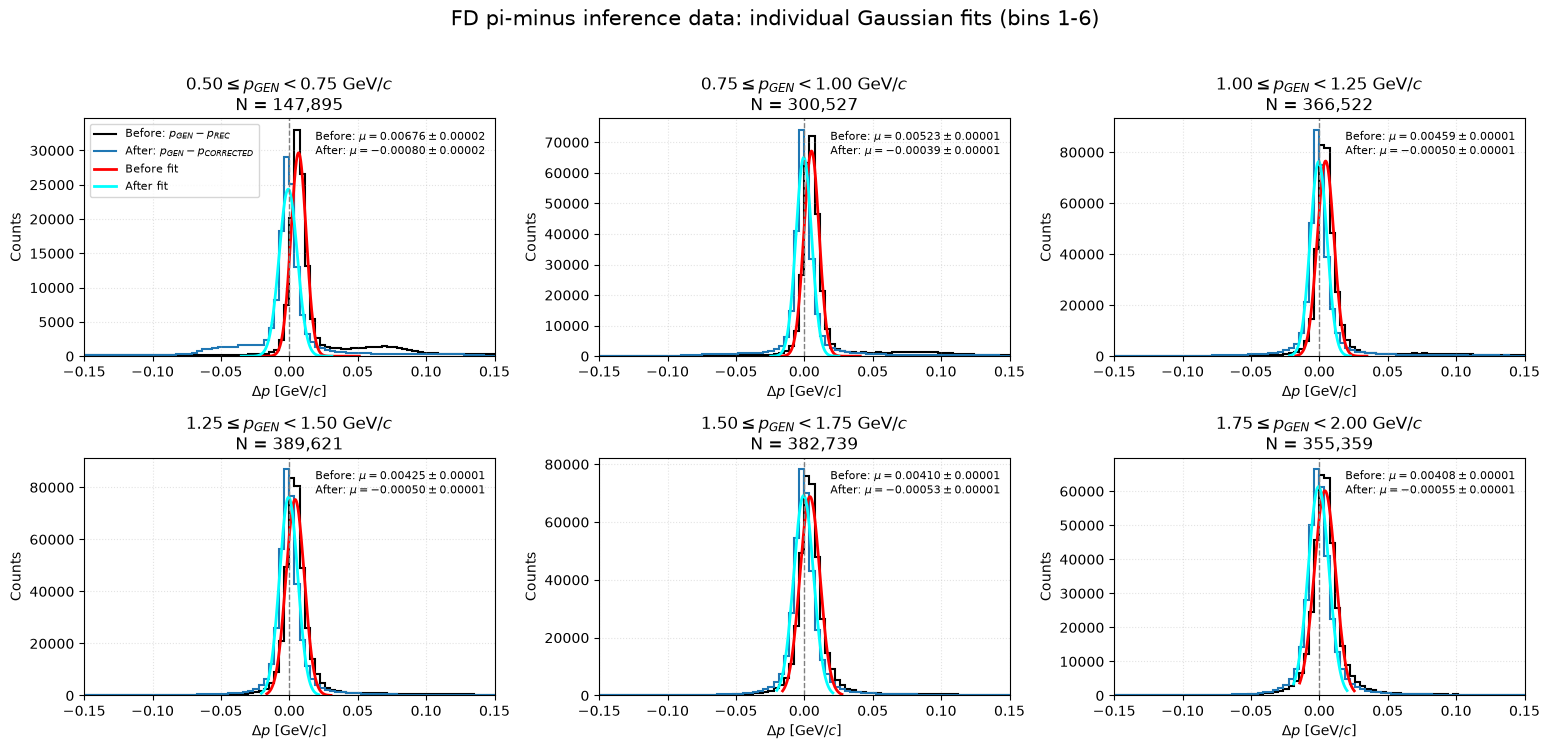

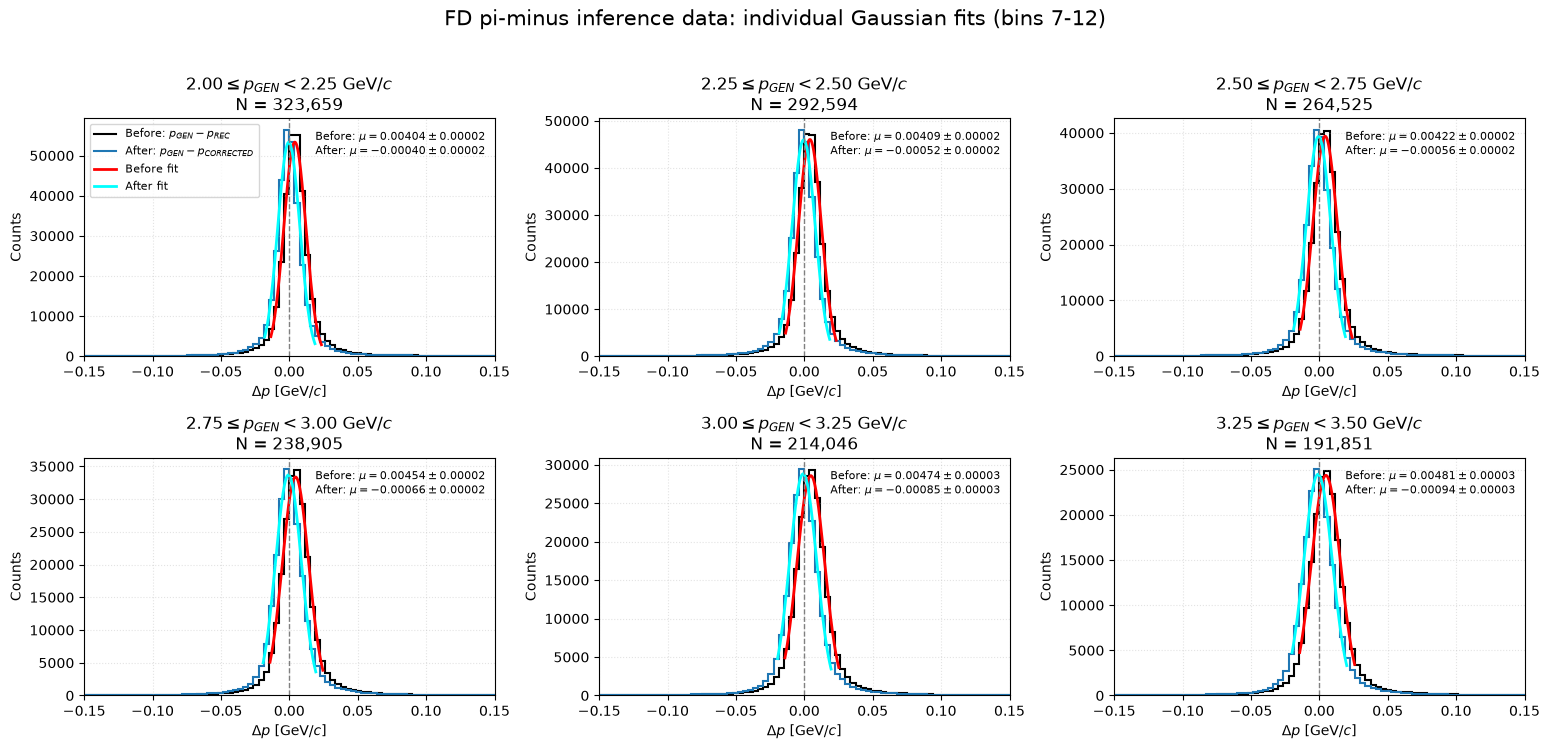

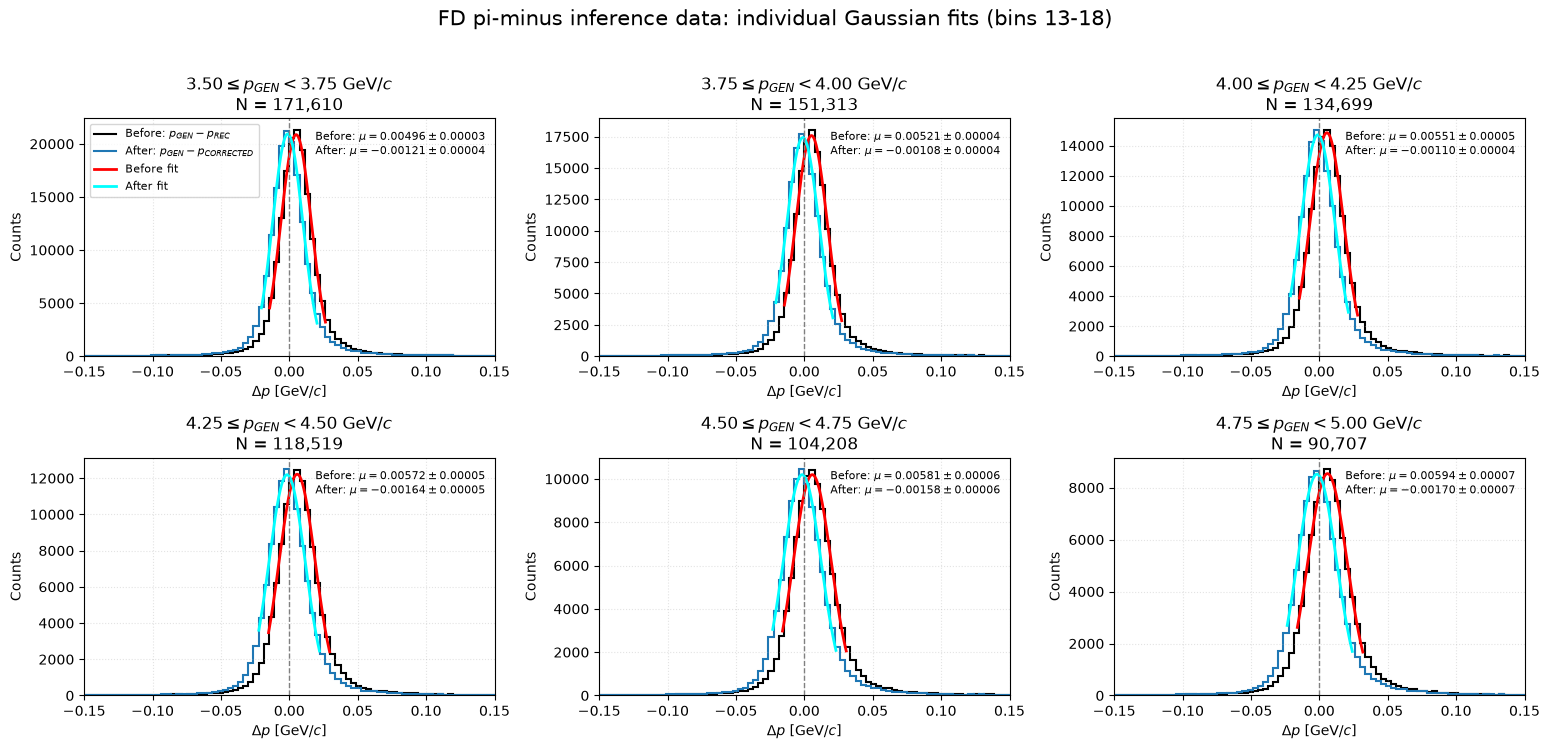

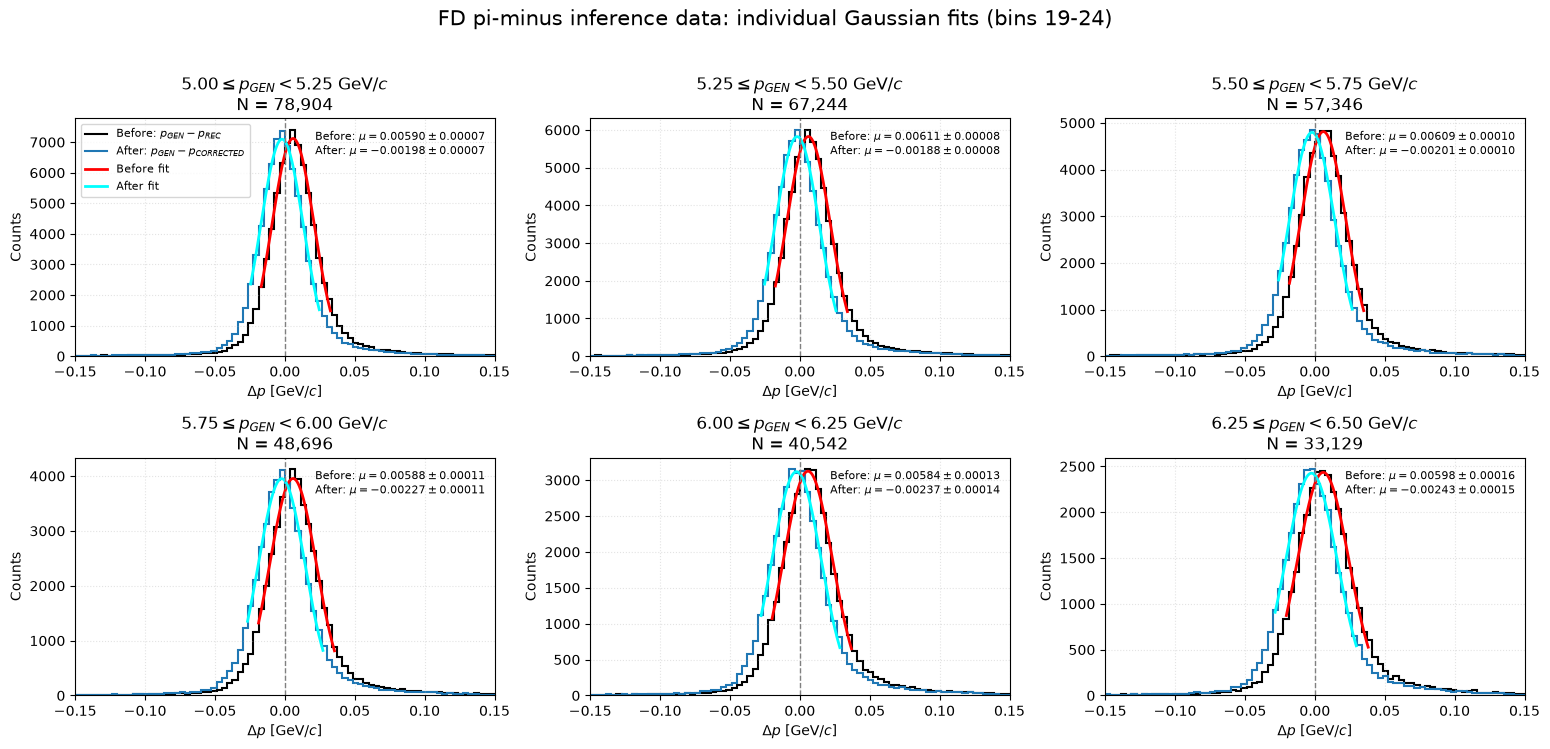

In [25]:
# Inspect every individual Gaussian fit for the inference pi-minus sample.
inference_pi_minus_individual_fit_details = []

for bin_index, (p_low, p_high) in enumerate(
    zip(
        INFERENCE_PI_MINUS_MOMENTUM_EDGES[:-1],
        INFERENCE_PI_MINUS_MOMENTUM_EDGES[1:],
    )
):
    before_chunks = INFERENCE_PI_MINUS_BEFORE_BY_BIN[bin_index]
    after_chunks = INFERENCE_PI_MINUS_AFTER_BY_BIN[bin_index]
    if not before_chunks or not after_chunks:
        continue

    delta_p_before_values = np.concatenate(before_chunks)
    delta_p_after_values = np.concatenate(after_chunks)
    before_fit = fit_gaussian_peak_one_sigma(
        delta_p_before_values
    )
    after_fit = fit_gaussian_peak_one_sigma(
        delta_p_after_values
    )
    if before_fit is None or after_fit is None:
        raise RuntimeError(
            "Could not fit populated inference pi-minus bin "
            f"{p_low:.2f}-{p_high:.2f} GeV/c"
        )

    inference_pi_minus_individual_fit_details.append(
        {
            "p_low": p_low,
            "p_high": p_high,
            "entries": len(delta_p_before_values),
            "before": before_fit,
            "after": after_fit,
        }
    )

INFERENCE_PI_MINUS_FITS_PER_FIGURE = 6

for page_start in range(
    0,
    len(inference_pi_minus_individual_fit_details),
    INFERENCE_PI_MINUS_FITS_PER_FIGURE,
):
    page_details = inference_pi_minus_individual_fit_details[
        page_start:
        page_start + INFERENCE_PI_MINUS_FITS_PER_FIGURE
    ]
    panel_columns = 3
    panel_rows = int(
        np.ceil(len(page_details) / panel_columns)
    )
    figure, axes = plt.subplots(
        panel_rows,
        panel_columns,
        figsize=(
            5.2 * panel_columns,
            3.8 * panel_rows,
        ),
        squeeze=False,
    )
    axes = axes.ravel()

    for panel_index, fit_data in enumerate(page_details):
        axis = axes[panel_index]
        before_fit = fit_data["before"]
        after_fit = fit_data["after"]

        axis.stairs(
            before_fit["counts"],
            before_fit["edges"],
            color="black",
            linewidth=1.5,
            label=r"Before: $p_{GEN}-p_{REC}$",
        )
        axis.stairs(
            after_fit["counts"],
            after_fit["edges"],
            color="tab:blue",
            linewidth=1.5,
            label=r"After: $p_{GEN}-p_{CORRECTED}$",
        )

        before_x = np.linspace(
            before_fit["fit_low"],
            before_fit["fit_high"],
            400,
        )
        after_x = np.linspace(
            after_fit["fit_low"],
            after_fit["fit_high"],
            400,
        )
        axis.plot(
            before_x,
            gaussian_no_rejection(
                before_x,
                *before_fit["parameters"],
            ),
            color="red",
            linewidth=2.0,
            label="Before fit",
        )
        axis.plot(
            after_x,
            gaussian_no_rejection(
                after_x,
                *after_fit["parameters"],
            ),
            color="cyan",
            linewidth=2.0,
            label="After fit",
        )

        axis.axvline(
            0.0,
            color="gray",
            linestyle="--",
            linewidth=1.0,
        )
        axis.set_xlim(RESIDUAL_LIMITS)
        axis.set_xlabel(r"$\Delta p$ [GeV/$c$]")
        axis.set_ylabel("Counts")
        axis.set_title(
            rf"${fit_data['p_low']:.2f} "
            rf"\leq p_{{GEN}} < "
            rf"{fit_data['p_high']:.2f}$ GeV/$c$"
            f"\nN = {fit_data['entries']:,}"
        )
        axis.grid(True, linestyle=":", alpha=0.35)

        fit_text = (
            rf"Before: $\mu={before_fit['mean']:.5f} "
            rf"\pm {before_fit['mean_error']:.5f}$"
            "\n"
            rf"After: $\mu={after_fit['mean']:.5f} "
            rf"\pm {after_fit['mean_error']:.5f}$"
        )
        axis.text(
            0.98,
            0.95,
            fit_text,
            transform=axis.transAxes,
            ha="right",
            va="top",
            fontsize=8,
        )

        if panel_index == 0:
            axis.legend(
                loc="upper left",
                fontsize=8,
            )

    for unused_axis in axes[len(page_details):]:
        unused_axis.set_visible(False)

    page_end = page_start + len(page_details)
    figure.suptitle(
        "FD pi-minus inference data: individual Gaussian fits "
        f"(bins {page_start + 1}-{page_end})",
        fontsize=15,
    )
    figure.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()
    plt.close(figure)


In [26]:
# Apply the trained electron model to reconstructed FD electron rows in batches.
if "xgb_electron" not in globals():
    raise NameError("Run the model-loading cell first to define xgb_electron.")
if "fit_gaussian_peak_one_sigma" not in globals():
    raise NameError(
        "Run the inference fit-helpers cell first to define "
        "fit_gaussian_peak_one_sigma."
    )

INFERENCE_ELECTRON_PID = 11
INFERENCE_ELECTRON_COLUMNS = [
    "p_gen",
    "p_rec",
    "theta_rec",
    "phi_rec",
    "delta_p",
]
INFERENCE_ELECTRON_CUT = (
    INFERENCE_GLOBAL_CUT
    & (ds.field("pid_gen") == INFERENCE_ELECTRON_PID)
)

# Match the original uncorrected electron sample exactly.
INFERENCE_ELECTRON_DELTAP_X_BINS = np.linspace(0.0, 10.0, 500)
INFERENCE_ELECTRON_DELTAP_Y_LIMITS = (-0.2, 0.2)
INFERENCE_ELECTRON_DELTAP_Y_BINS = np.linspace(
    *INFERENCE_ELECTRON_DELTAP_Y_LIMITS,
    500,
)
INFERENCE_ELECTRON_MOMENTUM_BIN_WIDTH = 0.25
INFERENCE_ELECTRON_MOMENTUM_MIN = 2.0
INFERENCE_ELECTRON_MOMENTUM_MAX = 8.5
INFERENCE_ELECTRON_MOMENTUM_EDGES = np.arange(
    INFERENCE_ELECTRON_MOMENTUM_MIN,
    (
        INFERENCE_ELECTRON_MOMENTUM_MAX
        + 0.5 * INFERENCE_ELECTRON_MOMENTUM_BIN_WIDTH
    ),
    INFERENCE_ELECTRON_MOMENTUM_BIN_WIDTH,
)

INFERENCE_ELECTRON_CORRECTED_COUNTS = np.zeros(
    (
        len(INFERENCE_ELECTRON_DELTAP_Y_BINS) - 1,
        len(INFERENCE_ELECTRON_DELTAP_X_BINS) - 1,
    ),
    dtype=np.int64,
)
INFERENCE_ELECTRON_BEFORE_BY_BIN = {
    bin_index: []
    for bin_index in range(
        len(INFERENCE_ELECTRON_MOMENTUM_EDGES) - 1
    )
}
INFERENCE_ELECTRON_AFTER_BY_BIN = {
    bin_index: []
    for bin_index in range(
        len(INFERENCE_ELECTRON_MOMENTUM_EDGES) - 1
    )
}
inference_electron_rows = 0

for inference_batch in inference_parquet_dataset.scanner(
    columns=INFERENCE_ELECTRON_COLUMNS,
    filter=INFERENCE_ELECTRON_CUT,
    batch_size=250_000,
    use_threads=True,
    batch_readahead=2,
    fragment_readahead=1,
).to_batches():
    inference_electron_df = inference_batch.to_pandas()
    valid = (
        np.isfinite(inference_electron_df["p_gen"])
        & np.isfinite(inference_electron_df["delta_p"])
    )
    inference_electron_df = inference_electron_df.loc[valid]
    if inference_electron_df.empty:
        continue

    inference_electron_features = inference_electron_df[
        ["p_rec", "theta_rec", "phi_rec"]
    ]
    inference_electron_delta_p_pred = xgb_electron.predict(
        inference_electron_features
    )
    if not np.all(np.isfinite(inference_electron_delta_p_pred)):
        raise RuntimeError(
            "The electron model produced non-finite predictions."
        )

    inference_electron_delta_p_before = (
        inference_electron_df["delta_p"].to_numpy()
    )
    inference_electron_delta_p_after = (
        inference_electron_delta_p_before
        - inference_electron_delta_p_pred
    )
    inference_electron_p_gen = (
        inference_electron_df["p_gen"].to_numpy()
    )
    inference_electron_p_rec = (
        inference_electron_df["p_rec"].to_numpy()
    )
    inference_electron_rows += len(inference_electron_df)

    histogram, _, _ = np.histogram2d(
        inference_electron_delta_p_after,
        inference_electron_p_gen,
        bins=[
            INFERENCE_ELECTRON_DELTAP_Y_BINS,
            INFERENCE_ELECTRON_DELTAP_X_BINS,
        ],
    )
    INFERENCE_ELECTRON_CORRECTED_COUNTS += (
        histogram.astype(np.int64)
    )

    inference_electron_p_gen_bin_indices = (
        np.searchsorted(
            INFERENCE_ELECTRON_MOMENTUM_EDGES,
            inference_electron_p_gen,
            side="right",
        )
        - 1
    )
    for bin_index in range(
        len(INFERENCE_ELECTRON_MOMENTUM_EDGES) - 1
    ):
        bin_mask = inference_electron_p_gen_bin_indices == bin_index
        if not np.any(bin_mask):
            continue
        INFERENCE_ELECTRON_BEFORE_BY_BIN[bin_index].append(
            inference_electron_delta_p_before[bin_mask].astype(
                np.float32,
                copy=True,
            )
        )
        INFERENCE_ELECTRON_AFTER_BY_BIN[bin_index].append(
            inference_electron_delta_p_after[bin_mask].astype(
                np.float32,
                copy=True,
            )
        )

print(
    "FD reconstructed electron rows processed: "
    f"{inference_electron_rows:,}"
)
print(
    "Features used: p_rec, theta_rec, phi_rec; "
    "model: xgb_electron"
)

if "INFERENCE_FD_DELTAP_ROW_COUNTS" in globals():
    electron_before_rows = INFERENCE_FD_DELTAP_ROW_COUNTS[
        INFERENCE_ELECTRON_PID
    ]
    assert inference_electron_rows == electron_before_rows, (
        f"Electron before/after row mismatch: "
        f"{electron_before_rows:,} before versus "
        f"{inference_electron_rows:,} after."
    )
    print(
        "Electron before/after samples match exactly: "
        f"{inference_electron_rows:,} rows"
    )


FD reconstructed electron rows processed: 5,024,761
Features used: p_rec, theta_rec, phi_rec; model: xgb_electron
Electron before/after samples match exactly: 5,024,761 rows


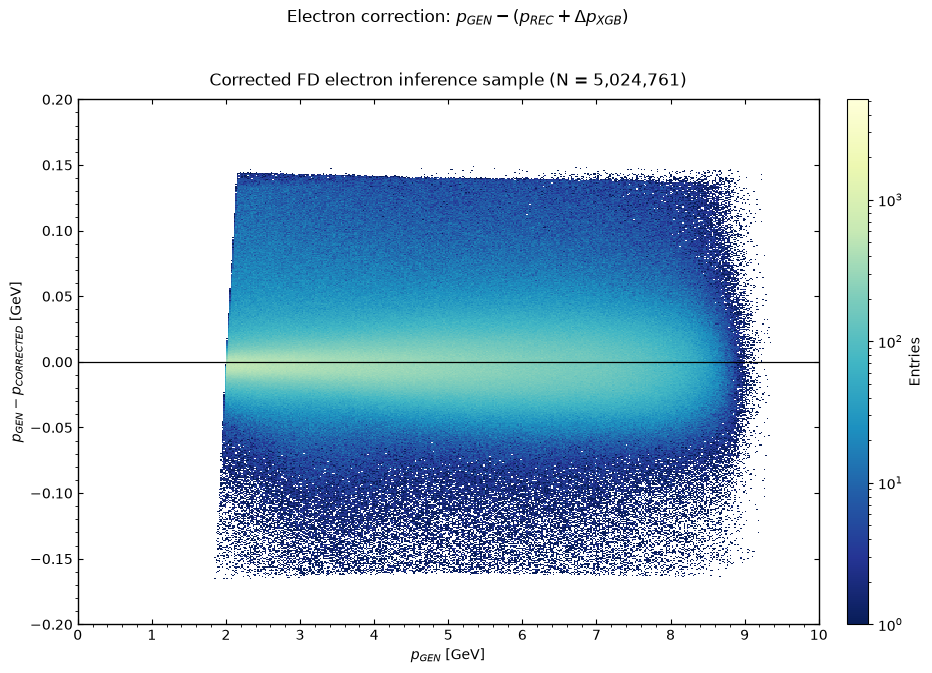

In [27]:
# Corrected delta_p versus p_gen for the inference electron sample.
inference_electron_positive_counts = (
    INFERENCE_ELECTRON_CORRECTED_COUNTS[
        INFERENCE_ELECTRON_CORRECTED_COUNTS > 0
    ]
)
inference_electron_colorbar_max = max(
    1,
    np.percentile(inference_electron_positive_counts, 99.5),
)
inference_electron_cmap = (
    plt.colormaps["YlGnBu_r"].with_extremes(bad="white")
)

figure, axis = plt.subplots(
    1,
    1,
    figsize=(9.5, 7.5),
    facecolor="white",
)
image = axis.pcolormesh(
    INFERENCE_ELECTRON_DELTAP_X_BINS,
    INFERENCE_ELECTRON_DELTAP_Y_BINS,
    np.ma.masked_less(
        INFERENCE_ELECTRON_CORRECTED_COUNTS,
        1,
    ),
    shading="auto",
    cmap=inference_electron_cmap,
    norm=LogNorm(vmin=1, vmax=inference_proton_colorbar_max)
)
axis.axhline(0.0, color="black", linewidth=0.9)
axis.set_title(
    "Corrected FD electron inference sample "
    f"(N = {inference_electron_rows:,})",
    pad=10,
)
axis.set_xlabel(r"$p_{GEN}$ [GeV]")
axis.set_ylabel(r"$p_{GEN} - p_{CORRECTED}$ [GeV]")
axis.set_xlim(0.0, 10.0)
axis.set_ylim(*INFERENCE_ELECTRON_DELTAP_Y_LIMITS)
axis.set_xticks(np.arange(0.0, 10.1, 1.0))
axis.set_yticks(np.arange(-0.2, 0.201, 0.05))
axis.tick_params(
    axis="both",
    direction="in",
    top=True,
    right=True,
    labelleft=True,
)
axis.minorticks_on()
axis.grid(False)

for spine in axis.spines.values():
    spine.set_linewidth(1.0)

figure.subplots_adjust(
    left=0.10,
    right=0.88,
    bottom=0.14,
    top=0.84,
)
colorbar_axis = figure.add_axes(
    [0.91, 0.14, 0.022, 0.70]
)
figure.colorbar(
    image,
    cax=colorbar_axis,
    label="Entries",
)
figure.suptitle(
    r"Electron correction: "
    r"$p_{GEN} - (p_{REC} + \Delta p_{XGB})$",
    y=0.96,
)
figure.patch.set_facecolor("white")
plt.show()


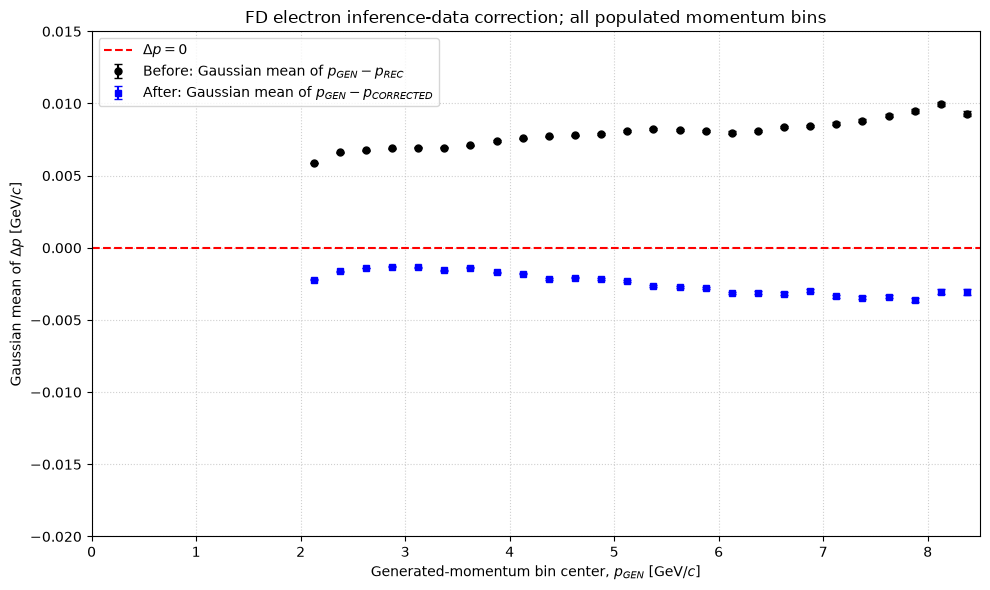

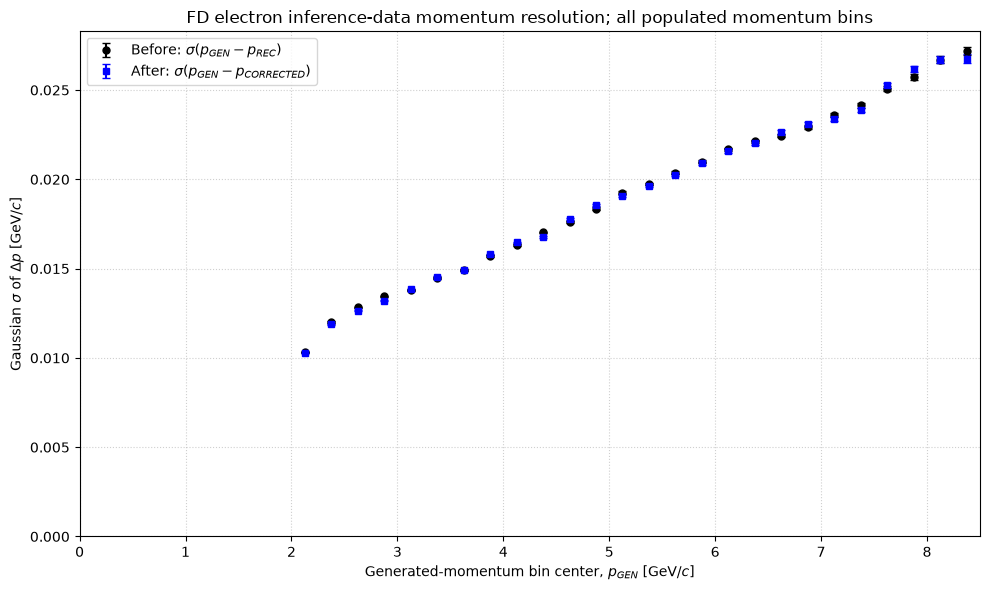

In [28]:
# Gaussian mean before/after electron correction versus p_gen.
inference_electron_fit_records = []

for bin_index, (p_low, p_high) in enumerate(
    zip(
        INFERENCE_ELECTRON_MOMENTUM_EDGES[:-1],
        INFERENCE_ELECTRON_MOMENTUM_EDGES[1:],
    )
):
    before_chunks = INFERENCE_ELECTRON_BEFORE_BY_BIN[bin_index]
    after_chunks = INFERENCE_ELECTRON_AFTER_BY_BIN[bin_index]
    if not before_chunks or not after_chunks:
        print(
            "Empty inference electron momentum bin: "
            f"{p_low:.2f}-{p_high:.2f} GeV/c"
        )
        continue

    delta_p_before_values = np.concatenate(before_chunks)
    delta_p_after_values = np.concatenate(after_chunks)
    before_fit = fit_gaussian_peak_one_sigma(
        delta_p_before_values
    )
    after_fit = fit_gaussian_peak_one_sigma(
        delta_p_after_values
    )
    if before_fit is None or after_fit is None:
        raise RuntimeError(
            "Could not fit populated inference electron bin "
            f"{p_low:.2f}-{p_high:.2f} GeV/c"
        )

    inference_electron_fit_records.append(
        {
            "p_low": p_low,
            "p_high": p_high,
            "p_center": 0.5 * (p_low + p_high),
            "entries": len(delta_p_before_values),
            "before_mean": before_fit["mean"],
            "before_mean_error": before_fit["mean_error"],
            "before_sigma": before_fit["sigma"],
            "before_sigma_error": before_fit["sigma_error"],
            "after_mean": after_fit["mean"],
            "after_mean_error": after_fit["mean_error"],
            "after_sigma": after_fit["sigma"],
            "after_sigma_error": after_fit["sigma_error"],
        }
    )

inference_electron_gaussian_means = pd.DataFrame(
    inference_electron_fit_records
)

figure, axis = plt.subplots(figsize=(10, 6))
axis.errorbar(
    inference_electron_gaussian_means["p_center"],
    inference_electron_gaussian_means["before_mean"],
    yerr=inference_electron_gaussian_means[
        "before_mean_error"
    ],
    fmt="o",
    color="black",
    markersize=5,
    capsize=3,
    linestyle="none",
    label=(
        r"Before: Gaussian mean of "
        r"$p_{GEN}-p_{REC}$"
    ),
)
axis.errorbar(
    inference_electron_gaussian_means["p_center"],
    inference_electron_gaussian_means["after_mean"],
    yerr=inference_electron_gaussian_means[
        "after_mean_error"
    ],
    fmt="s",
    color="blue",
    markersize=5,
    capsize=3,
    linestyle="none",
    label=(
        r"After: Gaussian mean of "
        r"$p_{GEN}-p_{CORRECTED}$"
    ),
)
axis.axhline(
    0.0,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=r"$\Delta p=0$",
)
axis.set_xticks(np.arange(0.0, 11.0, 1.0))
axis.set_xlim(0.0, INFERENCE_ELECTRON_MOMENTUM_EDGES[-1])
axis.set_xlabel(
    r"Generated-momentum bin center, "
    r"$p_{GEN}$ [GeV/$c$]"
)
axis.set_ylabel(
    r"Gaussian mean of $\Delta p$ [GeV/$c$]"
)
axis.set_ylim(bottom=-0.02, top=0.015)
axis.set_title(
    "FD electron inference-data correction; "
    "all populated momentum bins"
)
axis.grid(True, linestyle=":", alpha=0.6)
axis.legend()
figure.tight_layout()
plt.show()

# Summary of fitted Gaussian widths.
fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(
    inference_electron_gaussian_means["p_center"],
    inference_electron_gaussian_means["before_sigma"],
    yerr=inference_electron_gaussian_means["before_sigma_error"],
    fmt="o",
    color="black",
    markersize=5,
    capsize=3,
    linestyle="none",
    label=(
        r"Before: $\sigma(p_{GEN}-p_{REC})$"
    ),
)
ax.errorbar(
    inference_electron_gaussian_means["p_center"],
    inference_electron_gaussian_means["after_sigma"],
    yerr=inference_electron_gaussian_means["after_sigma_error"],
    fmt="s",
    color="blue",
    markersize=5,
    capsize=3,
    linestyle="none",
    label=(
        r"After: $\sigma(p_{GEN}-p_{CORRECTED})$"
    ),
)
ax.set_xticks(np.arange(0.0, 11.0, 1.0))
ax.set_xlim(0.0, INFERENCE_ELECTRON_MOMENTUM_EDGES[-1])
ax.set_ylim(bottom=0.0)
ax.set_xlabel(
    r"Generated-momentum bin center, "
    r"$p_{GEN}$ [GeV/$c$]"
)
ax.set_ylabel(
    r"Gaussian $\sigma$ of $\Delta p$ [GeV/$c$]"
)
ax.set_title(
    "FD electron inference-data momentum resolution; all populated momentum bins"
)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)


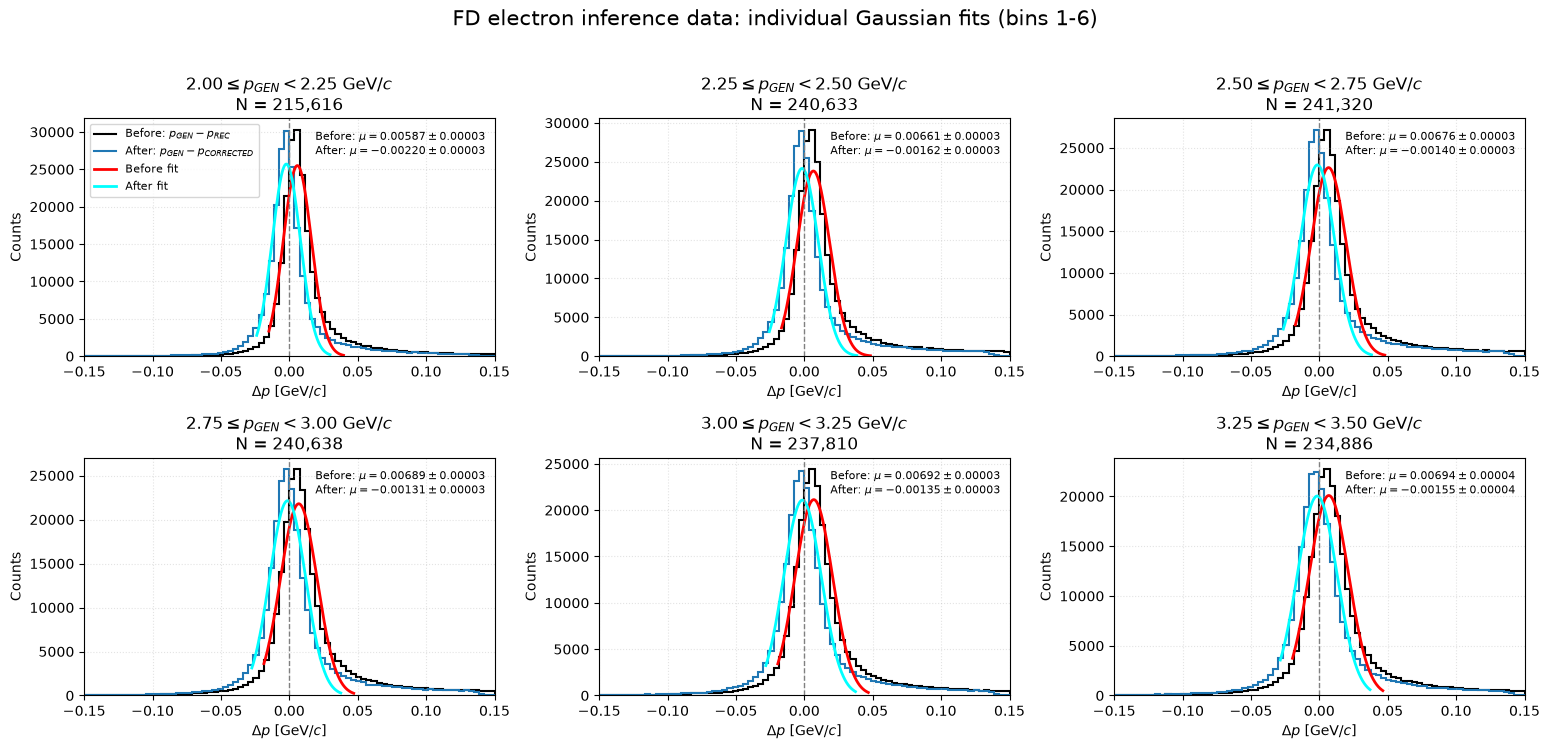

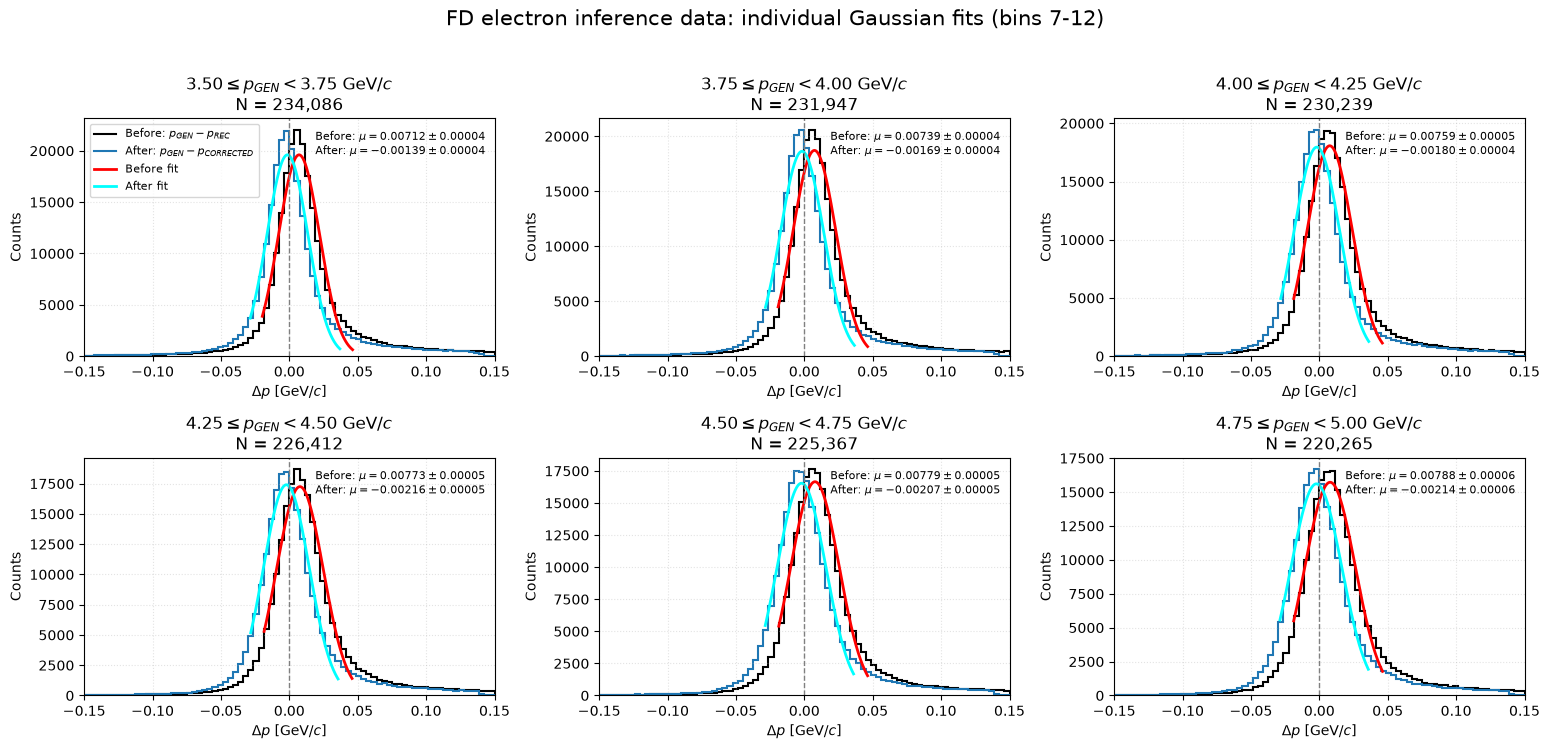

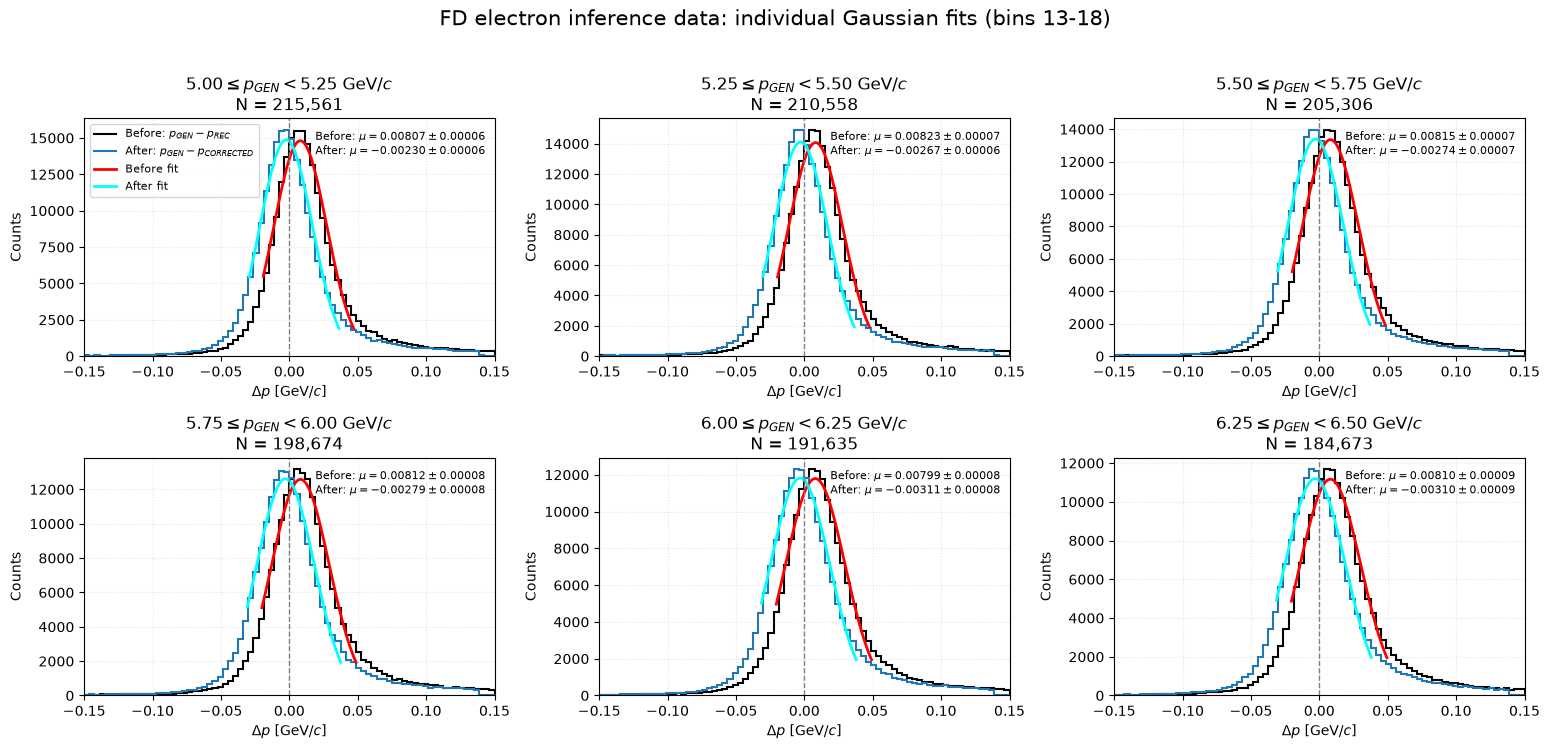

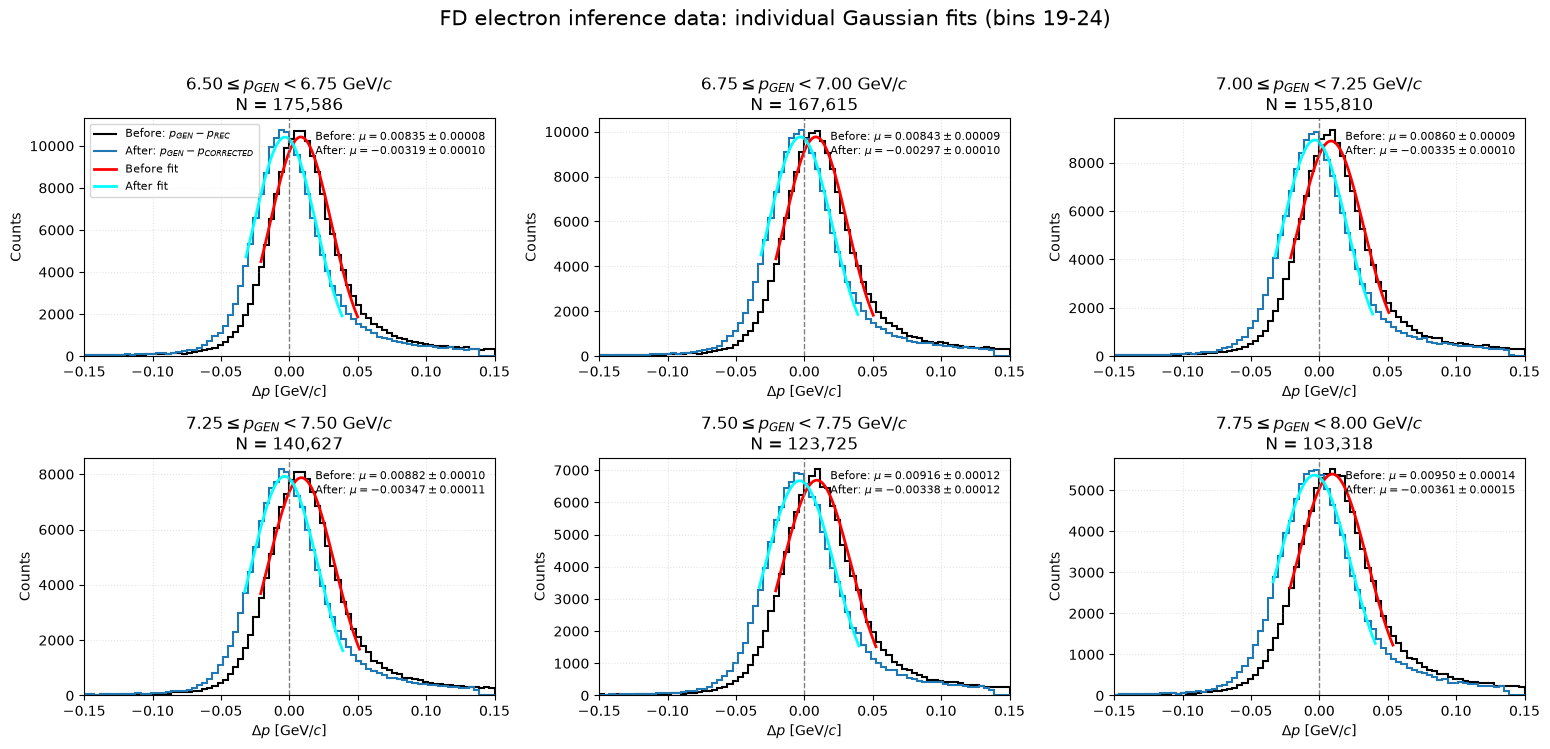

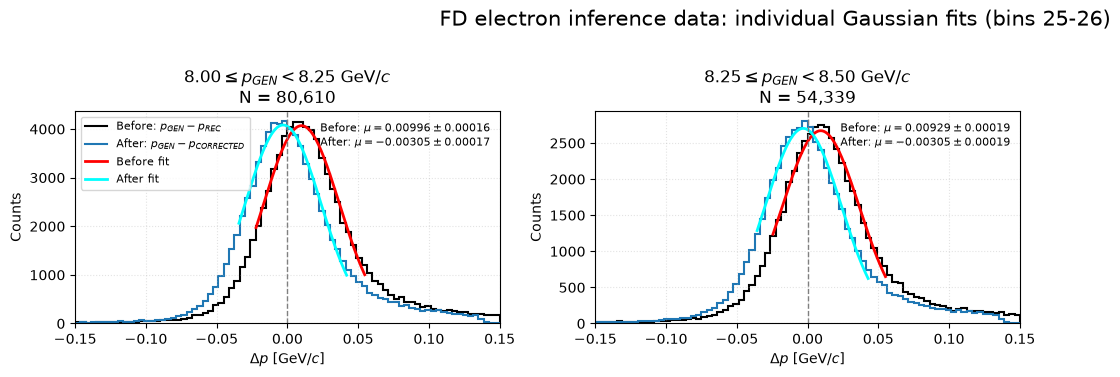

In [29]:
# Inspect every individual Gaussian fit for the inference electron sample.
inference_electron_individual_fit_details = []

for bin_index, (p_low, p_high) in enumerate(
    zip(
        INFERENCE_ELECTRON_MOMENTUM_EDGES[:-1],
        INFERENCE_ELECTRON_MOMENTUM_EDGES[1:],
    )
):
    before_chunks = INFERENCE_ELECTRON_BEFORE_BY_BIN[bin_index]
    after_chunks = INFERENCE_ELECTRON_AFTER_BY_BIN[bin_index]
    if not before_chunks or not after_chunks:
        continue

    delta_p_before_values = np.concatenate(before_chunks)
    delta_p_after_values = np.concatenate(after_chunks)
    before_fit = fit_gaussian_peak_one_sigma(
        delta_p_before_values
    )
    after_fit = fit_gaussian_peak_one_sigma(
        delta_p_after_values
    )
    if before_fit is None or after_fit is None:
        raise RuntimeError(
            "Could not fit populated inference electron bin "
            f"{p_low:.2f}-{p_high:.2f} GeV/c"
        )

    inference_electron_individual_fit_details.append(
        {
            "p_low": p_low,
            "p_high": p_high,
            "entries": len(delta_p_before_values),
            "before": before_fit,
            "after": after_fit,
        }
    )

INFERENCE_ELECTRON_FITS_PER_FIGURE = 6

for page_start in range(
    0,
    len(inference_electron_individual_fit_details),
    INFERENCE_ELECTRON_FITS_PER_FIGURE,
):
    page_details = inference_electron_individual_fit_details[
        page_start:
        page_start + INFERENCE_ELECTRON_FITS_PER_FIGURE
    ]
    panel_columns = 3
    panel_rows = int(
        np.ceil(len(page_details) / panel_columns)
    )
    figure, axes = plt.subplots(
        panel_rows,
        panel_columns,
        figsize=(
            5.2 * panel_columns,
            3.8 * panel_rows,
        ),
        squeeze=False,
    )
    axes = axes.ravel()

    for panel_index, fit_data in enumerate(page_details):
        axis = axes[panel_index]
        before_fit = fit_data["before"]
        after_fit = fit_data["after"]

        axis.stairs(
            before_fit["counts"],
            before_fit["edges"],
            color="black",
            linewidth=1.5,
            label=r"Before: $p_{GEN}-p_{REC}$",
        )
        axis.stairs(
            after_fit["counts"],
            after_fit["edges"],
            color="tab:blue",
            linewidth=1.5,
            label=r"After: $p_{GEN}-p_{CORRECTED}$",
        )

        before_x = np.linspace(
            before_fit["fit_low"],
            before_fit["fit_high"],
            400,
        )
        after_x = np.linspace(
            after_fit["fit_low"],
            after_fit["fit_high"],
            400,
        )
        axis.plot(
            before_x,
            gaussian_no_rejection(
                before_x,
                *before_fit["parameters"],
            ),
            color="red",
            linewidth=2.0,
            label="Before fit",
        )
        axis.plot(
            after_x,
            gaussian_no_rejection(
                after_x,
                *after_fit["parameters"],
            ),
            color="cyan",
            linewidth=2.0,
            label="After fit",
        )

        axis.axvline(
            0.0,
            color="gray",
            linestyle="--",
            linewidth=1.0,
        )
        axis.set_xlim(RESIDUAL_LIMITS)
        axis.set_xlabel(r"$\Delta p$ [GeV/$c$]")
        axis.set_ylabel("Counts")
        axis.set_title(
            rf"${fit_data['p_low']:.2f} "
            rf"\leq p_{{GEN}} < "
            rf"{fit_data['p_high']:.2f}$ GeV/$c$"
            f"\nN = {fit_data['entries']:,}"
        )
        axis.grid(True, linestyle=":", alpha=0.35)

        fit_text = (
            rf"Before: $\mu={before_fit['mean']:.5f} "
            rf"\pm {before_fit['mean_error']:.5f}$"
            "\n"
            rf"After: $\mu={after_fit['mean']:.5f} "
            rf"\pm {after_fit['mean_error']:.5f}$"
        )
        axis.text(
            0.98,
            0.95,
            fit_text,
            transform=axis.transAxes,
            ha="right",
            va="top",
            fontsize=8,
        )

        if panel_index == 0:
            axis.legend(
                loc="upper left",
                fontsize=8,
            )

    for unused_axis in axes[len(page_details):]:
        unused_axis.set_visible(False)

    page_end = page_start + len(page_details)
    figure.suptitle(
        "FD electron inference data: individual Gaussian fits "
        f"(bins {page_start + 1}-{page_end})",
        fontsize=15,
    )
    figure.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()
    plt.close(figure)


In [30]:
# Apply all four particle models to eligible rows from ALL events and write one corrected Parquet file.
# Run in Jupyter after loading the models and input data (Restart Kernel -> Run All).
# The writer will not overwrite an existing output: move/delete the old file first.
required_models = [
    "xgb_electron",
    "xgb_proton",
    "xgb_pi_plus",
    "xgb_pi_minus",
]
missing_models = [
    model_name
    for model_name in required_models
    if model_name not in globals()
]
if missing_models:
    raise NameError(
        "Run the model-loading cell first. Missing models: "
        f"{missing_models}"
    )

ENERGY_LOSS_MODELS = {
    11: ("electron", xgb_electron),
    2212: ("proton", xgb_proton),
    211: ("pi+", xgb_pi_plus),
    -211: ("pi-", xgb_pi_minus),
}
ENERGY_LOSS_FEATURES = [
    "p_rec",
    "theta_rec",
    "phi_rec",
]
ENERGY_LOSS_CORRECTED_COLUMNS = [
    "p_rec",
    "px_rec",
    "py_rec",
    "pz_rec",
    "delta_p",
]
# Keep the original momentum magnitude and vector for every row.
UNCORRECTED_MOMENTUM_COLUMNS = ["p_rec", "px_rec", "py_rec", "pz_rec"]
UNCORRECTED_MOMENTUM_FIELDS = {
    name: inference_parquet_schema.field(name).with_name(f"{name}_uncorrected")
    for name in UNCORRECTED_MOMENTUM_COLUMNS
}
assert all(field.name not in inference_parquet_schema.names
           for field in UNCORRECTED_MOMENTUM_FIELDS.values())
# All input particle rows are kept. Add the original momentum and correction flag.
# was_corrected = 1 only when a valid model correction was successfully applied.
# Otherwise was_corrected = 0, including particles that fail cuts.
assert "was_corrected" not in inference_parquet_schema.names
ENERGY_LOSS_OUTPUT_SCHEMA = inference_parquet_schema.append(
    pa.field("was_corrected", pa.uint8(), nullable=False)
)
for field in UNCORRECTED_MOMENTUM_FIELDS.values():
    ENERGY_LOSS_OUTPUT_SCHEMA = ENERGY_LOSS_OUTPUT_SCHEMA.append(field)

if ENERGY_LOSS_CORRECTED_PARQUET_PATH.exists():
    raise FileExistsError(
        f"Output already exists: "
        f"{ENERGY_LOSS_CORRECTED_PARQUET_PATH}\n"
        "Move or delete it before intentionally rebuilding it."
    )
ENERGY_LOSS_CORRECTED_PARQUET_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

correction_counts = {
    pid: 0 for pid in ENERGY_LOSS_MODELS
}
invalid_input_counts = {
    pid: 0 for pid in ENERGY_LOSS_MODELS
}
invalid_prediction_counts = {
    pid: 0 for pid in ENERGY_LOSS_MODELS
}
corrected_rows_written = 0
corrected_batches_written = 0

# Sorting the input fragments preserves the original part-file order.
inference_fragments = sorted(
    inference_parquet_dataset.get_fragments(),
    key=lambda fragment: fragment.path,
)

corrected_writer = pq.ParquetWriter(
    ENERGY_LOSS_CORRECTED_PARQUET_PATH,
    ENERGY_LOSS_OUTPUT_SCHEMA,
    compression="zstd",
    use_dictionary=True,
    write_statistics=True,
)

try:
    for inference_fragment in inference_fragments:
        for record_batch in inference_fragment.to_batches(
            columns=INFERENCE_PARQUET_COLUMNS,
            batch_size=250_000,
            use_threads=True,
        ):
            def batch_column_numpy(column_name):
                column_index = record_batch.schema.get_field_index(
                    column_name
                )
                return record_batch.column(
                    column_index
                ).to_numpy(zero_copy_only=False)

            pid_gen_values = batch_column_numpy("pid_gen")
            reconstructed_values = batch_column_numpy(
                "reconstructed"
            )
            detector_values = batch_column_numpy("detector")
            p_gen_values = batch_column_numpy("p_gen")
            p_rec_original = batch_column_numpy("p_rec")
            theta_rec_values = batch_column_numpy("theta_rec")
            phi_rec_values = batch_column_numpy("phi_rec")
            px_rec_original = batch_column_numpy("px_rec")
            py_rec_original = batch_column_numpy("py_rec")
            pz_rec_original = batch_column_numpy("pz_rec")
            vz_rec_values = batch_column_numpy("vz_rec")
            delta_p_original = batch_column_numpy("delta_p")

            p_rec_output = p_rec_original.copy()
            px_rec_output = px_rec_original.copy()
            py_rec_output = py_rec_original.copy()
            pz_rec_output = pz_rec_original.copy()
            delta_p_output = delta_p_original.copy()
            was_corrected_output = np.zeros(
                len(record_batch), dtype=np.uint8
            )

            # No event-level trigger requirement: apply the remaining
            # reconstruction/FD/vertex/residual cuts to each particle.
            training_matched_base = (
                (reconstructed_values == 1)
                & (detector_values == 1)
                & (vz_rec_values > INFERENCE_VZ_REC_MIN)
                & (vz_rec_values < INFERENCE_VZ_REC_MAX)
                & (delta_p_original > INFERENCE_DELTA_P_MIN)
                & (delta_p_original < INFERENCE_DELTA_P_MAX)
            )
            finite_inputs = (
                np.isfinite(p_gen_values)
                & np.isfinite(p_rec_original)
                & np.isfinite(theta_rec_values)
                & np.isfinite(phi_rec_values)
                & np.isfinite(px_rec_original)
                & np.isfinite(py_rec_original)
                & np.isfinite(pz_rec_original)
                & (p_rec_original > 0.0)
            )

            for pid, (particle_name, model) in (
                ENERGY_LOSS_MODELS.items()
            ):
                model_domain_mask = (
                    training_matched_base
                    & (pid_gen_values == pid)
                )
                if pid == 11:
                    # Reproduce the electron-only training momentum cut.
                    model_domain_mask = (
                        model_domain_mask
                        & (
                            p_rec_original
                            > INFERENCE_ELECTRON_REC_P_MIN
                        )
                    )

                model_input_mask = (
                    model_domain_mask & finite_inputs
                )
                invalid_input_counts[pid] += int(
                    np.count_nonzero(
                        model_domain_mask & ~finite_inputs
                    )
                )

                model_input_indices = np.flatnonzero(
                    model_input_mask
                )
                if model_input_indices.size == 0:
                    continue

                model_features = pd.DataFrame(
                    {
                        "p_rec": p_rec_original[
                            model_input_indices
                        ],
                        "theta_rec": theta_rec_values[
                            model_input_indices
                        ],
                        "phi_rec": phi_rec_values[
                            model_input_indices
                        ],
                    },
                    columns=ENERGY_LOSS_FEATURES,
                )
                predicted_delta_p = model.predict(
                    model_features
                )
                corrected_p = (
                    p_rec_original[model_input_indices]
                    + predicted_delta_p
                )
                valid_prediction = (
                    np.isfinite(predicted_delta_p)
                    & np.isfinite(corrected_p)
                    & (corrected_p > 0.0)
                )
                invalid_prediction_counts[pid] += int(
                    np.count_nonzero(~valid_prediction)
                )
                corrected_indices = model_input_indices[
                    valid_prediction
                ]
                if corrected_indices.size == 0:
                    continue

                corrected_p = corrected_p[valid_prediction]
                momentum_scale = (
                    corrected_p
                    / p_rec_original[corrected_indices]
                )

                p_rec_output[corrected_indices] = corrected_p
                px_rec_output[corrected_indices] = (
                    px_rec_original[corrected_indices]
                    * momentum_scale
                )
                py_rec_output[corrected_indices] = (
                    py_rec_original[corrected_indices]
                    * momentum_scale
                )
                pz_rec_output[corrected_indices] = (
                    pz_rec_original[corrected_indices]
                    * momentum_scale
                )
                delta_p_output[corrected_indices] = (
                    p_gen_values[corrected_indices]
                    - corrected_p
                )
                # Mark only rows for which the correction was actually applied,
                # never just the rows that passed the initial selection cuts.
                was_corrected_output[corrected_indices] = 1
                correction_counts[pid] += int(
                    corrected_indices.size
                )

                corrected_vector_magnitude = np.sqrt(
                    px_rec_output[corrected_indices] ** 2
                    + py_rec_output[corrected_indices] ** 2
                    + pz_rec_output[corrected_indices] ** 2
                )
                assert np.allclose(
                    corrected_vector_magnitude,
                    p_rec_output[corrected_indices],
                    rtol=2e-5,
                    atol=1e-6,
                )
                assert np.allclose(
                    delta_p_output[corrected_indices],
                    (
                        p_gen_values[corrected_indices]
                        - p_rec_output[corrected_indices]
                    ),
                    rtol=2e-5,
                    atol=1e-6,
                )

            corrected_batch_table = pa.Table.from_batches(
                [record_batch]
            )
            replacement_arrays = {
                "p_rec": p_rec_output,
                "px_rec": px_rec_output,
                "py_rec": py_rec_output,
                "pz_rec": pz_rec_output,
                "delta_p": delta_p_output,
            }
            for column_name, output_values in (
                replacement_arrays.items()
            ):
                column_index = (
                    corrected_batch_table.schema.get_field_index(
                        column_name
                    )
                )
                original_column = record_batch.column(
                    column_index
                )
                original_null_mask = original_column.is_null().to_numpy(
                    zero_copy_only=False
                )
                column_type = inference_parquet_schema.field(
                    column_name
                ).type
                corrected_batch_table = (
                    corrected_batch_table.set_column(
                        column_index,
                        column_name,
                        pa.array(
                            output_values,
                            type=column_type,
                            mask=original_null_mask,
                        ),
                    )
                )

            corrected_batch_table = corrected_batch_table.append_column(
                pa.field("was_corrected", pa.uint8(), nullable=False),
                pa.array(was_corrected_output, type=pa.uint8()),
            )
            for name, field in UNCORRECTED_MOMENTUM_FIELDS.items():
                corrected_batch_table = corrected_batch_table.append_column(
                    field,
                    record_batch.column(record_batch.schema.get_field_index(name)),
                )
            assert corrected_batch_table.schema.equals(
                ENERGY_LOSS_OUTPUT_SCHEMA,
                check_metadata=False,
            )
            corrected_writer.write_table(
                corrected_batch_table,
                row_group_size=len(record_batch),
            )
            corrected_rows_written += len(record_batch)
            corrected_batches_written += 1

            if corrected_batches_written % 10 == 0:
                print(
                    f"Wrote {corrected_rows_written:,} rows "
                    f"in {corrected_batches_written:,} batches"
                )
finally:
    corrected_writer.close()

assert corrected_rows_written == inference_parquet_rows, (
    f"Wrote {corrected_rows_written:,} rows, "
    f"expected {inference_parquet_rows:,}"
)

if "INFERENCE_FD_DELTAP_ROW_COUNTS" in globals():
    expected_electron_rows = INFERENCE_FD_DELTAP_ROW_COUNTS[11]
    assert correction_counts[11] == expected_electron_rows, (
        f"Electron correction-count mismatch: "
        f"{expected_electron_rows:,} rows in the before sample "
        f"but {correction_counts[11]:,} rows were corrected."
    )

print(
    f"Finished writing {corrected_rows_written:,} rows to "
    f"{ENERGY_LOSS_CORRECTED_PARQUET_PATH}"
)


Wrote 2,060,885 rows in 10 batches
Wrote 4,121,770 rows in 20 batches
Wrote 5,981,231 rows in 30 batches
Wrote 7,804,425 rows in 40 batches
Wrote 9,865,310 rows in 50 batches
Wrote 11,926,195 rows in 60 batches
Wrote 13,785,656 rows in 70 batches
Wrote 15,608,850 rows in 80 batches
Wrote 17,669,735 rows in 90 batches
Wrote 19,730,620 rows in 100 batches
Wrote 21,590,081 rows in 110 batches
Wrote 23,413,275 rows in 120 batches
Wrote 25,474,160 rows in 130 batches
Wrote 27,535,045 rows in 140 batches
Wrote 29,394,506 rows in 150 batches
Wrote 31,217,700 rows in 160 batches
Wrote 33,278,585 rows in 170 batches
Wrote 35,339,470 rows in 180 batches
Wrote 37,198,931 rows in 190 batches
Wrote 39,022,125 rows in 200 batches
Wrote 41,083,010 rows in 210 batches
Wrote 43,143,895 rows in 220 batches
Wrote 45,003,356 rows in 230 batches
Wrote 46,826,550 rows in 240 batches
Wrote 48,887,435 rows in 250 batches
Wrote 50,948,320 rows in 260 batches
Wrote 52,807,781 rows in 270 batches
Wrote 54,630,97

In [31]:
# Verify the final corrected Parquet file and summarize model application.
energy_loss_corrected_dataset = ds.dataset(
    ENERGY_LOSS_CORRECTED_PARQUET_PATH,
    format="parquet",
)
energy_loss_corrected_schema = (
    energy_loss_corrected_dataset.schema
)
energy_loss_corrected_rows = (
    energy_loss_corrected_dataset.count_rows()
)

assert energy_loss_corrected_rows == inference_parquet_rows
assert energy_loss_corrected_schema.equals(
    ENERGY_LOSS_OUTPUT_SCHEMA,
    check_metadata=False,
)

# Verify that the persisted flags agree with the actual applied corrections.
flag_count_summary = duckdb.sql(
    f"""
    SELECT
        count(*) FILTER (WHERE was_corrected = 1),
        count(*) FILTER (WHERE was_corrected = 0),
        count(*) FILTER (
            WHERE was_corrected IS NULL
               OR was_corrected NOT IN (0, 1)
        )
    FROM read_parquet(
        '{ENERGY_LOSS_CORRECTED_PARQUET_PATH.as_posix()}'
    )
    """
).fetchone()
flag_corrected_rows, flag_unchanged_rows, flag_invalid_rows = (
    flag_count_summary
)
assert flag_invalid_rows == 0, "Found invalid was_corrected values"
assert flag_corrected_rows == sum(correction_counts.values())
assert flag_unchanged_rows + flag_corrected_rows == inference_parquet_rows

# Uncorrected rows must retain exactly the same momentum (including nulls).
unchanged_momentum_mismatches = duckdb.sql(
    f"""
    SELECT count(*)
    FROM read_parquet('{ENERGY_LOSS_CORRECTED_PARQUET_PATH.as_posix()}')
    WHERE was_corrected = 0
      AND (p_rec IS DISTINCT FROM p_rec_uncorrected
        OR px_rec IS DISTINCT FROM px_rec_uncorrected
        OR py_rec IS DISTINCT FROM py_rec_uncorrected
        OR pz_rec IS DISTINCT FROM pz_rec_uncorrected)
    """
).fetchone()[0]
assert unchanged_momentum_mismatches == 0

correction_summary = pd.DataFrame(
    [
        {
            "pid_gen": pid,
            "particle": particle_name,
            "corrected_rows": correction_counts[pid],
            "invalid_input_rows_left_unchanged":
                invalid_input_counts[pid],
            "invalid_prediction_rows_left_unchanged":
                invalid_prediction_counts[pid],
        }
        for pid, (particle_name, _) in (
            ENERGY_LOSS_MODELS.items()
        )
    ]
)

corrected_preview_columns = [
    "file_id",
    "event",
    "pid_gen",
    "reconstructed",
    "detector",
    "p_gen",
    "p_rec",
    "px_rec",
    "py_rec",
    "pz_rec",
    "delta_p",
    "was_corrected",
    "p_rec_uncorrected",
    "px_rec_uncorrected",
    "py_rec_uncorrected",
    "pz_rec_uncorrected",
]
corrected_preview = energy_loss_corrected_dataset.scanner(
    columns=corrected_preview_columns,
    filter=(ds.field("was_corrected") == 1),
).head(10).to_pandas()

print(
    f"Corrected Parquet file: "
    f"{ENERGY_LOSS_CORRECTED_PARQUET_PATH}"
)
print(
    f"File size: "
    f"{ENERGY_LOSS_CORRECTED_PARQUET_PATH.stat().st_size / 1024**3:.3f} GiB"
)
print(f"Rows: {energy_loss_corrected_rows:,}")
print(f"Columns: {len(energy_loss_corrected_schema.names)}")
print(f"was_corrected = 1: {flag_corrected_rows:,} rows")
print(f"was_corrected = 0: {flag_unchanged_rows:,} rows")
print(
    "Rows passing the training-matched event, reconstruction, vertex, "
    "electron-momentum, FD, and delta-p cuts were corrected. Invalid "
    "model inputs or predictions and all other rows were unchanged."
)
print(
    "\nCorrected training-matched rows by model:"
)
print(
    correction_summary.to_string(
        index=False,
        formatters={
            "corrected_rows": "{:,}".format,
            "invalid_input_rows_left_unchanged":
                "{:,}".format,
            "invalid_prediction_rows_left_unchanged":
                "{:,}".format,
        },
    )
)
display(corrected_preview)


Corrected Parquet file: parquet/hepgen_uni_z_ALL_energy_loss_corrected_all_events.parquet
File size: 7.862 GiB
Rows: 79,680,000
Columns: 45
was_corrected = 1: 21,595,225 rows
was_corrected = 0: 58,084,775 rows
Rows passing the training-matched event, reconstruction, vertex, electron-momentum, FD, and delta-p cuts were corrected. Invalid model inputs or predictions and all other rows were unchanged.

Corrected training-matched rows by model:
 pid_gen particle corrected_rows invalid_input_rows_left_unchanged invalid_prediction_rows_left_unchanged
      11 electron      5,024,761                                 0                                      0
    2212   proton      4,011,578                                 0                                      0
     211      pi+      7,892,848                                 0                                      0
    -211      pi-      4,666,038                                 0                                      0


,file_id,event,pid_gen,reconstructed,detector,p_gen,p_rec,px_rec,py_rec,pz_rec,delta_p,was_corrected,p_rec_uncorrected,px_rec_uncorrected,py_rec_uncorrected,pz_rec_uncorrected
0,0,0,11,1,1,5.012833,5.022283,-0.422917,1.275324,4.839216,-0.009450,1,5.011583,-0.422016,1.272607,4.828907
1,0,0,-211,1,1,4.314232,4.313112,0.343415,-1.533430,4.016665,0.001120,1,4.305951,0.342844,-1.530884,4.009995
2,0,0,2212,1,1,1.265519,1.263876,-0.165854,0.367279,1.197907,0.001643,1,1.258742,-0.165180,0.365787,1.193041
3,0,3,211,1,1,1.378960,1.378775,-0.105508,0.244348,1.352842,0.000185,1,1.375871,-0.105285,0.243833,1.349993
4,0,4,211,1,1,3.232396,3.227568,-0.828526,0.214389,3.112037,0.004828,1,3.222503,-0.827226,0.214052,3.107154
5,0,6,211,1,1,4.134834,4.106205,0.234709,0.708146,4.037866,0.028629,1,4.101305,0.234429,0.707301,4.033047
6,0,9,11,1,1,2.502682,2.442439,-0.478078,0.748118,2.275362,0.060243,1,2.434684,-0.476560,0.745743,2.268137
7,0,9,211,1,1,7.368723,7.394210,0.529139,-0.597188,7.351036,-0.025487,1,7.391835,0.528969,-0.596996,7.348674
8,0,9,-211,1,1,0.658442,0.786571,0.122987,-0.046805,0.775485,-0.128129,1,0.781414,0.122181,-0.046498,0.770401
9,0,10,11,1,1,7.660119,7.632181,-1.359262,0.062442,7.509906,0.027938,1,7.619478,-1.357000,0.062338,7.497407


In [32]:
# Run this cell after completing Cell 31 (inference and Parquet export).

import pyarrow.parquet as pq
import pyarrow.compute as pc

parquet_path = ENERGY_LOSS_CORRECTED_PARQUET_PATH

pf = pq.ParquetFile(parquet_path)

total = pf.metadata.num_rows

corrected = sum(
    int(pc.sum(batch.column(0)).as_py() or 0)
    for batch in pf.iter_batches(
        columns=["was_corrected"],
        batch_size=1_000_000
    )
)

not_corrected = total - corrected

print("=" * 50)
print(f"Total particles:         {total:,}")
print(f"Corrected particles:     {corrected:,} ({corrected/total:.2%})")
print(f"Not corrected particles: {not_corrected:,} ({not_corrected/total:.2%})")
print("=" * 50)

Total particles:         79,680,000
Corrected particles:     21,595,225 (27.10%)
Not corrected particles: 58,084,775 (72.90%)


In [33]:
# Run after Cell 31 (after the corrected Parquet file has been saved).
# Requires the original uncorrected Parquet cache from Cell 8.

import duckdb
import pandas as pd
from IPython.display import display

source_path = (INFERENCE_PARQUET_DIR / "*.parquet").as_posix()
output_path = ENERGY_LOSS_CORRECTED_PARQUET_PATH.as_posix()

# Escape paths for SQL string literals.
source_sql = source_path.replace("'", "''")
output_sql = output_path.replace("'", "''")

particle_names = {
    11: "e-",
    211: "pi+",
    -211: "pi-",
    2212: "proton",
}

reason_order = [
    "Other generated PID (no model)",
    "Not reconstructed",
    "Outside vz_rec cut",
    "Electron p_rec <= 2 GeV",
    "Not Forward Detector",
    "Outside original delta_p cut",
    "Invalid model inputs",
    "Invalid model prediction",
]

# STEP 1: Classify each original particle by the FIRST cut it fails.
# All cuts are evaluated using ORIGINAL, uncorrected quantities.
# No event-level trigger requirement is imposed.

raw_counts = duckdb.sql(f"""
    WITH classified AS (
        SELECT
            CAST(COALESCE(p.pid_gen, 0) AS INTEGER) AS pid_gen,

            CASE
                WHEN p.pid_gen IS NULL
                  OR p.pid_gen NOT IN (11, 211, -211, 2212)
                    THEN 'Other generated PID (no model)'

                WHEN p.reconstructed IS DISTINCT FROM 1
                    THEN 'Not reconstructed'

                WHEN NOT COALESCE(
                    p.vz_rec > {INFERENCE_VZ_REC_MIN}
                    AND p.vz_rec < {INFERENCE_VZ_REC_MAX},
                    FALSE
                )
                    THEN 'Outside vz_rec cut'

                WHEN p.pid_gen = 11 AND NOT (
                    COALESCE(isfinite(p.p_rec), FALSE)
                    AND COALESCE(
                        p.p_rec > {INFERENCE_ELECTRON_REC_P_MIN},
                        FALSE
                    )
                )
                    THEN 'Electron p_rec <= 2 GeV'

                WHEN p.detector IS DISTINCT FROM 1
                    THEN 'Not Forward Detector'

                WHEN NOT COALESCE(
                    p.delta_p > {INFERENCE_DELTA_P_MIN}
                    AND p.delta_p < {INFERENCE_DELTA_P_MAX},
                    FALSE
                )
                    THEN 'Outside original delta_p cut'

                WHEN NOT COALESCE(
                    isfinite(p.p_gen)
                    AND isfinite(p.p_rec)
                    AND isfinite(p.theta_rec)
                    AND isfinite(p.phi_rec)
                    AND isfinite(p.px_rec)
                    AND isfinite(p.py_rec)
                    AND isfinite(p.pz_rec)
                    AND p.p_rec > 0,
                    FALSE
                )
                    THEN 'Invalid model inputs'

                ELSE 'Ready for prediction'
            END AS reason

        FROM read_parquet('{source_sql}') AS p
    )

    SELECT pid_gen, reason, COUNT(*) AS n
    FROM classified
    GROUP BY pid_gen, reason
""").df()

# STEP 2: Count actual successful corrections from the OUTPUT file.

saved_counts = duckdb.sql(f"""
    SELECT
        CAST(COALESCE(pid_gen, 0) AS INTEGER) AS pid_gen,
        COUNT(*) AS total,
        COUNT(*) FILTER (
            WHERE was_corrected = 1
        ) AS corrected,
        COUNT(*) FILTER (
            WHERE was_corrected IS NULL
               OR was_corrected NOT IN (0, 1)
        ) AS invalid_flags
    FROM read_parquet('{output_sql}')
    GROUP BY pid_gen
""").df()

original_totals = raw_counts.groupby("pid_gen")["n"].sum().to_dict()
output_totals = dict(zip(saved_counts.pid_gen, saved_counts.total))
corrected_by_pid = dict(zip(saved_counts.pid_gen, saved_counts.corrected))

assert original_totals == output_totals, (
    "Original and corrected files do not have the same "
    "particle counts by PID."
)
assert saved_counts["invalid_flags"].sum() == 0

# STEP 3: Separate successful predictions from invalid predictions.
# Rows passing all pre-prediction checks but not corrected are
# the rows rejected by the prediction-validity check in Cell 31.

failures = []

for row in raw_counts.itertuples(index=False):
    if row.reason != "Ready for prediction":
        failures.append({
            "pid_gen": int(row.pid_gen),
            "reason": row.reason,
            "n": int(row.n),
        })
    else:
        n_corrected = int(corrected_by_pid.get(row.pid_gen, 0))
        n_invalid_prediction = int(row.n) - n_corrected

        assert n_invalid_prediction >= 0, (
            f"Correction count exceeds eligible rows for PID {row.pid_gen}"
        )

        if n_invalid_prediction > 0:
            failures.append({
                "pid_gen": int(row.pid_gen),
                "reason": "Invalid model prediction",
                "n": n_invalid_prediction,
            })

failures_df = pd.DataFrame(
    failures, columns=["pid_gen", "reason", "n"]
)

# STEP 4: Create breakdown by species and failure reason.

breakdown = failures_df.pivot_table(
    index="reason",
    columns="pid_gen",
    values="n",
    aggfunc="sum",
    fill_value=0,
).reindex(reason_order, fill_value=0)

for pid in particle_names:
    if pid not in breakdown.columns:
        breakdown[pid] = 0

other_pids = [
    pid for pid in breakdown.columns
    if pid not in particle_names
]

table = pd.DataFrame({
    "Reason": reason_order,
    "e-": breakdown[11].to_numpy(),
    "pi+": breakdown[211].to_numpy(),
    "pi-": breakdown[-211].to_numpy(),
    "proton": breakdown[2212].to_numpy(),
    "Other PID": (
        breakdown[other_pids].sum(axis=1).to_numpy()
        if other_pids else 0
    ),
})

count_columns = ["e-", "pi+", "pi-", "proton", "Other PID"]

table["TOTAL"] = table[count_columns].sum(axis=1)

total = int(saved_counts["total"].sum())
corrected = int(saved_counts["corrected"].sum())
not_corrected = total - corrected

assert int(table["TOTAL"].sum()) == not_corrected, (
    "Failure breakdown does not match the number of "
    "uncorrected particles."
)

table["% of all particles"] = 100 * table["TOTAL"] / total
table["% of uncorrected"] = (
    100 * table["TOTAL"] / not_corrected
    if not_corrected else 0.0
)

# STEP 5: Display results.

print("=" * 70)
print(f"Total particles:         {total:,}")
print(f"Corrected particles:     {corrected:,} ({corrected/total:.2%})")
print(f"Not corrected particles: {not_corrected:,} ({not_corrected/total:.2%})")
print("=" * 70)

print("\nCORRECTION COUNTS BY PARTICLE SPECIES\n")

for pid, name in particle_names.items():
    n_total = int(original_totals.get(pid, 0))
    n_corrected = int(corrected_by_pid.get(pid, 0))
    n_uncorrected = n_total - n_corrected
    percentage = 100 * n_corrected / n_total if n_total else 0

    print(
        f"{name:8s} Total: {n_total:>12,} | "
        f"Corrected: {n_corrected:>12,} | "
        f"Not corrected: {n_uncorrected:>12,} | "
        f"Corrected: {percentage:6.2f}%"
    )

print("\nWHY PARTICLES WERE NOT CORRECTED\n")
print("Each particle is counted under the FIRST failed requirement.\n")

display(
    table.style.format({
        **{column: "{:,.0f}" for column in count_columns + ["TOTAL"]},
        "% of all particles": "{:.2f}%",
        "% of uncorrected": "{:.2f}%",
    })
)

print(f"\nCheck: {int(table['TOTAL'].sum()):,} uncorrected rows accounted for.")

Total particles:         79,680,000
Corrected particles:     21,595,225 (27.10%)
Not corrected particles: 58,084,775 (72.90%)

CORRECTION COUNTS BY PARTICLE SPECIES

e-       Total:   19,920,000 | Corrected:    5,024,761 | Not corrected:   14,895,239 | Corrected:  25.22%
pi+      Total:   19,920,000 | Corrected:    7,892,848 | Not corrected:   12,027,152 | Corrected:  39.62%
pi-      Total:   19,920,000 | Corrected:    4,666,038 | Not corrected:   15,253,962 | Corrected:  23.42%
proton   Total:   19,920,000 | Corrected:    4,011,578 | Not corrected:   15,908,422 | Corrected:  20.14%

WHY PARTICLES WERE NOT CORRECTED

Each particle is counted under the FIRST failed requirement.



,Reason,e-,pi+,pi-,proton,Other PID,TOTAL,% of all particles,% of uncorrected
0,Other generated PID (no model),0,0,0,0,0,0,0.00%,0.00%
1,Not reconstructed,"7,754,106","4,016,226","7,779,996","6,040,181",0,"25,590,509",32.12%,44.06%
2,Outside vz_rec cut,"1,441,819","2,403,417","1,494,251","1,750,038",0,"7,089,525",8.90%,12.21%
3,Electron p_rec <= 2 GeV,"4,108,716",0,0,0,0,"4,108,716",5.16%,7.07%
4,Not Forward Detector,"708,194","2,708,308","2,483,044","8,006,381",0,"13,905,927",17.45%,23.94%
5,Outside original delta_p cut,"882,404","2,899,201","3,496,671","111,822",0,"7,390,098",9.27%,12.72%
6,Invalid model inputs,0,0,0,0,0,0,0.00%,0.00%
7,Invalid model prediction,0,0,0,0,0,0,0.00%,0.00%



Check: 58,084,775 uncorrected rows accounted for.
